# 11 · PyTorch MLP for Regression: Predicting Fuel Efficiency (Auto MPG)
*AI Foundations · Notebook 11 of 19*

How far can a car drive on one gallon of fuel? In this notebook you will build, train, debug and
honestly evaluate a **multi-layer perceptron (MLP)** in **PyTorch** that predicts a car's fuel
efficiency (miles per gallon) from its engine, weight, age and region of origin. On the way you will
learn every piece of the standard PyTorch workflow from zero (tensors, autograd, `nn.Module`,
losses, optimizers, `Dataset`/`DataLoader`, training and evaluation loops) together with the
scientific habits that separate a model that *looks* good from one that *is* good: baselines,
leakage-free preprocessing, one-change-at-a-time experiments, several random seeds, and a test set
that is touched exactly once.

**What you will learn**
- How to turn a raw table (with missing values and a text category) into clean, scaled tensors
  **without leaking** information from the validation or test data.
- The PyTorch toolkit from zero: tensors, dtypes and devices, autograd, `nn.Module` and parameters,
  `nn.MSELoss` (and how classification differs), `torch.optim` (SGD, momentum, Adam),
  `Dataset` and `DataLoader`, `model.train()` / `model.eval()`, `torch.no_grad()` and `state_dict`.
- How to write a clean training loop, read loss and $R^2$ curves, and explain strange behavior
  such as an $R^2$ of about $-10$ before training starts.
- Why standardizing the **target** matters, and how the learning rate, batch size, optimizer,
  width/depth, weight decay and early stopping change the result.
- How to evaluate honestly: baselines, a once-only test set, seed and split variance, bootstrap
  confidence intervals, residual analysis, permutation importance and partial-dependence plots.
- How to package a trained model together with its preprocessing so it can predict for a new car.

**Prerequisites:** Python, NumPy and pandas basics, and the idea of linear regression and gradient
descent (earlier notebooks in this series help, but everything is re-explained here).
**Estimated time:** ~4–5 h

**How to use this notebook:** run cells top to bottom (Runtime → Run all works).
Exercises are marked ✏️, and each has an automatic checker and a hidden solution
(click "Solution" to expand). Quick-check questions have hidden answers.

**Contents**
0. Setup
1. The problem: predicting fuel efficiency
2. Split first: train, validation and test (7 : 2 : 1)
3. Exploratory data analysis (training set only)
4. Preprocessing: missing values, one-hot encoding, standardization
5. Metrics and baselines: what an MLP has to beat
6. PyTorch from zero: tensors, autograd, modules, losses, optimizers
7. Feeding the data: `Dataset` and `DataLoader`
8. The MLP model
9. Training the reference configuration
10. Standardizing the target (and the features)
11. Experiments: one change at a time
12. Final evaluation on the test set
13. Saving, loading and predicting for a new car
14. Reproducibility and leakage checklist
15. Quiz
16. Summary and going further

## 0. Setup

The first cell imports everything, fixes all random seeds, picks the device (GPU if available,
otherwise CPU) and sets one plotting style for the whole notebook.

In [1]:
# ---------------------------------------------------------------------------------------
# Setup: imports, reproducibility, device, plotting style
# ---------------------------------------------------------------------------------------
import copy
import math
import platform
import random
import time
import urllib.request
import warnings
from dataclasses import dataclass, replace
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, default_collate
from IPython.display import display

SEED = 42


def set_seed(seed: int = SEED) -> None:
    """Seed Python's, NumPy's and PyTorch's global random number generators."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)  # seeds the CPU generator and, if present, every GPU generator


set_seed(SEED)
rng = np.random.default_rng(SEED)   # NumPy generator for our own random draws
torch.set_num_threads(1)            # a tiny network runs fastest on a single CPU thread
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "figure.figsize": (7, 4),
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11,
})
# One colour-blind-safe palette used consistently in every figure
C_TRAIN, C_VAL, C_TEST, C_INK = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
ORIGIN_COLORS = {"usa": "#2a78d6", "europe": "#eb6834", "japan": "#1baf7a"}
BLUES = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]  # light→dark, for ordered sweeps
pd.set_option("display.precision", 4)
pd.set_option("display.width", 120)

print(f"Python {platform.python_version()} | NumPy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__}")
print(f"matplotlib {matplotlib.__version__} | PyTorch {torch.__version__} | device: {DEVICE} | SEED = {SEED}")

Python 3.13.15 | NumPy 2.5.3 | pandas 2.3.3 | scikit-learn 1.9.1
matplotlib 3.11.2 | PyTorch 2.14.1+cu130 | device: cpu | SEED = 42


A tiny test harness for the exercises. It runs a test function and prints a friendly status
instead of crashing the notebook.

In [2]:
def run_check(name, test_fn):
    """Run test_fn() and print a friendly status instead of crashing the notebook."""
    try:
        test_fn()
    except NotImplementedError:
        print(f"⏳ {name}: not implemented yet. Fill in the function and re-run this cell.")
    except AssertionError as err:
        print(f"❌ {name}: {err}")
    else:
        print(f"✅ {name}: all checks passed!")

---
## 1. The problem: predicting fuel efficiency

### 1.1 Fuel efficiency in one number

**Miles per gallon (MPG)** is the distance a car travels on one U.S. gallon of fuel. Higher is
better: a 40-MPG car needs half the fuel of a 20-MPG car for the same trip. Most of the world
measures the *inverse* quantity, liters per 100 kilometers. Since 1 mile = 1.609344 km and
1 U.S. gallon = 3.785411784 L,

$$
\text{L/100 km} \;=\; \frac{100 \times 3.785411784}{1.609344 \times \text{MPG}} \;\approx\; \frac{235.2}{\text{MPG}} .
$$

So 23.5 MPG is about 10.0 L/100 km, and 47 MPG is about 5.0 L/100 km. Keep this reciprocal
relationship in mind: it will explain a curved pattern we meet during exploration.

**The task.** Given a car's technical specifications, predict its MPG. The target is a real
number, so this is a **regression** problem. In machine-learning terms we want a function

$$
f_{\boldsymbol\theta} : \mathbb{R}^{9} \to \mathbb{R}, \qquad \hat y = f_{\boldsymbol\theta}(\mathbf{x}),
$$

where $\mathbf{x} \in \mathbb{R}^9$ holds the 9 numeric features we will build from the table,
$\hat y$ ("y-hat") is the predicted MPG, and $\boldsymbol\theta$ ("theta") collects all the
learnable numbers (the **parameters**) of the model. Training means choosing $\boldsymbol\theta$ so
that $\hat y$ is close to the true MPG $y$ on cars we have *not* seen.

**The data.** We use the classic *Auto MPG* dataset: 398 cars from model years 1970–1982,
originally distributed through the StatLib archive at Carnegie Mellon University. It is small
enough to train on in seconds, yet realistic: it has a missing-value problem, a categorical
column, strongly correlated features and a clearly nonlinear relationship.

In [3]:
DATA_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
CSV_PATH = DATA_DIR / "auto_mpg.csv"


def make_synthetic_auto_mpg(n: int = 398, seed: int = SEED) -> pd.DataFrame:
    """Offline stand-in with the same columns as the real data (used only if loading fails)."""
    g = np.random.default_rng(seed)
    cyl = g.choice([3, 4, 5, 6, 8], size=n, p=[0.01, 0.51, 0.01, 0.21, 0.26])
    origin = np.where(cyl == 8, "usa", g.choice(["usa", "europe", "japan"], size=n, p=[0.45, 0.27, 0.28]))
    disp = np.clip(cyl * g.normal(32, 5, n), 68, 455)
    hp = np.clip(0.35 * disp + g.normal(35, 10, n), 46, 230)
    weight = np.clip(1.3 * disp + 1.2 * hp + g.normal(1700, 250, n), 1613, 5140)
    accel = np.clip(25 - 0.04 * hp + g.normal(0, 1.5, n), 8, 24.8)
    year = g.integers(70, 83, n)
    gallons_per_100mi = 0.0012 * weight + 0.01 * hp - 0.1 * (year - 70) + g.normal(0, 0.3, n)
    mpg = np.clip(100 / np.clip(gallons_per_100mi, 2.0, None), 9, 46.6)
    df = pd.DataFrame({
        "mpg": mpg.round(1), "cylinders": cyl, "displacement": disp.round(0),
        "horsepower": hp.round(0), "weight": weight.round(0).astype(int),
        "acceleration": accel.round(1), "model_year": year, "origin": origin,
        "name": [f"synthetic car {i}" for i in range(n)],
    })
    df.loc[g.choice(n, size=6, replace=False), "horsepower"] = np.nan
    return df


def load_auto_mpg() -> tuple[pd.DataFrame, str]:
    """Return (table, source). Uses the cached CSV, downloads it if missing, and falls back
    to a clearly announced synthetic stand-in if both fail."""
    if not CSV_PATH.exists():
        try:
            with urllib.request.urlopen(DATA_URL, timeout=20) as response:
                CSV_PATH.write_bytes(response.read())
            print(f"Downloaded {DATA_URL}")
        except Exception as err:  # no internet, blocked URL, ...
            print(f"⚠️ Download failed ({type(err).__name__}). Using a SYNTHETIC stand-in dataset: "
                  "every number below will differ from the text.")
            return make_synthetic_auto_mpg(), "synthetic stand-in"
    return pd.read_csv(CSV_PATH), f"cached file {CSV_PATH}"


raw, DATA_SOURCE = load_auto_mpg()
print(f"Loaded {raw.shape[0]} cars x {raw.shape[1]} columns from the {DATA_SOURCE}")
display(raw.head())

Loaded 398 cars x 9 columns from the cached file data/auto_mpg.csv


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


### 1.2 What each column means

| column | meaning | unit / values | how we use it |
|---|---|---|---|
| `mpg` | fuel efficiency | miles per U.S. gallon | **target** $y$ |
| `cylinders` | number of engine cylinders | 3, 4, 5, 6 or 8 | numeric feature |
| `displacement` | total volume swept by the pistons | cubic inches (1 in³ ≈ 16.4 cm³) | numeric feature |
| `horsepower` | engine power | horsepower (**6 values missing**) | numeric feature, imputed |
| `weight` | vehicle weight | pounds (1 lb ≈ 0.454 kg) | numeric feature |
| `acceleration` | time to go from 0 to 60 mph | seconds (*larger = slower car*) | numeric feature |
| `model_year` | model year | 70–82, meaning 1970–1982 | numeric feature |
| `origin` | region of manufacture | `usa`, `europe`, `japan` | categorical → 3 one-hot columns |
| `name` | make and model | free text | dropped (see below) |

Six numeric columns plus three one-hot columns for `origin` give the **9 features** of the
model. Before modeling anything, let us run some basic data-quality checks: column types,
missing values and category counts.

In [4]:
print("Column types:")
print(raw.dtypes.to_string())
print("\nMissing values per column:")
print(raw.isna().sum().to_string())
print(f"\nExact duplicate rows: {raw.duplicated().sum()} | distinct car names: {raw['name'].nunique()}")

Column types:
mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight            int64
acceleration    float64
model_year        int64
origin           object
name             object

Missing values per column:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0

Exact duplicate rows: 0 | distinct car names: 305


In [5]:
print("Cars with a missing horsepower value:")
display(raw[raw["horsepower"].isna()])
print("origin counts:   ", raw["origin"].value_counts().to_dict())
print("cylinder counts: ", raw["cylinders"].value_counts().sort_index().to_dict())

Cars with a missing horsepower value:


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
32,25.0,4,98.0,NaN,2046,19.0,71,usa,ford pinto
126,21.0,6,200.0,NaN,2875,17.0,74,usa,ford maverick
330,40.9,4,85.0,NaN,1835,17.3,80,europe,renault lecar deluxe
336,23.6,4,140.0,NaN,2905,14.3,80,usa,ford mustang cobra
354,34.5,4,100.0,NaN,2320,15.8,81,europe,renault 18i
374,23.0,4,151.0,NaN,3035,20.5,82,usa,amc concord dl


origin counts:    {'usa': 249, 'japan': 79, 'europe': 70}
cylinder counts:  {3: 4, 4: 204, 5: 3, 6: 84, 8: 103}


Observations:

- Only `horsepower` has missing values (6 of 398 cars, 1.5%). We must decide how to fill them.
  Section 4 compares the options.
- `origin` is text. Neural networks only eat numbers, so we will **one-hot encode** it.
- Three-cylinder and five-cylinder cars are rare. Any statement about those groups rests on a
  handful of cars.
- `name` has hundreds of distinct values, many appearing only once. As raw text it is closer to
  an ID than a feature: a model could memorize "this exact name has this MPG", which does not
  generalize to new cars. We drop it. (Extracting the *brand*, e.g. "ford" or "toyota", would be
  a legitimate feature-engineering idea. See the ideas to explore in Section 16.)

> **Quick check.** The `cylinders` column is stored as an integer. Should we treat it as a
> number or as a category?

<details>
<summary>Answer</summary>

Either can be defended. The values are ordered and "more cylinders" really does mean "bigger
engine", so treating it as a number keeps that order and uses a single column. Treating it as a
category (one-hot) would let the model give 5-cylinder cars an arbitrary effect, but those groups
have only a few cars each, so we could not estimate such effects reliably. We keep it numeric.
</details>

---
## 2. Split first: train, validation and test (7 : 2 : 1)

### 2.1 Three sets, three jobs

Think of preparing for an olympiad:

| set | olympiad analogy | what we do with it |
|---|---|---|
| **training set** (70%) | the problems you practice on | fit the model's parameters $\boldsymbol\theta$ |
| **validation set** (20%) | mock exams | compare settings (learning rate, size, …), decide when to stop |
| **test set** (10%) | the real contest | measure the final model **once**, at the very end |

If you studied the actual contest problems in advance, your score would no longer tell anyone
how good you are. The same holds for models: every decision we make while looking at some data
"fits" a little to that data. The validation set absorbs those decisions, and the test set stays
clean so that its score is an honest estimate of performance on brand-new cars.

> **Key idea.** Split **before** doing anything that learns from the data: before filling in
> missing values, before computing scaling statistics, even before exploratory plots. Everything
> that learns may only learn from the training set.
> (The data-quality checks of Section 1, which looked at column types, missing values and category
> counts, used all 398 cars. That is common practice because they never relate the
> features to the target, but strictly speaking even they belong on the training split: the
> decision to keep `cylinders` numeric, for instance, rested on counts that include the future
> validation and test cars. From here on, everything that informs a modeling choice uses
> training data only.)

### 2.2 The two-step split

`train_test_split` cuts a table into two parts, so we call it twice:

1. Hold out 20% of all cars as the **validation** set.
2. From the remaining 80%, hold out 12.5% as the **test** set. Since $0.125 \times 0.8 = 0.1$,
   this is 10% of all cars, and the remaining $0.875 \times 0.8 = 0.7$ is the training set.

With 398 cars, scikit-learn rounds the held-out part **up**: $\lceil 0.2 \times 398 \rceil =
\lceil 79.6 \rceil = 80$ validation cars, leaving 318, and then $\lceil 0.125 \times 318 \rceil =
\lceil 39.75 \rceil = 40$ test cars, leaving 278 training cars.

In [6]:
# Step 1: 20% of all cars -> validation set
rest_df, val_df = train_test_split(raw, test_size=0.2, random_state=SEED)
# Step 2: 12.5% of the remaining 80% (= 10% of all cars) -> test set
train_df, test_df = train_test_split(rest_df, test_size=0.125, random_state=SEED)

split_summary = pd.DataFrame({
    "cars": [len(d) for d in (train_df, val_df, test_df)],
    "fraction": [len(d) / len(raw) for d in (train_df, val_df, test_df)],
    "missing horsepower": [d["horsepower"].isna().sum() for d in (train_df, val_df, test_df)],
    "mean mpg": [d["mpg"].mean() for d in (train_df, val_df, test_df)],
    "std mpg": [d["mpg"].std(ddof=0) for d in (train_df, val_df, test_df)],
}, index=["train", "val", "test"])
display(split_summary.round(3))

ids = [set(d.index) for d in (train_df, val_df, test_df)]
assert not (ids[0] & ids[1] or ids[0] & ids[2] or ids[1] & ids[2]), "splits overlap!"
assert len(ids[0] | ids[1] | ids[2]) == len(raw), "some rows were lost"
print("The three splits are disjoint and together contain every car.")

,cars,fraction,missing horsepower,mean mpg,std mpg
train,278,0.698,4,23.657,7.836
val,80,0.201,1,23.143,7.333
test,40,0.101,1,23.268,8.459


The three splits are disjoint and together contain every car.


The three splits have similar mean MPG, but the test set has a noticeably larger spread
(standard deviation) than the validation set. Keep that in mind: it will matter when we compare
$R^2$ scores across sets in Section 12. Also notice that 4 of the 6 cars with missing horsepower
landed in the training set and one each in validation and test.

> **Common pitfall.** Calling `train_test_split(rest_df, test_size=0.1)` in step 2 would hold
> out 10% *of the remaining 80%*, i.e. only 8% of the data. Always convert the fraction you want
> of the whole dataset into a fraction of what is left.

### ✏️ Exercise 1: a general three-way split

Write `split_three_way(df, val_frac, test_frac, seed)` that returns `(train, val, test)` where
`val_frac` and `test_frac` are fractions of the **whole** table. Use two calls to
`train_test_split` with `random_state=seed`, in the same order as above (validation first), so
that `split_three_way(raw, 0.2, 0.1, SEED)` reproduces our split exactly.

In [7]:
# ✏️ Exercise 1: a general three-way split
def split_three_way(df: pd.DataFrame, val_frac: float, test_frac: float, seed: int):
    """Return (train, val, test), where val_frac and test_frac are fractions of the WHOLE table."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex1():
    tr, va, te = split_three_way(raw, 0.2, 0.1, SEED)
    assert (len(tr), len(va), len(te)) == (278, 80, 40), f"sizes {len(tr), len(va), len(te)}, expected (278, 80, 40)"
    assert set(va.index) == set(val_df.index) and set(te.index) == set(test_df.index), \
        "with (0.2, 0.1) you should reproduce the lesson's split (validation first, same random_state)"
    n = len(raw)
    for v, t in [(0.15, 0.15), (0.25, 0.05), (0.1, 0.3)]:
        tr, va, te = split_three_way(raw, v, t, seed=7)
        assert abs(len(va) - v * n) <= 1 and abs(len(te) - t * n) <= 1, \
            f"for ({v}, {t}) got {len(va)} val / {len(te)} test rows, expected about {v * n:.1f} / {t * n:.1f}"
        a, b, c = (set(d.index) for d in (tr, va, te))
        assert not (a & b or a & c or b & c), "the three parts must be disjoint"
        assert len(a | b | c) == n, "every row must land in exactly one part"


run_check("Exercise 1", _test_ex1)

⏳ Exercise 1: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def split_three_way(df, val_frac, test_frac, seed):
    rest, val = train_test_split(df, test_size=val_frac, random_state=seed)
    # test_frac of the WHOLE table is test_frac / (1 - val_frac) of what is left
    train, test = train_test_split(rest, test_size=test_frac / (1 - val_frac), random_state=seed)
    return train, val, test
```
The only subtle point is the conversion `test_frac / (1 - val_frac)`: for
$(0.2, 0.1)$ it gives $0.1/0.8 = 0.125$, exactly the number used above.
</details>

---
## 3. Exploratory data analysis (training set only)

Exploratory data analysis (EDA) means looking at the data before modeling: distributions,
relationships, oddities. We explore **only the training set**. Looking at plots is also a form
of learning from data: if you notice a pattern in the test cars and then design a feature for
it, the test set is no longer an independent judge.

### 3.1 Summary statistics

In [8]:
display(train_df.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
mpg,278.0,23.66,7.85,10.0,17.5,23.0,29.72,46.6
cylinders,278.0,5.42,1.69,3.0,4.0,4.0,7.50,8.0
displacement,278.0,190.78,103.11,68.0,98.0,146.0,261.50,455.0
horsepower,274.0,102.62,36.94,46.0,75.0,91.5,121.50,225.0
weight,278.0,2962.38,848.07,1613.0,2200.5,2811.0,3597.25,5140.0
acceleration,278.0,15.70,2.78,8.0,14.0,15.5,17.60,24.8
model_year,278.0,76.14,3.60,70.0,73.0,76.0,79.00,82.0


The features live on wildly different scales: `weight` is in the thousands, `displacement` in
the hundreds, `acceleration` around 15 and the one-hot origin columns will be 0 or 1. That will
matter for gradient descent (Section 4.3).

### 3.2 The target: MPG

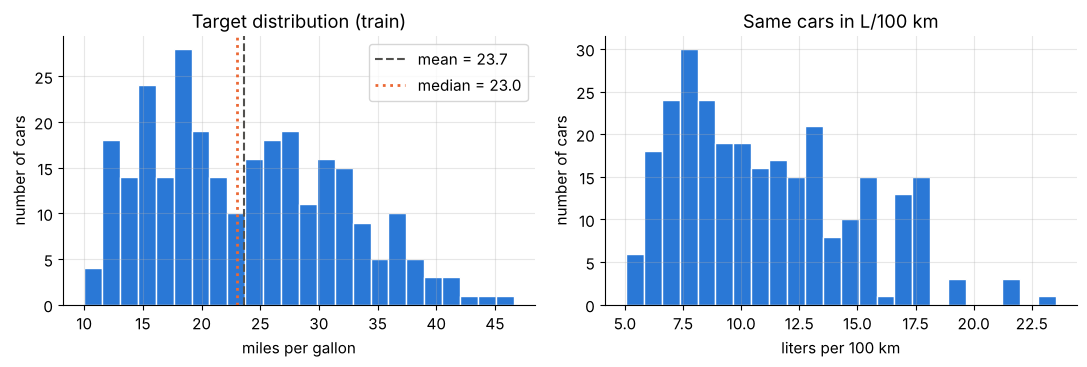

mean = 23.66 mpg, std = 7.84 mpg, skewness = 0.43


In [9]:
mpg = train_df["mpg"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(mpg, bins=24, color=C_TRAIN, edgecolor="white")
axes[0].axvline(mpg.mean(), color=C_INK, ls="--", lw=1.5, label=f"mean = {mpg.mean():.1f}")
axes[0].axvline(mpg.median(), color=C_VAL, ls=":", lw=2, label=f"median = {mpg.median():.1f}")
axes[0].set(xlabel="miles per gallon", ylabel="number of cars", title="Target distribution (train)")
axes[0].legend()
axes[1].hist(235.215 / mpg, bins=24, color=C_TRAIN, edgecolor="white")
axes[1].set(xlabel="liters per 100 km", ylabel="number of cars", title="Same cars in L/100 km")
plt.tight_layout()
plt.show()
print(f"mean = {mpg.mean():.2f} mpg, std = {mpg.std(ddof=0):.2f} mpg, skewness = {mpg.skew():.2f}")

MPG is **right-skewed** (a long tail of very efficient cars, positive skewness): the mean is
larger than the median. Converted to L/100 km the shape changes, because the reciprocal stretches
small MPG values and squeezes large ones. The scale on which a quantity is "nice" is not fixed by
nature, and we will exploit this in Section 5.

### 3.3 Feature distributions

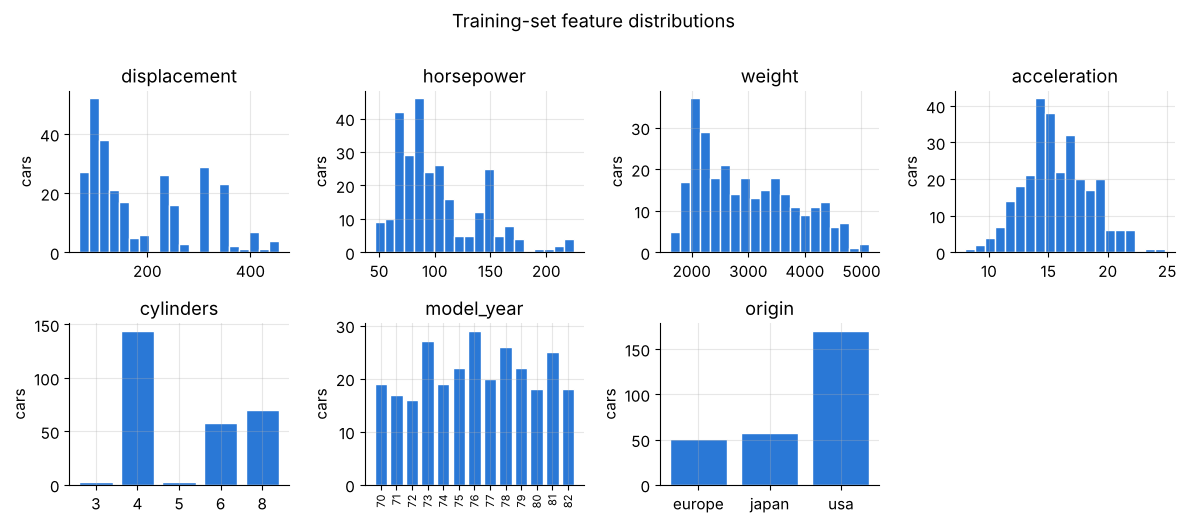

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(12, 5.2))
continuous = ["displacement", "horsepower", "weight", "acceleration"]
for ax, col in zip(axes[0], continuous):
    ax.hist(train_df[col].dropna(), bins=20, color=C_TRAIN, edgecolor="white")
    ax.set(title=col, ylabel="cars")
for ax, col in zip(axes[1, :3], ["cylinders", "model_year", "origin"]):
    counts = train_df[col].value_counts().sort_index()
    ax.bar(counts.index.astype(str), counts.values, color=C_TRAIN, edgecolor="white")
    ax.set(title=col, ylabel="cars")
    if col == "model_year":
        ax.tick_params(axis="x", labelsize=8, rotation=90)
axes[1, 3].axis("off")
fig.suptitle("Training-set feature distributions", y=1.0)
plt.tight_layout()
plt.show()

Things to notice: displacement, horsepower and weight are right-skewed, cylinder counts cluster
at 4, 6 and 8, model years are spread fairly evenly, and most cars are American.

### 3.4 Every feature against MPG

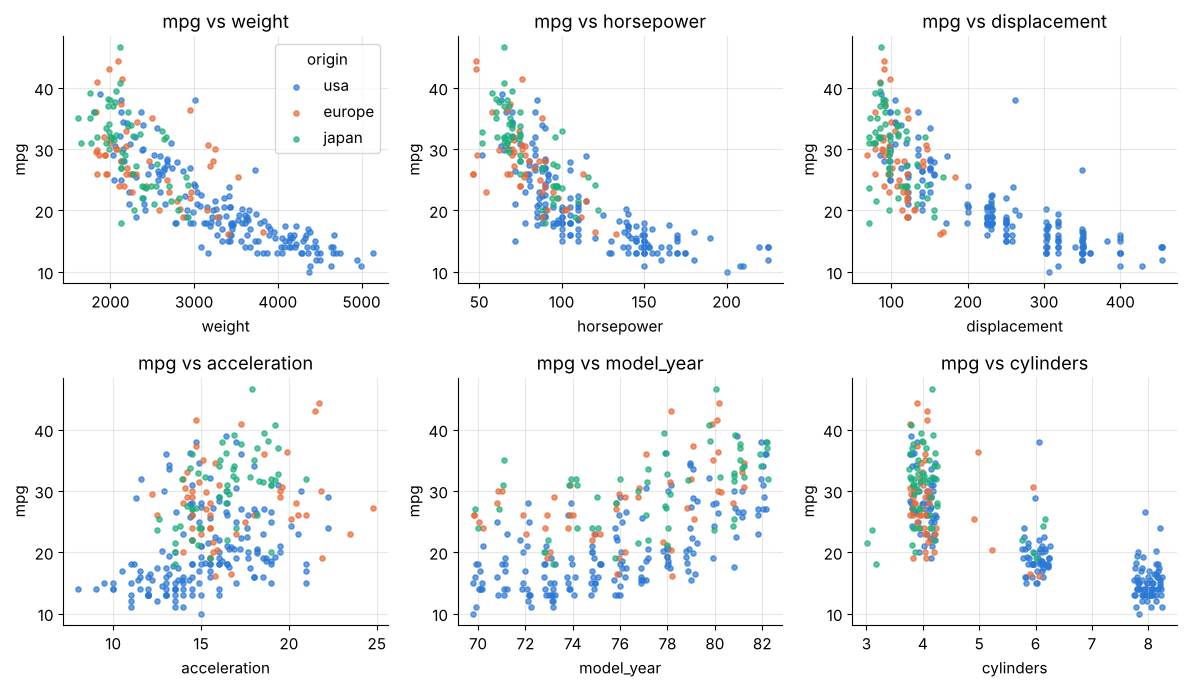

mean mpg by origin (train): {'europe': 28.12, 'japan': 30.14, 'usa': 20.15}


In [11]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, col in zip(axes.ravel(), ["weight", "horsepower", "displacement", "acceleration", "model_year", "cylinders"]):
    for origin, color in ORIGIN_COLORS.items():
        part = train_df[train_df["origin"] == origin]
        jitter = rng.uniform(-0.25, 0.25, len(part)) if col in ("model_year", "cylinders") else 0.0
        ax.scatter(part[col] + jitter, part["mpg"], s=14, alpha=0.7, color=color, label=origin)
    ax.set(xlabel=col, ylabel="mpg", title=f"mpg vs {col}")
axes[0, 0].legend(title="origin")
plt.tight_layout()
plt.show()
print("mean mpg by origin (train):", train_df.groupby("origin")["mpg"].mean().round(2).to_dict())

What the scatter plots say:

- **Heavier, more powerful, bigger-engine cars use more fuel.** The relationships are strong
  and clearly **curved**: MPG falls steeply at first, then flattens out.
- **Newer cars are more efficient.** After the 1973 oil crisis manufacturers improved engines,
  and U.S. fuel-economy standards took effect from the 1978 model year.
- **Origin matters**, but mostly through other features: Japanese and European cars are lighter
  on average. A scatter plot cannot separate "Japanese" from "light", but a model with all features can.
- `model_year` and `cylinders` take few distinct values, so we added a little horizontal
  **jitter** (random noise in the plot only) to keep the points from hiding behind each other.

### 3.5 Correlations

The **Pearson correlation** between two columns $u$ and $v$ with means $\bar u, \bar v$ is

$$
r_{uv} = \frac{\sum_i (u_i-\bar u)(v_i - \bar v)}{\sqrt{\sum_i (u_i-\bar u)^2}\,\sqrt{\sum_i (v_i-\bar v)^2}} \in [-1, 1].
$$

It measures how well a **straight line** describes the relationship: $r = \pm 1$ means the
points lie exactly on a line, $r = 0$ means no *linear* trend (there could still be a curved one).

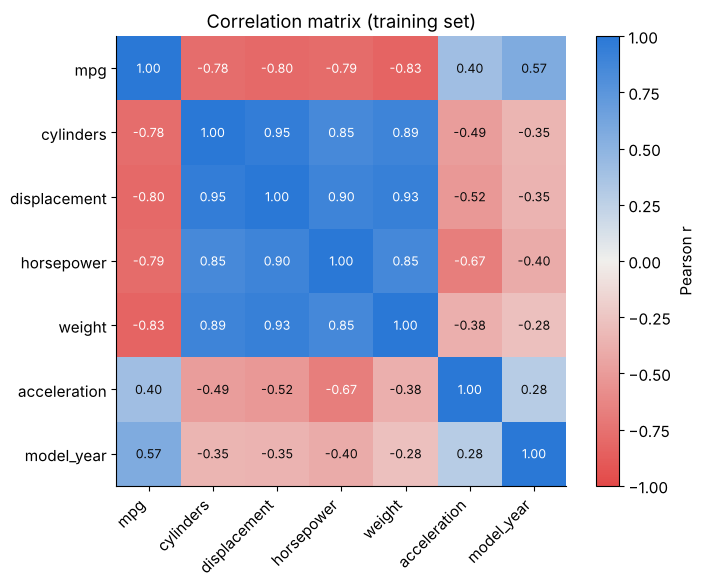

Correlation with mpg: {'weight': -0.829, 'displacement': -0.804, 'horsepower': -0.786, 'cylinders': -0.775, 'acceleration': 0.4, 'model_year': 0.569}


In [12]:
num_cols = ["mpg", "cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
corr = train_df[num_cols].corr()
div_cmap = LinearSegmentedColormap.from_list("red_gray_blue", ["#e34948", "#f0efec", "#2a78d6"])

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr.values, cmap=div_cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols)), num_cols, rotation=45, ha="right")
ax.set_yticks(range(len(num_cols)), num_cols)
ax.grid(False)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        r = corr.values[i, j]
        ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(r) > 0.6 else "#0b0b0b")
fig.colorbar(im, ax=ax, label="Pearson r")
ax.set_title("Correlation matrix (training set)")
plt.tight_layout()
plt.show()
print("Correlation with mpg:", corr["mpg"].drop("mpg").sort_values().round(3).to_dict())

Weight has the strongest (negative) correlation with MPG, followed by displacement, horsepower
and cylinders. Notice the dark-blue block: **weight, displacement, horsepower and cylinders are
all strongly correlated with each other** (|r| above 0.8). This is called **multicollinearity**.
It does not hurt predictions much, but it makes it hard to say which of these features "causes"
the effect, because the model can trade one for another. Remember this when we interpret feature
importances in Section 12.

### 3.6 The relationship is nonlinear

Let us look closer at MPG versus weight. A straight line fitted by least squares leaves residuals
with a clear **U-shape**: the line overestimates MPG for mid-weight cars and underestimates it at
both ends. Physics suggests a better scale: the fuel needed per mile is roughly proportional to
the work done per mile, which grows with the car's mass. So **gallons per 100 miles**
($=100/\text{MPG}$) should be roughly *linear* in weight, which makes MPG itself behave like
$1/\text{weight}$, a curve.

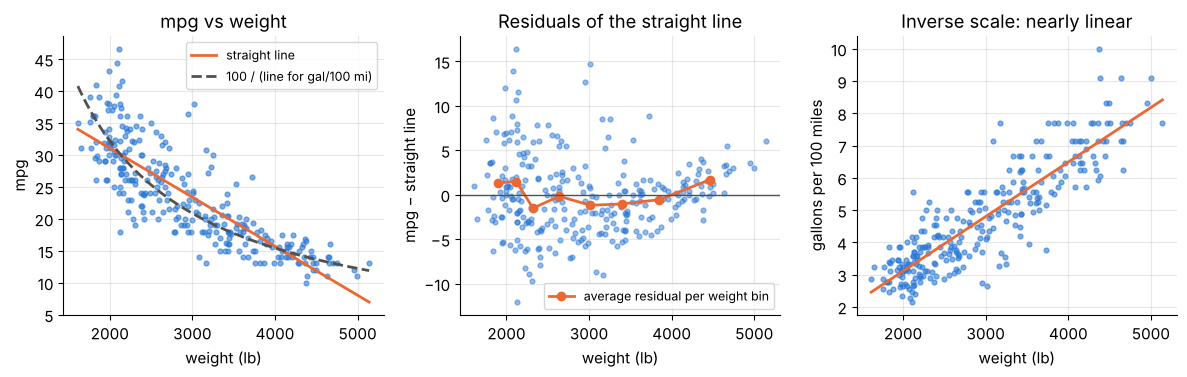

r(weight, mpg)                = -0.829
r(weight, gallons/100 mi)     = +0.881
r(horsepower, mpg)            = -0.786
r(horsepower, gallons/100 mi) = +0.860


In [13]:
w = train_df["weight"].to_numpy(float)
y_mpg = train_df["mpg"].to_numpy(float)
g100 = 100 / y_mpg                                  # gallons per 100 miles
grid_w = np.linspace(w.min(), w.max(), 100)

slope1, icpt1 = np.polyfit(w, y_mpg, deg=1)         # straight line for mpg
slope2, icpt2 = np.polyfit(w, g100, deg=1)          # straight line for gallons / 100 mi
resid = y_mpg - (slope1 * w + icpt1)
bins = np.quantile(w, np.linspace(0, 1, 9))
bin_id = np.clip(np.digitize(w, bins[1:-1]), 0, 7)
bin_mid = [w[bin_id == b].mean() for b in range(8)]
bin_res = [resid[bin_id == b].mean() for b in range(8)]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.9))
axes[0].scatter(w, y_mpg, s=12, alpha=0.6, color=C_TRAIN)
axes[0].plot(grid_w, slope1 * grid_w + icpt1, color=C_VAL, lw=2, label="straight line")
axes[0].plot(grid_w, 100 / (slope2 * grid_w + icpt2), color=C_INK, lw=2, ls="--", label="100 / (line for gal/100 mi)")
axes[0].set(xlabel="weight (lb)", ylabel="mpg", title="mpg vs weight")
axes[0].legend(fontsize=9)
axes[1].scatter(w, resid, s=12, alpha=0.5, color=C_TRAIN)
axes[1].plot(bin_mid, bin_res, "o-", color=C_VAL, lw=2, ms=6, label="average residual per weight bin")
axes[1].axhline(0, color=C_INK, lw=1)
axes[1].set(xlabel="weight (lb)", ylabel="mpg − straight line", title="Residuals of the straight line")
axes[1].legend(fontsize=9)
axes[2].scatter(w, g100, s=12, alpha=0.6, color=C_TRAIN)
axes[2].plot(grid_w, slope2 * grid_w + icpt2, color=C_VAL, lw=2)
axes[2].set(xlabel="weight (lb)", ylabel="gallons per 100 miles", title="Inverse scale: nearly linear")
plt.tight_layout()
plt.show()
print(f"r(weight, mpg)                = {np.corrcoef(w, y_mpg)[0, 1]:+.3f}")
print(f"r(weight, gallons/100 mi)     = {np.corrcoef(w, g100)[0, 1]:+.3f}")
known = train_df["horsepower"].notna().to_numpy()            # horsepower has 4 missing values here
hp_known = train_df["horsepower"].to_numpy(float)[known]
print(f"r(horsepower, mpg)            = {np.corrcoef(hp_known, y_mpg[known])[0, 1]:+.3f}")
print(f"r(horsepower, gallons/100 mi) = {np.corrcoef(hp_known, g100[known])[0, 1]:+.3f}")

The correlation strengthens from $|r| = 0.829$ to $|r| = 0.881$ on the inverse scale, and the
U-shaped residual pattern is exactly what a curved truth looks like through a straight-line lens.
Horsepower tells the same story: its correlation rises from $|r| = 0.786$ with MPG to
$|r| = 0.860$ with gallons per 100 miles (computed on the training cars whose horsepower is known).

This gives us two strategies:

1. **Engineer the nonlinearity by hand** (transform the target or the features), then use a
   linear model. This needs domain knowledge.
2. **Let the model learn the curve.** An MLP with nonlinear activations can approximate curved
   relationships automatically. This is the main reason to try a neural network here.

We will try both and compare them honestly.

> **Quick check.** Two features have correlation $r = 0$ with the target. Can we safely drop
> them?

<details>
<summary>Answer</summary>

No. $r = 0$ only rules out a *linear* trend. A feature with a U-shaped effect, such as $y = x^2$
for $x$ symmetric around 0, has $r = 0$ but determines $y$ perfectly. A feature can also matter
only in combination with another feature (an interaction). Correlation is a screening tool, not
a verdict.
</details>

---
## 4. Preprocessing: missing values, one-hot encoding, standardization

A neural network can only eat a **matrix of numbers with no holes**. Our table has a hole
(missing horsepower), a text column (`origin`) and numeric columns whose scales differ by a
factor of more than a hundred. This section fixes all three, guided by one rule:

> **Key idea.** Every number that preprocessing *learns* from data (a median, the list of
> categories, a mean, a standard deviation) is computed on the **training set only** and then
> *applied unchanged* to the validation set, the test set and every future car. This is the
> **fit / transform** pattern, and it is the main defense against **data leakage**: information
> from the evaluation data sneaking into the model and making scores look better than they are.

### 4.1 Missing horsepower: five options

| option | how it works | pros | cons |
|---|---|---|---|
| drop the rows | delete the cars without horsepower | trivial | throws data away, and a *new* car with unknown horsepower could get no prediction at all |
| global mean or median | fill every hole with one number from the training set | simple, and the median is robust to outliers | ignores everything else we know about the car |
| group median | fill with the training median of cars with the **same number of cylinders** | simple, and it uses a strongly related feature | small groups give shaky medians |
| regression imputation | predict horsepower from displacement, weight and cylinders with a small linear model | usually the most accurate | one more model to fit, store and maintain |
| missing-value indicator | add a 0/1 column "horsepower was missing" (on top of any fill) | lets the model treat filled rows differently | needs many missing rows to learn from, and we have 4 |

Rather than argue, let us **measure**. Take the training cars whose horsepower we *do* know,
hide 30 of those values, fill them with each method (fitted on the other cars only), and compare
the guesses with the hidden truth. Repeating this 200 times with different hidden sets gives a
reliable average error. This *mask-and-recover* trick is a general way to choose an imputation
method, and it uses only the training set.

In [14]:
def compare_imputers(df: pd.DataFrame, n_hide: int = 30, n_repeats: int = 200, seed: int = SEED) -> pd.DataFrame:
    """Hide known horsepower values, impute them with several methods, report the mean absolute error."""
    g = np.random.default_rng(seed)
    known = df[df["horsepower"].notna()]
    predictors = ["displacement", "weight", "cylinders"]
    errors = {"global mean": [], "global median": [], "median by cylinders": [], "regression": []}
    for _ in range(n_repeats):
        hidden_mask = np.zeros(len(known), dtype=bool)
        hidden_mask[g.choice(len(known), size=n_hide, replace=False)] = True
        fit_part, hidden = known[~hidden_mask], known[hidden_mask]
        truth = hidden["horsepower"].to_numpy()
        group_medians = fit_part.groupby("cylinders")["horsepower"].median()
        guesses = {
            "global mean": np.full(n_hide, fit_part["horsepower"].mean()),
            "global median": np.full(n_hide, fit_part["horsepower"].median()),
            "median by cylinders": hidden["cylinders"].map(group_medians)
                                   .fillna(fit_part["horsepower"].median()).to_numpy(),
            "regression": LinearRegression().fit(fit_part[predictors], fit_part["horsepower"])
                          .predict(hidden[predictors]),
        }
        for method, guess in guesses.items():
            errors[method].append(np.mean(np.abs(truth - guess)))
    return pd.DataFrame({"mean abs error (hp)": {m: np.mean(e) for m, e in errors.items()},
                         "std over repeats": {m: np.std(e) for m, e in errors.items()}})


imputer_errors = compare_imputers(train_df)
display(imputer_errors.round(2))
print(f"training horsepower: mean = {train_df['horsepower'].mean():.1f}, median = {train_df['horsepower'].median():.1f}")

,mean abs error (hp),std over repeats
global mean,28.91,3.34
global median,27.45,4.12
median by cylinders,12.75,2.32
regression,11.76,2.06


training horsepower: mean = 102.6, median = 91.5


A single global number misses the true horsepower by roughly 27–29 hp on average, while the
median *within the same cylinder group* misses by about 13 hp. The regression imputer is only
about 1 hp better than that. We choose the **median by cylinders**: nearly as accurate as
regression, trivial to store (one number per cylinder count) and hard to break. We use the
median rather than the mean because horsepower is right-skewed (its training mean is above its
median, as printed above), and a few very powerful cars should not drag the fill value upward.

Here are the medians learned from the training set, and the values they give the four training
cars with missing horsepower:

In [15]:
hp_by_cyl = train_df.groupby("cylinders")["horsepower"].agg(["count", "median"])
display(hp_by_cyl.T)
missing_train = train_df[train_df["horsepower"].isna()]
display(missing_train[["name", "cylinders", "displacement", "weight"]]
        .assign(filled_horsepower=missing_train["cylinders"].map(hp_by_cyl["median"])))

cylinders,3,4,5,6,8
count,3.0,140.0,3.0,58.0,70.0
median,100.0,75.0,77.0,100.0,150.0


,name,cylinders,displacement,weight,filled_horsepower
32,ford pinto,4,98.0,2046,75.0
330,renault lecar deluxe,4,85.0,1835,75.0
374,amc concord dl,4,151.0,3035,75.0
354,renault 18i,4,100.0,2320,75.0


Note the `count` row: the 3- and 5-cylinder medians rest on only 3 cars each. That is a real
weakness of group statistics, but here no car with a missing value belongs to those groups.

### 4.2 One-hot encoding `origin`

Why not simply code `usa = 0`, `europe = 1`, `japan = 2`? Because a model reads codes as
*numbers*: it would assume Europe lies "between" the USA and Japan, and that the step from USA to
Japan is twice the step from USA to Europe. Those claims are artifacts of an arbitrary labeling.
**One-hot encoding** instead creates one 0/1 column per category:

| origin | `origin_europe` | `origin_japan` | `origin_usa` |
|---|---|---|---|
| usa | 0 | 0 | 1 |
| europe | 1 | 0 | 0 |
| japan | 0 | 1 | 0 |

Each column answers a yes/no question, with no fake ordering. The list of categories (and its
order) is learned from the training set and then **frozen**, because the trained network expects
input column 7 to mean the same thing forever.

> **Common pitfall.** `pd.get_dummies` only creates columns for the categories *present in the
> data you hand it*. Called on a single new car, it returns one column instead of three, and the
> network would receive a wrongly shaped input:

In [16]:
one_car = raw.iloc[[0]]                     # a single (American) car
print("pd.get_dummies on one car ->", list(pd.get_dummies(one_car["origin"]).columns))

ORIGINS = sorted(train_df["origin"].unique())          # learned from the training set, then frozen
fixed = pd.DataFrame({f"origin_{c}": (one_car["origin"] == c).astype(float) for c in ORIGINS})
print("fixed category list       ->", list(fixed.columns), fixed.to_numpy().ravel())

pd.get_dummies on one car -> ['usa']
fixed category list       -> ['origin_europe', 'origin_japan', 'origin_usa'] [0. 0. 1.]


> **Going deeper: the dummy-variable trap.** The three one-hot columns always add up to 1,
> exactly like an intercept column of ones. For *linear regression* this means the coefficients
> are not unique (perfect multicollinearity): adding 5 to all three origin coefficients and
> subtracting 5 from the intercept gives identical predictions. The usual fixes are to drop one
> column (`drop="first"` in scikit-learn's `OneHotEncoder`) or to use a least-squares solver
> that copes with redundancy (Section 5 does the latter). A neural network does not mind: the
> redundancy just means many equivalent parameter settings.

### 4.3 Standardization

For each of the 9 feature columns $j$ we compute, **on training cars only**, the mean and the
standard deviation

$$
\mu_j = \frac{1}{n}\sum_{i=1}^{n} x_{ij}, \qquad
\sigma_j = \sqrt{\frac{1}{n}\sum_{i=1}^{n} (x_{ij}-\mu_j)^2},
$$

where $n = 278$ is the number of training cars and $x_{ij}$ is feature $j$ of car $i$. Then every
car, from any split, is transformed as

$$
z_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j}.
$$

After this, each training column has mean 0 and standard deviation 1, and a value of $z = +2$
means "two training standard deviations above the average training car".

**Why bother?** Three reasons:

1. **Gradient descent hates elongated valleys.** For a linear model trained with MSE, the loss
   is a bowl whose curvature along each direction is an eigenvalue of the Hessian matrix
   $H = \tfrac{2}{n} A^\top A$, where $A \in \mathbb{R}^{n \times (d+1)}$ is the feature
   matrix with a column of ones prepended. Gradient descent with learning rate $\eta$ is stable
   only if $\eta < 2/\lambda_{\max}$, and it needs roughly $\kappa = \lambda_{\max}/\lambda_{\min}$
   steps (the **condition number**) to crawl along the flattest direction. Let us measure
   $\kappa$ for the six numeric features, raw and standardized.
2. **Default weight initialization assumes inputs of order 1.** PyTorch draws initial weights
   so that a layer's outputs have a sensible scale when its inputs do. A raw weight of 3,500 lb
   breaks that assumption immediately.
3. **One learning rate must fit all weights.** If one input is in the thousands and another in
   the tens, the same step size is far too big for one weight and far too small for the other.

In [17]:
def hessian_spectrum(features: np.ndarray) -> tuple[float, float, float]:
    """Eigenvalues of the MSE Hessian (2/n) A^T A for a linear model with intercept."""
    A = np.c_[np.ones(len(features)), features]
    eigenvalues = np.linalg.eigvalsh(2.0 / len(A) * A.T @ A)
    return eigenvalues.min(), eigenvalues.max(), eigenvalues.max() / eigenvalues.min()


NUMERIC = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]

numeric_raw = train_df[NUMERIC].astype(float)
numeric_raw["horsepower"] = numeric_raw["horsepower"].fillna(train_df["cylinders"].map(hp_by_cyl["median"]))
numeric_std = StandardScaler().fit_transform(numeric_raw)
for label, feats in [("raw", numeric_raw.to_numpy()), ("standardized", numeric_std)]:
    lam_min, lam_max, kappa = hessian_spectrum(feats)
    print(f"{label:>12}: lambda_min = {lam_min:.4g}, lambda_max = {lam_max:.4g}, "
          f"condition number = {kappa:.3g}, largest stable GD step 2/lambda_max = {2 / lam_max:.3g}")

         raw: lambda_min = 0.002506, lambda_max = 1.911e+07, condition number = 7.62e+09, largest stable GD step 2/lambda_max = 1.05e-07
standardized: lambda_min = 0.07328, lambda_max = 8.422, condition number = 115, largest stable GD step 2/lambda_max = 0.237


With raw features the largest stable learning rate is about $10^{-7}$ (set by the huge `weight`
column), yet the flattest direction has a curvature of only about $0.0025$: plain gradient
descent would need billions of steps. Standardizing shrinks the condition number from about
7.6 billion to about 115. The remaining factor of about 115 comes from **multicollinearity**:
cylinders, displacement, horsepower and weight carry almost the same information (Section 3.5),
which leaves one direction of the bowl very flat. Section 10 shows what happens when we train
the MLP on unscaled features.

> **Common pitfall.** Fitting the scaler on *all* the data (or separately on each split) is
> leakage. Validation and test cars must be transformed with the **training** $\mu_j$ and
> $\sigma_j$, exactly as a car that rolls off the assembly line next year would be.

### 4.4 Putting it together: a reusable preprocessor

We bundle the three steps into one small class with the scikit-learn style `fit` / `transform`
interface. `fit` is called **once**, on the training set, and `transform` can then be applied to any
rows, including a single new car (Section 13). Also notice how `NUMERIC` and the frozen category
list fix the column order of the 9 features.

In [18]:
class AutoMPGPreprocessor:
    """Raw Auto MPG rows -> standardized float32 feature matrix of shape (n, 9).

    fit(df) learns, from the TRAINING rows only:
      * the median horsepower per cylinder count, plus a global median as a fallback,
      * the list of origin categories (fixes the one-hot columns and their order),
      * the mean and standard deviation of each of the 9 feature columns.
    transform(df) applies exactly those numbers to any rows.
    """

    def fit(self, df: pd.DataFrame) -> "AutoMPGPreprocessor":
        self.hp_median_by_cyl_ = df.groupby("cylinders")["horsepower"].median().to_dict()
        self.hp_median_ = float(df["horsepower"].median())
        self.origins_ = sorted(df["origin"].unique())
        features = self.features(df)                  # imputed + one-hot, not yet scaled
        self.feature_names_ = list(features.columns)
        self.scaler_ = StandardScaler().fit(features.to_numpy())
        return self

    def features(self, df: pd.DataFrame) -> pd.DataFrame:
        """Impute horsepower and one-hot encode origin (no scaling yet)."""
        unknown = set(df["origin"]) - set(self.origins_)
        if unknown:
            raise ValueError(f"unknown origin(s) {sorted(unknown)}: expected one of {self.origins_}")
        X = df[NUMERIC].astype(float)                 # astype returns a copy: df is untouched
        fill = df["cylinders"].map(self.hp_median_by_cyl_).fillna(self.hp_median_)
        X["horsepower"] = X["horsepower"].fillna(fill)
        for c in self.origins_:
            X[f"origin_{c}"] = (df["origin"] == c).astype(float)
        return X

    def transform(self, df: pd.DataFrame) -> np.ndarray:
        """Return the standardized (n, 9) float32 matrix."""
        return self.scaler_.transform(self.features(df).to_numpy()).astype(np.float32)


prep = AutoMPGPreprocessor().fit(train_df)          # learns from the training set ONLY
X_train, X_val, X_test = (prep.transform(d) for d in (train_df, val_df, test_df))
y_train, y_val, y_test = (d["mpg"].to_numpy(dtype=np.float32) for d in (train_df, val_df, test_df))
N_FEATURES = X_train.shape[1]

print("feature order:", prep.feature_names_)
print(f"X_train {X_train.shape} {X_train.dtype} | X_val {X_val.shape} | X_test {X_test.shape} | "
      f"y_train {y_train.shape} {y_train.dtype}")
print("any missing values left?", any(np.isnan(X).any() for X in (X_train, X_val, X_test)))

feature order: ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin_europe', 'origin_japan', 'origin_usa']
X_train (278, 9) float32 | X_val (80, 9) | X_test (40, 9) | y_train (278,) float32
any missing values left? False


A quick sanity check: after the transform, the training columns should have mean 0 and standard
deviation 1. Validation and test columns should be *close* to that but not exact: they are
different cars, transformed with the training statistics.

In [19]:
check = pd.DataFrame({
    "train mean": X_train.mean(axis=0), "train std": X_train.std(axis=0),
    "val mean": X_val.mean(axis=0), "test mean": X_test.mean(axis=0),
}, index=prep.feature_names_)
display(check.round(3))
usa_col = prep.feature_names_.index("origin_usa")
print("standardized origin_usa takes only the values", np.unique(X_train[:, usa_col]).round(2))

,train mean,train std,val mean,test mean
cylinders,-0.0,1.0,0.074,0.030
displacement,-0.0,1.0,0.084,0.087
horsepower,0.0,1.0,0.186,0.133
weight,0.0,1.0,0.016,0.062
acceleration,0.0,1.0,-0.152,-0.184
model_year,-0.0,1.0,-0.140,-0.081
origin_europe,0.0,1.0,-0.022,-0.151
origin_japan,-0.0,1.0,-0.105,0.049
origin_usa,0.0,1.0,0.105,0.079


standardized origin_usa takes only the values [-1.25  0.8 ]


Exactly as expected. Notice the one-hot columns: after standardization each still takes just
two values (printed above for `origin_usa`), so it carries exactly the same information as 0/1.

> **Quick check.** Why is the training standard deviation of every column exactly 1, but the
> validation means are not exactly 0?

<details>
<summary>Answer</summary>

The scaler's $\mu_j$ and $\sigma_j$ were computed *from the training rows*, so by construction
those rows end up with mean 0 and standard deviation 1. The validation rows are different cars
with their own averages, and subtracting the *training* mean leaves a small offset. If the validation
means were exactly 0, that would be a red flag that the scaler had been fitted on validation data.
</details>

### ✏️ Exercise 2: group-median imputation without leakage

Write `impute_group_median(fit_df, apply_df, col, group_col)`. It returns a **new** Series:
`apply_df[col]` with its missing values filled by the median of `col` among the rows of
`fit_df` that share the same `group_col` value. If a group does not appear in `fit_df` (or all
its values there are missing), use the overall median of `fit_df[col]`. The medians must come
from `fit_df` only, and neither input may be modified.

In [20]:
# ✏️ Exercise 2: group-median imputation without leakage
def impute_group_median(fit_df: pd.DataFrame, apply_df: pd.DataFrame, col: str, group_col: str) -> pd.Series:
    """Fill missing apply_df[col] values with group medians learned from fit_df."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex2():
    fit = pd.DataFrame({"g": [1, 1, 1, 2, 2, 3], "v": [10.0, 20.0, 90.0, 5.0, np.nan, np.nan]})
    app = pd.DataFrame({"g": [1, 2, 3, 4, 1], "v": [np.nan, np.nan, np.nan, np.nan, 7.0]},
                       index=[10, 11, 12, 13, 14])
    before = app.copy()
    out = impute_group_median(fit, app, "v", "g")
    assert isinstance(out, pd.Series), "return a pandas Series"
    assert list(out.index) == [10, 11, 12, 13, 14], "keep the index of apply_df"
    # group 1 -> 20, group 2 -> 5, group 3 (only missing values) and group 4 (unseen) -> overall median 15
    expected = [20.0, 5.0, 15.0, 15.0, 7.0]
    assert np.allclose(out.to_numpy(dtype=float), expected), f"got {out.tolist()}, expected {expected}"
    assert app.equals(before), "apply_df was modified in place"
    app2 = app.copy()
    app2.loc[14, "v"] = 1000.0                     # a huge value in apply_df must not change any fill
    assert impute_group_median(fit, app2, "v", "g").loc[10] == 20.0, "medians must come from fit_df only"
    real = impute_group_median(train_df, val_df, "horsepower", "cylinders")
    assert real.notna().all() and real.loc[126] == 100.0, "on the real data the 6-cylinder Ford Maverick should get 100 hp"


run_check("Exercise 2", _test_ex2)

⏳ Exercise 2: not implemented yet. Fill in the function and re-run this cell.

<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def impute_group_median(fit_df, apply_df, col, group_col):
    medians = fit_df.groupby(group_col)[col].median()          # learned from fit_df only
    overall = fit_df[col].median()
    fill = apply_df[group_col].map(medians).fillna(overall)    # NaN for unseen or empty groups
    return apply_df[col].fillna(fill)                          # fillna returns a new Series
```
`map` looks up each row's group in the table of medians, and groups that are missing from it (or
whose median is NaN) become NaN and fall back to the overall median. Only missing entries of
`apply_df[col]` are replaced, because `fillna` leaves existing values alone.
</details>

### ✏️ Exercise 3: one-hot encoding with a frozen category list

Write `one_hot_fixed(values, categories, prefix)` that turns a Series of category labels into a
DataFrame with **exactly one float column per entry of `categories`**, named
`f"{prefix}_{category}"`, in the given order, with the same index as `values`. A label that is not
in `categories` gets all zeros. (Our preprocessor raises an error instead. Both policies are
defensible: zeros say "none of the known regions", an error says "refuse to guess".)

In [21]:
# ✏️ Exercise 3: one-hot encoding with a frozen category list
def one_hot_fixed(values: pd.Series, categories: list[str], prefix: str) -> pd.DataFrame:
    """One-hot encode `values` with a fixed list of categories."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex3():
    cats = ["europe", "japan", "usa"]
    out = one_hot_fixed(pd.Series(["japan"], index=[7]), cats, "origin")
    assert list(out.columns) == ["origin_europe", "origin_japan", "origin_usa"], f"columns {list(out.columns)}"
    assert list(out.index) == [7], "keep the index"
    assert out.to_numpy().tolist() == [[0.0, 1.0, 0.0]], f"got {out.to_numpy().tolist()}"
    assert all(pd.api.types.is_float_dtype(dt) for dt in out.dtypes), \
        f"columns must have a float dtype, got {[str(dt) for dt in out.dtypes]}"
    out2 = one_hot_fixed(pd.Series(["usa", "mars", "europe"]), cats, "o")
    assert out2.to_numpy().tolist() == [[0, 0, 1], [0, 0, 0], [1, 0, 0]], "unknown labels must give all zeros"
    full = one_hot_fixed(train_df["origin"], cats, "origin")
    assert np.allclose(full.sum(axis=1), 1.0), "every training car belongs to exactly one known origin"


run_check("Exercise 3", _test_ex3)

⏳ Exercise 3: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def one_hot_fixed(values, categories, prefix):
    return pd.DataFrame(
        {f"{prefix}_{c}": (values == c).astype(float) for c in categories},
        index=values.index,
    )
```
Comparing the whole Series with one category at a time gives a boolean column, and `astype(float)`
turns it into 0.0/1.0. Because the loop runs over the *fixed* list, the output always has the same
columns in the same order, no matter which labels happen to be present.
</details>

---
## 5. Metrics and baselines: what an MLP has to beat

Before building anything fancy, decide **how to score** a model and **what score a simple model
already achieves**. Without a baseline, "validation $R^2 = 0.88$" means nothing: is that great,
or what a one-line formula gets?

### 5.1 Four ways to score a regression model

For $n$ cars with true values $y_i$ and predictions $\hat y_i$:

$$
\text{MSE} = \frac1n\sum_{i=1}^n (y_i-\hat y_i)^2, \qquad
\text{RMSE} = \sqrt{\text{MSE}}, \qquad
\text{MAE} = \frac1n\sum_{i=1}^n |y_i-\hat y_i|,
$$

$$
R^2 = 1-\frac{SS_\text{res}}{SS_\text{tot}}, \qquad
SS_\text{res}=\sum_{i=1}^n (y_i-\hat y_i)^2, \qquad
SS_\text{tot}=\sum_{i=1}^n (y_i-\bar y)^2, \qquad \bar y = \frac1n\sum_{i=1}^n y_i .
$$

| metric | units | reads as | notes |
|---|---|---|---|
| MSE | mpg² | average squared miss | what we *train* on: smooth and easy to differentiate |
| RMSE | mpg | "typical" miss | same units as the target, and it punishes big misses more than MAE |
| MAE | mpg | average miss | robust: one terrible prediction cannot dominate it |
| $R^2$ | none | fraction of the target's variance explained | 1 is perfect, 0 is "as good as predicting the mean" |

Dividing numerator and denominator of the $R^2$ fraction by $n$ shows
$R^2 = 1 - \text{MSE}/\sigma_y^2$, where $\sigma_y^2 = SS_\text{tot}/n$ is the variance of the
true values: $R^2$ is just the MSE measured in units of the target's variance.

**A worked example by hand.** Four cars, true MPG and predictions:

| car | $y$ | $\hat y$ | $y-\hat y$ | $(y-\hat y)^2$ | $\lvert y-\hat y\rvert$ | $y-\bar y$ | $(y-\bar y)^2$ |
|---|---|---|---|---|---|---|---|
| A | 15 | 17 | −2 | 4 | 2 | −10 | 100 |
| B | 20 | 19 | 1 | 1 | 1 | −5 | 25 |
| C | 30 | 27 | 3 | 9 | 3 | 5 | 25 |
| D | 35 | 36 | −1 | 1 | 1 | 10 | 100 |
| **sum** | 100 | | | **15** | **7** | | **250** |

So $\bar y = 100/4 = 25$, $\text{MSE} = 15/4 = 3.75$, $\text{RMSE} = \sqrt{3.75} \approx 1.936$,
$\text{MAE} = 7/4 = 1.75$ and $R^2 = 1 - 15/250 = 0.94$. Let us code the four metrics from scratch
and check them against scikit-learn.

In [22]:
def mse(y_true, y_pred) -> float:
    y_true, y_pred = np.asarray(y_true, dtype=np.float64), np.asarray(y_pred, dtype=np.float64)
    return float(np.mean((y_true - y_pred) ** 2))


def rmse(y_true, y_pred) -> float:
    return math.sqrt(mse(y_true, y_pred))


def mae(y_true, y_pred) -> float:
    y_true, y_pred = np.asarray(y_true, dtype=np.float64), np.asarray(y_pred, dtype=np.float64)
    return float(np.mean(np.abs(y_true - y_pred)))


def r2_score_np(y_true, y_pred) -> float:
    """Coefficient of determination R^2 = 1 - SS_res / SS_tot (computed in float64)."""
    y_true, y_pred = np.asarray(y_true, dtype=np.float64), np.asarray(y_pred, dtype=np.float64)
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    return float(1.0 - ss_res / ss_tot)


y_toy, p_toy = np.array([15, 20, 30, 35]), np.array([17, 19, 27, 36])
print(f"ours:         MSE = {mse(y_toy, p_toy):.4f}  RMSE = {rmse(y_toy, p_toy):.4f}  "
      f"MAE = {mae(y_toy, p_toy):.4f}  R2 = {r2_score_np(y_toy, p_toy):.4f}")
print(f"scikit-learn: MSE = {mean_squared_error(y_toy, p_toy):.4f}  RMSE = {math.sqrt(mean_squared_error(y_toy, p_toy)):.4f}  "
      f"MAE = {mean_absolute_error(y_toy, p_toy):.4f}  R2 = {r2_score(y_toy, p_toy):.4f}")

ours:         MSE = 3.7500  RMSE = 1.9365  MAE = 1.7500  R2 = 0.9400
scikit-learn: MSE = 3.7500  RMSE = 1.9365  MAE = 1.7500  R2 = 0.9400


### 5.2 Reading $R^2$: constant predictions and negative scores

What $R^2$ does a model get if it ignores the input and always predicts the same number $c$?
Write $y_i - c = (y_i - \bar y) + (\bar y - c)$ and expand the square:

$$
SS_\text{res} = \sum_i (y_i - c)^2
= \underbrace{\sum_i (y_i-\bar y)^2}_{SS_\text{tot}}
+ 2(\bar y - c)\underbrace{\sum_i (y_i - \bar y)}_{=\,0}
+ n(\bar y - c)^2 .
$$

Therefore

$$
R^2_\text{constant} = 1 - \frac{SS_\text{tot} + n(\bar y - c)^2}{SS_\text{tot}}
= -\left(\frac{\bar y - c}{\sigma_y}\right)^2 .
$$

Three consequences worth memorizing:

1. Predicting the mean of the **evaluated** set ($c = \bar y$) gives exactly $R^2 = 0$.
2. Any other constant gives a **negative** $R^2$: there is no lower limit.
3. A constant that is $k$ standard deviations away from the mean scores $R^2 = -k^2$. Keep this
   in mind: it will explain a very strange number at the start of training in Section 9.

> **Common pitfall.** On validation or test data, $\bar y$ is the mean of *those* cars. A model
> that predicts the *training* mean therefore scores slightly below 0 there, even though it is a
> perfectly sensible baseline.

### 5.3 Baseline 1: always predict the training mean

In [23]:
def scores(y_true, y_pred) -> dict:
    """All four metrics in one dictionary."""
    return {"R2": r2_score_np(y_true, y_pred), "RMSE": rmse(y_true, y_pred), "MAE": mae(y_true, y_pred)}


train_mean = float(np.mean(y_train, dtype=np.float64))
baseline_rows = {
    ("predict the training mean", "train"): scores(y_train, np.full_like(y_train, train_mean)),
    ("predict the training mean", "val"): scores(y_val, np.full_like(y_val, train_mean)),
}
display(pd.DataFrame(baseline_rows).T.round(4))
k = (y_val.mean() - train_mean) / y_val.std()
print(f"formula check on validation: -(ybar_val - c)^2 / sigma^2 = {-k ** 2:.4f}")

R2    RMSE     MAE
predict the training mean train -0.0000  7.8359  6.6593
                          val   -0.0049  7.3506  5.9579

formula check on validation: -(ybar_val - c)^2 / sigma^2 = -0.0049


The training-mean predictor scores $R^2 = 0$ on the training set and slightly below 0 on
validation, exactly as the formula says. Its RMSE (about 7.35 mpg on validation) is the error to
beat. Any useful model must do *much* better.

### 5.4 Baseline 2: linear regression in closed form

A linear model predicts

$$
\hat y = \theta_0 + \theta_1 z_1 + \dots + \theta_9 z_9 = \mathbf{a}^\top \boldsymbol\theta,
\qquad \mathbf{a} = (1, z_1, \dots, z_9)^\top \in \mathbb{R}^{10},\;
\boldsymbol\theta \in \mathbb{R}^{10}.
$$

Stacking all training cars as rows gives the design matrix $A \in \mathbb{R}^{278 \times 10}$
(a column of ones followed by the 9 standardized features) and the target vector
$\mathbf{y} \in \mathbb{R}^{278}$. Minimizing the sum of squared errors
$\lVert A\boldsymbol\theta - \mathbf{y}\rVert^2$ means setting its gradient
$2A^\top(A\boldsymbol\theta - \mathbf{y})$ to zero, which gives the **normal equations**

$$
A^\top A\,\boldsymbol\theta = A^\top \mathbf{y}.
$$

If $A^\top A$ is invertible, $\boldsymbol\theta = (A^\top A)^{-1}A^\top\mathbf{y}$. But here it
is **not**: the dummy-variable trap (Section 4.2) makes one column of $A$ a combination of the
others. `np.linalg.lstsq` handles this gracefully: among all minimizers it returns the one with
the smallest $\lVert\boldsymbol\theta\rVert$. Every minimizer gives the same predictions.

In [24]:
A_train = np.c_[np.ones(len(X_train)), X_train].astype(np.float64)
A_val = np.c_[np.ones(len(X_val)), X_val].astype(np.float64)
print(f"A_train shape {A_train.shape}, rank {np.linalg.matrix_rank(A_train)} "
      f"-> A^T A is singular (condition number {np.linalg.cond(A_train.T @ A_train):.1e})")

theta, *_ = np.linalg.lstsq(A_train, y_train.astype(np.float64), rcond=None)
pred_lin_train, pred_lin_val = A_train @ theta, A_val @ theta

sk_lin = LinearRegression().fit(X_train, y_train)               # scikit-learn's version
print("same predictions as scikit-learn:", np.allclose(pred_lin_val, sk_lin.predict(X_val), atol=1e-3))

coef = pd.Series(theta[1:], index=prep.feature_names_)
print(f"intercept theta_0 = {theta[0]:.3f} (= training mean mpg, because every feature has training mean 0)")
display(coef.to_frame("coefficient (mpg per training std)").T.round(3))
print("linear regression:", {k: round(v, 4) for k, v in scores(y_val, pred_lin_val).items()}, "(validation)")

A_train shape (278, 10), rank 9 -> A^T A is singular (condition number 1.6e+15)
same predictions as scikit-learn: True
intercept theta_0 = 23.657 (= training mean mpg, because every feature has training mean 0)


,cylinders,displacement,horsepower,weight,acceleration,model_year,origin_europe,origin_japan,origin_usa
coefficient (mpg per training std),-0.381,2.295,-1.217,-5.685,-0.011,2.912,0.518,0.374,-0.721


linear regression: {'R2': 0.8424, 'RMSE': 2.9113, 'MAE': 2.3261} (validation)


The linear model explains most of the variance: validation $R^2$ above 0.84, and an RMSE about 60%
smaller than the mean predictor's. The coefficients tell a sensible but *fragile* story. Weight and
model year have large, intuitive effects (heavier is worse, newer is better). But displacement
gets a *positive* coefficient although bigger engines obviously burn more fuel. That is the
multicollinearity from Section 3.5 at work: displacement, cylinders, horsepower and weight are
so strongly correlated that the model can trade one for another, and individual coefficients stop
meaning "the effect of this feature". Do not read causal stories into such coefficients.

### 5.5 Baseline 3: linear regression with a physics-inspired target

Section 3.6 suggested that **gallons per 100 miles** ($g = 100/\text{mpg}$) is nearly linear in
weight. So fit the linear model to $g$ instead, and convert its predictions back with
$\widehat{\text{mpg}} = 100/\hat g$. Scores are always computed on the **mpg** scale so that all
models are compared fairly.

In [25]:
g_train = 100.0 / y_train.astype(np.float64)
theta_g, *_ = np.linalg.lstsq(A_train, g_train, rcond=None)
pred_gal_train, pred_gal_val = 100.0 / (A_train @ theta_g), 100.0 / (A_val @ theta_g)
print("linear on gallons/100 mi:", {k: round(v, 4) for k, v in scores(y_val, pred_gal_val).items()}, "(validation)")

linear on gallons/100 mi: {'R2': 0.8819, 'RMSE': 2.5202, 'MAE': 1.8745} (validation)


Using the right *scale* for the target lifts validation $R^2$ by about 0.04 and cuts RMSE
noticeably, with no extra parameters. That is domain knowledge at work.

> **Going deeper.** Converting back with $100/\hat g$ is a nonlinear transformation, so even if
> $\hat g$ were an unbiased estimate of $g$, $100/\hat g$ would be a slightly biased estimate of
> mpg (Jensen's inequality: the average of $1/g$ is not $1$ over the average of $g$). With small
> errors the bias is tiny, and statisticians correct it with a "smearing" estimator when it matters.

### 5.6 The scoreboard

Here is what the MLP has to beat. Test-set scores are deliberately **not** computed yet: the test
set stays locked until Section 12.

In [26]:
scoreboard = pd.DataFrame({
    "train R2": [r2_score_np(y_train, np.full_like(y_train, train_mean)),
                 r2_score_np(y_train, pred_lin_train), r2_score_np(y_train, pred_gal_train)],
    "val R2": [r2_score_np(y_val, np.full_like(y_val, train_mean)),
               r2_score_np(y_val, pred_lin_val), r2_score_np(y_val, pred_gal_val)],
    "val RMSE": [rmse(y_val, np.full_like(y_val, train_mean)), rmse(y_val, pred_lin_val), rmse(y_val, pred_gal_val)],
    "val MAE": [mae(y_val, np.full_like(y_val, train_mean)), mae(y_val, pred_lin_val), mae(y_val, pred_gal_val)],
}, index=["mean predictor", "linear regression", "linear on gallons/100 mi"])
display(scoreboard.round(4))

,train R2,val R2,val RMSE,val MAE
mean predictor,-0.0000,-0.0049,7.3506,5.9579
linear regression,0.8255,0.8424,2.9113,2.3261
linear on gallons/100 mi,0.8613,0.8819,2.5202,1.8745


> **Key idea.** A neural network is worth its extra complexity only if it clearly beats the
> strongest simple baseline, here the physics-inspired linear model, *on data it was not tuned on*.

> **Quick check.** A model scores $R^2 = -3$ on the validation set. What does that mean?

<details>
<summary>Answer</summary>

Its squared error is $1 - (-3) = 4$ times larger than that of the constant "validation mean"
predictor: $SS_\text{res} = 4\,SS_\text{tot}$. Equivalently, because $R^2 = 1 - \text{MSE}/\sigma_y^2$,
its MSE is $4\sigma_y^2$ and its RMSE is $2\sigma_y$: a typical miss of two standard deviations.
By the formula in Section 5.2, a model that always predicts a constant $\sqrt{3} \approx 1.73$
standard deviations away from the mean scores exactly $-(\sqrt{3})^2 = -3$. A constant 2 standard
deviations away would score $-2^2 = -4$ instead: the spread of the data adds to the offset, so its
MSE is $\sigma_y^2 + (2\sigma_y)^2 = 5\sigma_y^2$ and its RMSE is $\sqrt{5}\,\sigma_y \approx 2.24\,\sigma_y$,
not $2\sigma_y$. Negative $R^2$ is not a bug in the metric. It is a model doing worse than the
trivial baseline.
</details>

### ✏️ Exercise 4: $R^2$ for PyTorch tensors, with a shape guard

During training our predictions will be PyTorch tensors. Write `r2_score_torch(y_true, y_pred)`
that returns $R^2$ as a Python `float` for two 1-D tensors. It must raise a `ValueError` if the
two shapes differ: Section 6.1 shows that a shape mismatch such as `(32, 1)` versus `(32,)` is a
classic *silent* bug. Compute in float64 for accuracy.

In [27]:
# ✏️ Exercise 4: R^2 for PyTorch tensors, with a shape guard
def r2_score_torch(y_true: torch.Tensor, y_pred: torch.Tensor) -> float:
    """Return 1 - SS_res/SS_tot as a Python float, and raise ValueError if the shapes differ."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex4():
    t = torch.tensor([15.0, 20.0, 30.0, 35.0])
    p = torch.tensor([17.0, 19.0, 27.0, 36.0])
    out = r2_score_torch(t, p)
    assert isinstance(out, float), f"return a Python float, not {type(out).__name__}"
    assert abs(out - 0.94) < 1e-9, f"worked example should give 0.94, got {out}"
    assert r2_score_torch(t, t.clone()) == 1.0, "perfect predictions give 1"
    assert abs(r2_score_torch(t, torch.full_like(t, t.mean().item()))) < 1e-12, "predicting the mean gives 0"
    g = torch.Generator().manual_seed(0)
    a, b = torch.randn(50, generator=g), torch.randn(50, generator=g)
    assert abs(r2_score_torch(a, b) - r2_score(a.numpy(), b.numpy())) < 1e-6, "must match sklearn.metrics.r2_score"
    try:
        r2_score_torch(t, p.reshape(-1, 1))
    except ValueError:
        pass
    else:
        raise AssertionError("shapes (4,) and (4, 1) must raise ValueError")


run_check("Exercise 4", _test_ex4)

⏳ Exercise 4: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def r2_score_torch(y_true, y_pred):
    if y_true.shape != y_pred.shape:
        raise ValueError(f"shape mismatch: {tuple(y_true.shape)} vs {tuple(y_pred.shape)}")
    y_true, y_pred = y_true.double(), y_pred.double()
    ss_res = torch.sum((y_true - y_pred) ** 2)
    ss_tot = torch.sum((y_true - y_true.mean()) ** 2)
    return float(1.0 - ss_res / ss_tot)
```
Without the guard, `y_true - y_pred` with shapes `(4,)` and `(4, 1)` would silently broadcast to a
`(4, 4)` matrix and return a meaningless number.
</details>

### ✏️ Exercise 5: ridge regression in closed form

**Ridge regression** adds a penalty $\lambda\sum_{j\ge1}\theta_j^2$ to the sum of squared errors.
The intercept $\theta_0$ is *not* penalized. Setting the gradient to zero gives

$$
(A^\top A + \lambda D)\,\boldsymbol\theta = A^\top \mathbf{y}, \qquad D = \operatorname{diag}(0, 1, 1, \dots, 1).
$$

For $\lambda > 0$ the matrix on the left is invertible even with the dummy-variable trap. Write
`ridge_closed_form(X, y, lam)` that returns $\boldsymbol\theta \in \mathbb{R}^{d+1}$ (intercept
first) for a feature matrix `X` of shape `(n, d)`. Use `np.linalg.solve`. The checker compares
your predictions with scikit-learn's `Ridge(alpha=lam)`, which minimizes the same objective.
(Ridge is the closed-form cousin of the **weight decay** we will use for the MLP in Section 11.)

In [28]:
# ✏️ Exercise 5: ridge regression in closed form
def ridge_closed_form(X: np.ndarray, y: np.ndarray, lam: float) -> np.ndarray:
    """Return theta (intercept first) minimizing ||A theta - y||^2 + lam * ||theta[1:]||^2."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex5():
    from sklearn.linear_model import Ridge
    X, y = X_train.astype(np.float64), y_train.astype(np.float64)
    for lam in [0.1, 10.0, 1000.0]:
        theta_r = ridge_closed_form(X, y, lam)
        assert theta_r.shape == (X.shape[1] + 1,), f"theta must have shape {(X.shape[1] + 1,)}, got {theta_r.shape}"
        ref = Ridge(alpha=lam).fit(X, y)
        assert abs(theta_r[0] - ref.intercept_) < 1e-6, f"lam={lam}: intercept {theta_r[0]:.6f} vs {ref.intercept_:.6f}"
        assert np.allclose(theta_r[1:], ref.coef_, atol=1e-6), f"lam={lam}: coefficients differ from sklearn's Ridge"
    big = ridge_closed_form(X, y, 1e9)
    assert np.allclose(big[1:], 0, atol=1e-4), "a huge penalty should shrink all slopes to (almost) zero"


run_check("Exercise 5", _test_ex5)

⏳ Exercise 5: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def ridge_closed_form(X, y, lam):
    A = np.c_[np.ones(len(X)), X]
    D = np.eye(A.shape[1])
    D[0, 0] = 0.0                       # do not penalize the intercept
    return np.linalg.solve(A.T @ A + lam * D, A.T @ y)
```
The penalty adds $\lambda$ to the diagonal (except the intercept's entry), which lifts the zero
eigenvalue caused by the dummy-variable trap and makes the system solvable. As $\lambda\to\infty$
all slopes shrink to 0 and the model collapses to the mean predictor.
</details>

---
## 6. PyTorch from zero: tensors, autograd, modules, losses, optimizers

PyTorch gives you five building blocks, and everything in Sections 7–13 is assembled from them:

| building block | what it is | where we use it |
|---|---|---|
| `torch.Tensor` | an n-dimensional array that can live on a CPU or a GPU | every number the model touches |
| **autograd** | automatic differentiation: computes gradients for you | `loss.backward()` |
| `nn.Module` | a container for parameters plus a `forward` computation | the MLP |
| loss functions | turn predictions and targets into one number to minimize | `nn.MSELoss` |
| `torch.optim` | update rules that use the gradients | `torch.optim.SGD`, `torch.optim.Adam` |

### 6.1 Tensors: shape, dtype, device

A **tensor** is PyTorch's array type, very similar to a NumPy `ndarray`. Always know its three
key properties: its **shape** (the size along each axis), its **dtype** (the number type) and its
**device** (where its memory lives: `cpu` or `cuda`).

In [29]:
t = torch.tensor([[1.0, 2.0, 3.0],
                  [4.0, 5.0, 6.0]])
print(t)
print("shape:", tuple(t.shape), "| dtype:", t.dtype, "| device:", t.device, "| elements:", t.numel())
print("column 1:", t[:, 1].tolist(), "| row 0:", t[0].tolist(), "| one element as a Python float:", t[1, 2].item())
print("matrix product t @ t.T has shape", tuple((t @ t.T).shape), "| elementwise t * t has shape", tuple((t * t).shape))

tensor([[1., 2., 3.],
        [4., 5., 6.]])
shape: (2, 3) | dtype: torch.float32 | device: cpu | elements: 6
column 1: [2.0, 5.0] | row 0: [1.0, 2.0, 3.0] | one element as a Python float: 6.0
matrix product t @ t.T has shape (2, 2) | elementwise t * t has shape (2, 3)


**dtypes you will meet:**

| dtype | typical use | note |
|---|---|---|
| `torch.float32` | inputs, weights, regression targets | PyTorch's default float: half the memory of float64, much faster on GPUs |
| `torch.float64` | NumPy's default float | layers have float32 weights, so convert with `.float()` |
| `torch.int64` (= `torch.long`) | class labels, indices | required for the targets of `nn.CrossEntropyLoss` |
| `torch.bool` | masks | the result of comparisons such as `t > 2` |

Mixing dtypes in a layer is an error, and a very common one when data comes from NumPy:

In [30]:
a64 = np.array([[1.0, 2.0]])                   # NumPy creates float64 by default
layer = nn.Linear(2, 1)                        # float32 weights
try:
    layer(torch.from_numpy(a64))
except RuntimeError as err:
    print("RuntimeError:", str(err).splitlines()[0])
print("after .float():", layer(torch.from_numpy(a64).float()).dtype)

RuntimeError:

 mat1 and mat2 must have the same dtype, but got Double and Float
after .float(): torch.float32


**The NumPy bridge.** `torch.from_numpy(a)` *shares memory* with the array (no copy, so changing
one changes the other), `torch.tensor(a)` always copies, and `torch.as_tensor(a, dtype=...)`
copies only when it has to (for example to convert the dtype). In the other direction,
`tensor.numpy()` works for CPU tensors that do not require gradients.

In [31]:
a = np.array([1.0, 2.0, 3.0])
shared, copied = torch.from_numpy(a), torch.tensor(a)
a[0] = 100.0
print("after a[0] = 100:  from_numpy ->", shared.tolist(), "|  tensor ->", copied.tolist())
print("dtypes:", shared.dtype, "|", torch.as_tensor(a, dtype=torch.float32).dtype)

after a[0] = 100:  from_numpy -> [100.0, 2.0, 3.0] |  tensor -> [1.0, 2.0, 3.0]
dtypes: torch.float64 | torch.float32


**Shapes.** `reshape` rearranges elements into a new shape, `unsqueeze(k)` inserts an axis of
size 1 at position `k`, and `squeeze(k)` removes an axis of size 1. Our model will output shape
`(B, 1)` (one number per car in a batch of `B` cars) and we will `squeeze(1)` it to `(B,)` to
match the targets.

**Broadcasting** lets you combine tensors of different shapes. Compare the shapes from the
*right*: two sizes are compatible if they are equal or one of them is 1, and size-1 axes are
stretched. A missing axis on the left counts as size 1. That rule hides one of the most common
bugs in regression code:

```
pred   shape (B, 1)        pred   (B, 1)
target shape (B,)    -->   target (1, B)   (missing axis added on the left)
                           result (B, B)   every prediction minus EVERY target!
```

In [32]:
g_demo = torch.Generator().manual_seed(SEED)
pred_col = torch.randn(4, 1, generator=g_demo)      # model output WITHOUT squeeze(1)
target = torch.randn(4, generator=g_demo)           # targets as the DataLoader delivers them
print("(pred_col - target).shape =", tuple((pred_col - target).shape), " <- a 4 x 4 matrix, not 4 errors")

with warnings.catch_warnings(record=True) as caught:  # capture the warning PyTorch raises here
    warnings.simplefilter("always")
    wrong = nn.MSELoss()(pred_col, target)
right = nn.MSELoss()(pred_col.squeeze(1), target)
print(f"MSE with the shape bug = {wrong.item():.4f}  vs  correct MSE = {right.item():.4f}")
print("PyTorch's warning:", str(caught[0].message)[:95], "...")

(pred_col - target).shape = (4, 4)  <- a 4 x 4 matrix, not 4 errors
MSE with the shape bug = 1.6738  vs  correct MSE = 1.7198
PyTorch's warning: Using a target size (torch.Size([4])) that is different to the input size (torch.Size([4, 1])). ...


The buggy loss is a perfectly finite number, so training "works", just towards the wrong goal
(every prediction is pulled towards the *average* target). PyTorch prints a warning, but warnings
are easy to miss. Make shapes explicit: squeeze the model output, and assert shapes in your
metric functions (Exercise 4).

**Devices.** Every tensor lives on a device, and all tensors in one operation must live on the
same one. `x.to(DEVICE)` returns a copy on the chosen device (or `x` itself if it is already
there). Models are moved the same way with `model.to(DEVICE)`. On this machine `DEVICE` is the
CPU, and on a GPU runtime the very same code runs on the GPU.

In [33]:
x_dev = torch.ones(2, 3).to(DEVICE)
print("x_dev lives on:", x_dev.device, "| back to NumPy:", x_dev.cpu().numpy().shape)

x_dev lives on: cpu | back to NumPy: (2, 3)


### 6.2 Autograd: gradients for free

Training needs the derivative of the loss with respect to every parameter. **Autograd** computes
them automatically. Tensors created with `requires_grad=True` are *leaves*, and every operation on
them is recorded in a **computational graph**, and calling `.backward()` on a scalar walks that
graph backwards, applying the chain rule, and stores each derivative in the leaf's `.grad`.

**A worked example.** One car with standardized weight $x = 2$ and standardized target $y = 1.5$,
a one-parameter-pair model $\hat y = wx + b$ with $w = 0.5$, $b = 0.1$, and loss $L = (\hat y - y)^2$.

| quantity | formula | value |
|---|---|---|
| prediction | $\hat y = wx + b$ | $0.5 \cdot 2 + 0.1 = 1.1$ |
| loss | $L = (\hat y - y)^2$ | $(1.1 - 1.5)^2 = 0.16$ |
| upstream gradient | $\partial L/\partial \hat y = 2(\hat y - y)$ | $2(-0.4) = -0.8$ |
| gradient for $w$ | $\partial L/\partial w = \partial L/\partial \hat y \cdot x$ | $-0.8 \cdot 2 = -1.6$ |
| gradient for $b$ | $\partial L/\partial b = \partial L/\partial \hat y \cdot 1$ | $-0.8$ |

The graph autograd records looks like this:

```
 w ─┐
    ├─(×)─┐
 x ─┘     ├─(+)── y_hat ─┐
 b ───────┘              ├─(−)──(square)── L
 y ──────────────────────┘
```

In [34]:
w = torch.tensor(0.5, requires_grad=True)
b = torch.tensor(0.1, requires_grad=True)
x_one, y_one = torch.tensor(2.0), torch.tensor(1.5)

y_hat = w * x_one + b
loss = (y_hat - y_one) ** 2
print(f"y_hat = {y_hat.item():.2f}, loss = {loss.item():.4f}, last operation in the graph: {type(loss.grad_fn).__name__}")
loss.backward()
print(f"autograd: dL/dw = {w.grad.item():.4f}, dL/db = {b.grad.item():.4f}   (by hand: -1.6 and -0.8)")

y_hat = 1.10, loss = 0.1600, last operation in the graph: PowBackward0
autograd: dL/dw = -1.6000, dL/db = -0.8000   (by hand: -1.6 and -0.8)


**Gradients accumulate.** `backward()` *adds* to `.grad` instead of overwriting it. Run the same
computation again without clearing, and the gradients double:

In [35]:
((w * x_one + b - y_one) ** 2).backward()
print(f"after a second backward: dL/dw = {w.grad.item():.4f}, dL/db = {b.grad.item():.4f}  (doubled!)")
w.grad, b.grad = None, None        # what optimizer.zero_grad() does for every parameter

with torch.no_grad():               # no graph is recorded inside this block
    y_eval = w * x_one + b
print("requires_grad -> normal:", (w * x_one + b).requires_grad,
      "| inside no_grad:", y_eval.requires_grad,
      "| after .detach():", (w * x_one + b).detach().requires_grad)

after a second backward: dL/dw = -3.2000, dL/db = -1.6000  (doubled!)
requires_grad -> normal: True | inside no_grad: False | after .detach(): False


Accumulation is deliberate (it lets you sum gradients over several small batches to imitate one
big batch), but in a normal training loop it is a bug unless you clear the gradients before every
backward pass. That is why every training step starts with `optimizer.zero_grad()`.

Use `torch.no_grad()` whenever you do *not* need gradients (evaluating, predicting, updating
parameters by hand): no graph is built, which saves memory and time. `.detach()` returns a tensor
cut off from the graph, for example to store a value for plotting.

### 6.3 `nn.Module`, `nn.Linear` and parameters

`nn.Linear(in_features, out_features)` stores a weight matrix
$W \in \mathbb{R}^{\text{out} \times \text{in}}$ and a bias $\mathbf{b} \in \mathbb{R}^{\text{out}}$.
For a batch $X \in \mathbb{R}^{B \times \text{in}}$ (one car per row) it computes

$$
Y = X W^\top + \mathbf{b} \in \mathbb{R}^{B \times \text{out}},
$$

with $\mathbf{b}$ added to every row (broadcasting). By default PyTorch initializes every weight
and bias uniformly at random in $\left[-1/\sqrt{\text{in}},\, 1/\sqrt{\text{in}}\right]$.
(PyTorch implements this through its "Kaiming" initializer with a special parameter, but it is a
long-standing legacy default, not He/Kaiming initialization itself: the resulting weight variance
$1/(3\cdot\text{in})$ is only a sixth of the $2/\text{in}$ that He initialization uses to keep
signals at a constant scale through ReLU layers. So signals shrink in every ReLU layer, which is
one reason the untrained network of Section 8.3 outputs numbers close to 0.)

In [36]:
torch.manual_seed(0)
lin = nn.Linear(in_features=9, out_features=1)
print(lin)
for name, p in lin.named_parameters():
    print(f"  {name:6s} shape {tuple(p.shape)}  requires_grad={p.requires_grad}  max |value| = {p.abs().max().item():.3f}")
print(f"  initialization bound 1/sqrt(9) = {1 / 3:.3f}")

xb4 = torch.as_tensor(X_train[:4])                      # 4 real (standardized) cars, shape (4, 9)
print("lin(x) equals x @ W.T + b:", torch.allclose(lin(xb4), xb4 @ lin.weight.T + lin.bias),
      "| output shape:", tuple(lin(xb4).shape))

Linear(in_features=9, out_features=1, bias=True)
  weight shape (1, 9)  requires_grad=True  max |value| = 0.274
  bias   shape (1,)  requires_grad=True  max |value| = 0.088
  initialization bound 1/sqrt(9) = 0.333
lin(x) equals x @ W.T + b: True | output shape: (4, 1)


Your own models are classes that inherit from `nn.Module`. Two rules:

1. In `__init__`, call `super().__init__()` first, then assign layers as attributes. Assigning
   an `nn.Module` (or an `nn.Parameter`) to `self` **registers** it, so its parameters show up in
   `model.parameters()`, get moved by `model.to(...)` and get saved in `model.state_dict()`.
2. In `forward`, describe the computation. Then call the model as `model(x)`, not
   `model.forward(x)`: calling the module runs `forward` *plus* PyTorch's bookkeeping (hooks).

Here is linear regression written as a module. The MLP in Section 8 follows the same pattern.

In [37]:
class LinearRegressor(nn.Module):
    """Linear regression as a PyTorch module: one nn.Linear layer with a single output."""

    def __init__(self, in_features: int):
        super().__init__()                          # always first
        self.linear = nn.Linear(in_features, 1)     # assigning a Module registers its parameters

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.linear(x).squeeze(1)            # (B, 1) -> (B,)


lin_model = LinearRegressor(N_FEATURES)
print(lin_model)
print("number of parameters:", sum(p.numel() for p in lin_model.parameters()),
      "| state_dict keys:", list(lin_model.state_dict().keys()))
print("output shape for 4 cars:", tuple(lin_model(xb4).shape))

LinearRegressor(
  (linear): Linear(in_features=9, out_features=1, bias=True)
)
number of parameters: 10 | state_dict keys: ['linear.weight', 'linear.bias']
output shape for 4 cars: (4,)


The **`state_dict`** is an ordered dictionary from names to tensors: the complete set of numbers
that defines a trained model. We will use it for early-stopping checkpoints (Section 11) and for
saving and loading (Section 13).

### 6.4 Loss functions

A loss function turns predictions and targets into **one number** to minimize. For regression,
PyTorch offers three standard choices:

In [38]:
pred_toy = torch.tensor([17.0, 19.0, 27.0, 36.0])       # the four cars from Section 5.1
true_toy = torch.tensor([15.0, 20.0, 30.0, 35.0])
print("MSELoss  mean:", nn.MSELoss()(pred_toy, true_toy).item(),
      "| sum:", nn.MSELoss(reduction="sum")(pred_toy, true_toy).item(),
      "| none:", nn.MSELoss(reduction="none")(pred_toy, true_toy).tolist())
print("L1Loss (MAE):", nn.L1Loss()(pred_toy, true_toy).item(),
      "| HuberLoss(delta=1):", nn.HuberLoss(delta=1.0)(pred_toy, true_toy).item())

MSELoss  mean:

 3.75 | sum: 15.0 | none: [4.0, 1.0, 9.0, 1.0]
L1Loss (MAE): 1.75 | HuberLoss(delta=1): 1.25


| loss | per-car formula ($e = \hat y - y$) | best constant prediction | behavior |
|---|---|---|---|
| `nn.MSELoss` | $e^2$ | the **mean** | smooth, and the gradient $2e$ grows with the error, so big misses dominate |
| `nn.L1Loss` | $\lvert e \rvert$ | the **median** | robust to outliers, and the gradient is just $\pm 1$ |
| `nn.HuberLoss` | $\tfrac12 e^2$ if $\lvert e\rvert \le \delta$, else $\delta(\lvert e\rvert - \tfrac12\delta)$ | in between | quadratic near 0, linear for big misses |

The Huber value checks out by hand: the errors are $2, -1, -3, 1$, giving per-car losses
$1.5, 0.5, 2.5, 0.5$ and a mean of $1.25$.

> **Going deeper: why squared error?** Suppose the truth is $y = f(\mathbf{x}) + \varepsilon$ with
> Gaussian noise $\varepsilon \sim \mathcal{N}(0, s^2)$. The probability density of one observation
> is $\frac{1}{\sqrt{2\pi}s}\exp\!\left(-\frac{(y - f(\mathbf{x}))^2}{2s^2}\right)$, so the negative
> log-likelihood of the whole dataset is
> $\frac{1}{2s^2}\sum_i (y_i - f(\mathbf{x}_i))^2 + \text{const}$. Minimizing MSE is therefore
> the same as **maximum-likelihood estimation under Gaussian noise**. Heavy-tailed noise
> (occasional wild outliers) would call for L1 or Huber instead.

**Regression versus classification.** The same MLP skeleton handles classification. Only the
Head, the loss and the target type change:

| | regression (this notebook) | classification into $C$ classes |
|---|---|---|
| output layer | 1 unit, **no activation** | $C$ units ("logits"), no activation |
| output shape | `(B,)` after `squeeze(1)` | `(B, C)`: do **not** squeeze |
| loss | `nn.MSELoss()` | `nn.CrossEntropyLoss()` (applies log-softmax internally) |
| target dtype and shape | `float32`, `(B,)` real values | `int64` (`torch.long`), `(B,)` class indices |
| typical metric | $R^2$, RMSE, MAE | accuracy |

Cross-entropy for a batch of $N$ examples with logits $\mathbf{z}_i \in \mathbb{R}^C$ and true
classes $c_i$ is $\text{CE} = -\frac1N\sum_{i=1}^N \log \operatorname{softmax}(\mathbf{z}_i)_{c_i}$,
where $\operatorname{softmax}(\mathbf{z})_k = e^{z_k}/\sum_j e^{z_j}$:

In [39]:
logits = torch.tensor([[2.0, 0.5, -1.0],
                       [0.1, 0.2, 3.0]])          # 2 examples, 3 classes: raw scores, no softmax
labels = torch.tensor([0, 2])                     # class indices, dtype int64
ce = nn.CrossEntropyLoss()(logits, labels)
manual_ce = -torch.log_softmax(logits, dim=1)[torch.arange(2), labels].mean()
print(f"CrossEntropyLoss = {ce.item():.4f} | by hand = {manual_ce.item():.4f} | label dtype: {labels.dtype}")

CrossEntropyLoss = 0.1755 | by hand = 0.1755 | label dtype: torch.int64


### 6.5 Optimizers and the five-line training step

An optimizer updates the parameters using their gradients. The simplest is
**stochastic gradient descent (SGD)**: for every parameter tensor $\boldsymbol\theta$,

$$
\boldsymbol\theta \leftarrow \boldsymbol\theta - \eta\, \nabla_{\boldsymbol\theta}\mathcal{L},
$$

where $\eta$ ("eta") is the **learning rate** and $\nabla_{\boldsymbol\theta}\mathcal{L}$ is the
gradient of the loss on the current mini-batch. You hand the optimizer the parameters once
(`torch.optim.SGD(model.parameters(), lr=0.01)`), and it keeps references to them and updates them
in place. Every training step in PyTorch has the same five lines:

```python
optimizer.zero_grad()          # 1. clear the gradients of the previous step
pred = model(xb)               # 2. forward pass: predictions for the batch
loss = loss_fn(pred, yb)       # 3. one number measuring the error
loss.backward()                # 4. backward pass: fill p.grad for every parameter p
optimizer.step()               # 5. update every parameter (p <- p - lr * p.grad for SGD)
```

A "hello world" run: recover the line $y = 3x - 2$ from 50 noisy points.

In [40]:
g_line = torch.Generator().manual_seed(SEED)
x_line = torch.linspace(-2, 2, 50).unsqueeze(1)                      # shape (50, 1)
y_line = 3.0 * x_line.squeeze(1) - 2.0 + 0.3 * torch.randn(50, generator=g_line)

torch.manual_seed(SEED)
line = LinearRegressor(1)
opt = torch.optim.SGD(line.parameters(), lr=0.1)
for step in range(101):
    opt.zero_grad()
    loss = nn.MSELoss()(line(x_line), y_line)
    if step in (0, 5, 20, 100):
        print(f"step {step:3d}: loss = {loss.item():7.4f} | w = {line.linear.weight.item():+.3f}, b = {line.linear.bias.item():+.3f}")
    loss.backward()
    opt.step()

step   0: loss = 14.8590 | w = +0.765, b = +0.830
step   5: loss =  1.2074 | w = +2.557, b = -1.053
step  20: loss =  0.0981 | w = +2.993, b = -1.939
step 100: loss =  0.0970 | w = +2.997, b = -1.971


The loss falls from about 15 to the noise level ($0.3^2 = 0.09$), and $w, b$ approach $3$ and
$-2$. Everything that follows (mini-batches, an MLP, smarter optimizers) is this same loop with
more machinery around it.

### ✏️ Exercise 6: an SGD step by hand

Write `sgd_step_(params, lr)` (the trailing underscore is PyTorch's convention for *in-place*
operations). For every parameter that has a gradient it must perform $p \leftarrow p - \eta\,
\nabla p$ **in place** and without being recorded by autograd, then reset that gradient to
`None`. Parameters whose `.grad` is `None` are skipped. The checker compares your update with
`torch.optim.SGD`.

In [41]:
# ✏️ Exercise 6: an SGD step by hand
def sgd_step_(params, lr: float) -> None:
    """In-place SGD update p <- p - lr * p.grad, then p.grad = None (skip params without grad)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex6():
    def make():
        torch.manual_seed(1)
        return nn.Sequential(nn.Linear(3, 4), nn.ReLU(), nn.Linear(4, 1))
    ours, ref = make(), make()
    xb_, yb_ = torch.randn(8, 3, generator=torch.Generator().manual_seed(2)), torch.ones(8, 1)
    for model in (ours, ref):
        nn.MSELoss()(model(xb_), yb_).backward()
    weight_before = ours[0].weight
    sgd_step_(ours.parameters(), lr=0.1)
    torch.optim.SGD(ref.parameters(), lr=0.1).step()
    for (name, p), q in zip(ours.named_parameters(), ref.parameters()):
        assert torch.allclose(p, q), f"parameter {name} differs from torch.optim.SGD's update"
        assert p.grad is None, f"the gradient of {name} should be reset to None"
        assert p.requires_grad and p.grad_fn is None, f"{name} must stay a leaf parameter (update it in place)"
    assert ours[0].weight is weight_before, "update the existing tensor in place, do not replace it"
    bias_before = ours[2].bias.detach().clone()
    sgd_step_(ours.parameters(), lr=0.1)                 # all grads are None now: nothing may change
    assert torch.equal(ours[2].bias, bias_before), "parameters without a gradient must be skipped"


run_check("Exercise 6", _test_ex6)

⏳ Exercise 6: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def sgd_step_(params, lr):
    with torch.no_grad():                # the update itself must not become part of a graph
        for p in params:
            if p.grad is not None:
                p -= lr * p.grad         # in place: same tensor object, new values
                p.grad = None
```
Writing `p = p - lr * p.grad` would only rebind the local name `p` to a *new* tensor, and the model
would keep its old weights. Without `torch.no_grad()`, PyTorch refuses an in-place change of a
leaf tensor that requires gradients.
</details>

---
## 7. Feeding the data: `Dataset` and `DataLoader`

### 7.1 Why mini-batches?

The MSE loss is an average over cars, $\mathcal{L} = \frac1n\sum_{i=1}^n \ell_i$, so its gradient
is the average of the per-car gradients. Three ways to use that:

| method | cars per update | updates per epoch (278 cars) | character |
|---|---|---|---|
| full-batch gradient descent | all 278 | 1 | exact gradient, but slow progress per pass over the data |
| pure SGD | 1 | 278 | many cheap updates, very noisy |
| **mini-batch SGD** | $B$ (e.g. 32) | $\lceil 278/B \rceil$ | the standard compromise, and it also uses hardware efficiently |

A **mini-batch** of $B$ randomly chosen cars gives an *unbiased* estimate of the full gradient,
and averaging $B$ independent per-car gradients divides the variance of that estimate by $B$.
Sampling *without replacement* from only $n$ cars adds a correction factor:

$$
\mathbb{E}\,\lVert \mathbf{g}_B - \mathbf{g} \rVert^2 = \frac{1}{B}\cdot\frac{n-B}{n-1}\cdot
\mathbb{E}\,\lVert \mathbf{g}_1 - \mathbf{g} \rVert^2 ,
$$

where $\mathbf{g}$ is the full-batch gradient and $\mathbf{g}_B$ a mini-batch gradient. Let us
check this on the real data with the linear model from Section 6.3 (any model shows the same
effect).

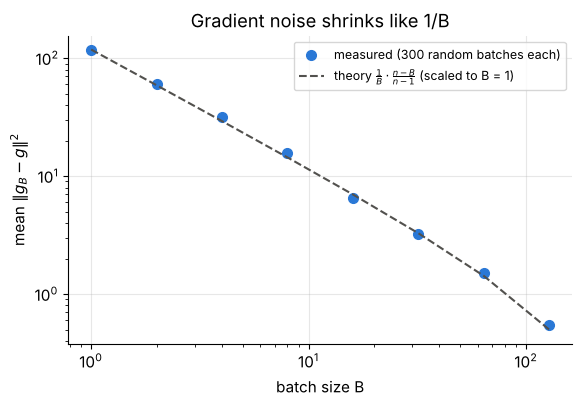

noise at B=1 is 36 times the noise at B=32


In [42]:
def flat_grad(model: nn.Module, xb: torch.Tensor, yb: torch.Tensor) -> torch.Tensor:
    """Gradient of the MSE on (xb, yb) w.r.t. all parameters, flattened into one vector."""
    model.zero_grad()
    nn.MSELoss()(model(xb), yb).backward()
    return torch.cat([p.grad.ravel() for p in model.parameters()])


torch.manual_seed(SEED)
probe = LinearRegressor(N_FEATURES)
X_all = torch.as_tensor(X_train)
y_all = torch.as_tensor((y_train - y_train.mean()) / y_train.std())
g_full = flat_grad(probe, X_all, y_all)

gen_noise = torch.Generator().manual_seed(SEED)
batch_sizes = [1, 2, 4, 8, 16, 32, 64, 128]
noise = []
for B in batch_sizes:
    sq_errors = []
    for _ in range(300):
        idx = torch.randperm(len(X_all), generator=gen_noise)[:B]
        sq_errors.append((flat_grad(probe, X_all[idx], y_all[idx]) - g_full).pow(2).sum().item())
    noise.append(np.mean(sq_errors))
n_tr = len(X_all)
theory = [noise[0] / B * (n_tr - B) / (n_tr - 1) for B in batch_sizes]

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.loglog(batch_sizes, noise, "o", color=C_TRAIN, ms=7, label="measured (300 random batches each)")
ax.loglog(batch_sizes, theory, "--", color=C_INK, label=r"theory $\frac{1}{B}\cdot\frac{n-B}{n-1}$ (scaled to B = 1)")
ax.set(xlabel="batch size B", ylabel=r"mean $\|g_B - g\|^2$", title="Gradient noise shrinks like 1/B")
ax.legend(fontsize=9)
plt.show()
print(f"noise at B=1 is {noise[0] / noise[5]:.0f} times the noise at B=32")

The measurements sit on the theoretical line. Small batches give many noisy updates, large
batches give few accurate ones. Noise is not purely bad: it lets SGD jitter out of poor regions,
and it acts as a mild regularizer. Section 11.2 measures the effect on our model.

### 7.2 A custom `Dataset`

PyTorch separates *storing and indexing* data (`Dataset`) from *batching and shuffling* it
(`DataLoader`). A map-style `Dataset` needs only two methods:

- `__len__(self)`: how many examples there are, so `len(ds)` works.
- `__getitem__(self, idx)`: return example number `idx`, so `ds[idx]` works.

Our data already fits in memory as NumPy arrays, so the dataset converts them to float32 tensors
**once** in `__init__` and `__getitem__` just indexes. (For a dataset of a million images,
`__getitem__` would instead read one image file from disk on demand.)

In [43]:
class AutoMPGDataset(Dataset):
    """Map-style dataset: float32 feature rows and float32 targets, one (x, y) pair per index."""

    def __init__(self, X: np.ndarray, y: np.ndarray):
        self.X = torch.as_tensor(X, dtype=torch.float32)    # converted once, not in __getitem__
        self.y = torch.as_tensor(y, dtype=torch.float32)
        if len(self.X) != len(self.y):
            raise ValueError(f"{len(self.X)} feature rows but {len(self.y)} targets")

    def __len__(self) -> int:
        return len(self.y)

    def __getitem__(self, idx: int) -> tuple[torch.Tensor, torch.Tensor]:
        return self.X[idx], self.y[idx]


train_ds = AutoMPGDataset(X_train, y_train)
val_ds = AutoMPGDataset(X_val, y_val)
test_ds = AutoMPGDataset(X_test, y_test)

x0, y0 = train_ds[0]
print(f"len: train {len(train_ds)}, val {len(val_ds)}, test {len(test_ds)}")
print(f"train_ds[0] -> features {tuple(x0.shape)} {x0.dtype} | target {tuple(y0.shape)} {y0.dtype} = {y0.item():.1f} mpg")

len: train 278, val 80, test 40
train_ds[0] -> features (9,) torch.float32 | target () torch.float32 = 29.9 mpg


Note the target's shape `()`: a single number (a 0-dimensional tensor), not a vector of length 1.
That choice is what makes batches of targets come out as shape `(B,)`.

### 7.3 The `DataLoader`

A `DataLoader` wraps a dataset and, on each pass (epoch), hands out mini-batches:

1. it draws indices (in random order if `shuffle=True`, otherwise $0, 1, 2, \dots$),
2. groups them into chunks of `batch_size`,
3. calls `dataset[i]` for each index and **collates** the list of `(x, y)` pairs into batched
   tensors by stacking: 32 features of shape `(9,)` become `(32, 9)`, 32 targets of shape `()`
   become `(32,)`.

In [44]:
loader_gen = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, generator=loader_gen)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)

print("batches per epoch:", len(train_loader), "| batch sizes:", [len(yb) for _, yb in train_loader])
xb, yb = next(iter(train_loader))
print("one training batch:", tuple(xb.shape), xb.dtype, "|", tuple(yb.shape), yb.dtype)

pairs = [train_ds[i] for i in range(3)]                  # what the loader does internally
xb3, yb3 = default_collate(pairs)
print("default_collate of 3 pairs:", tuple(xb3.shape), tuple(yb3.shape))

def first_targets(loader):
    """The first five targets the loader yields in a fresh pass."""
    return [round(v, 1) for v in next(iter(loader))[1][:5].tolist()]

print("train, pass 1:", first_targets(train_loader), "| pass 2:", first_targets(train_loader))
print("val,   pass 1:", first_targets(val_loader), "| pass 2:", first_targets(val_loader))

batches per epoch: 9 | batch sizes: [32, 32, 32, 32, 32, 32, 32, 32, 22]
one training batch: (32, 9) torch.float32 | (32,) torch.float32
default_collate of 3 pairs: (3, 9) (3,)
train, pass 1: [15.0, 24.0, 18.1, 25.5, 16.0] | pass 2: [34.5, 17.5, 38.0, 30.0, 22.5]
val,   pass 1: [33.0, 28.0, 19.0, 13.0, 14.0] | pass 2: [33.0, 28.0, 19.0, 13.0, 14.0]


Things to notice:

- **Batch count.** $\lceil 278/32 \rceil = 9$ batches: eight full ones and a last one with
  $278 - 8 \cdot 32 = 22$ cars. `drop_last=True` would discard that last partial batch. With so
  little data we keep every car.
- **Shuffle the training data only.** A fresh random order each epoch means the batches differ
  from epoch to epoch instead of replaying one fixed sequence. (The raw CSV is sorted by model
  year. `train_test_split` already shuffled our rows once, because it shuffles by default, but
  without `shuffle=True` every epoch would still see exactly the same 9 batches in the same order.
  Section 11.2 shows what can go wrong when the training rows *are* sorted.) For validation and
  test the order is irrelevant to the metric, and a fixed order keeps predictions aligned with the
  rows of `val_df` and `test_df`.
- **Reproducibility.** Passing a seeded `torch.Generator` makes the shuffling order reproducible
  independently of everything else that uses random numbers.
- **`num_workers`.** For big datasets, `num_workers > 0` loads batches in parallel processes. For
  278 rows already in memory the default (0, load in the main process) is fastest.

> **Quick check.** With `batch_size=64`, how many updates does one epoch perform, and how big is
> the last batch?

<details>
<summary>Answer</summary>

$\lceil 278/64 \rceil = 5$ updates. The first four batches hold $4 \cdot 64 = 256$ cars, so the
last one holds $278 - 256 = 22$ cars.
</details>

### ✏️ Exercise 7: a `Dataset` built straight from a DataFrame

Write a `CarFrameDataset(df, preprocessor)` that takes a **raw** DataFrame and an **already
fitted** `AutoMPGPreprocessor`. It must only *transform* (never fit!), store float32 tensors, and
return `(features, target)` where `features` has shape `(9,)` and `target` is a 0-dimensional
float32 tensor holding the car's mpg.

In [45]:
# ✏️ Exercise 7: a Dataset built straight from a DataFrame
class CarFrameDataset(Dataset):
    """Raw DataFrame + fitted preprocessor -> (x float32 (9,), y float32 scalar) pairs."""

    def __init__(self, df: pd.DataFrame, preprocessor: AutoMPGPreprocessor):
        # YOUR CODE HERE
        raise NotImplementedError

    def __len__(self) -> int:
        # YOUR CODE HERE
        raise NotImplementedError

    def __getitem__(self, idx: int):
        # YOUR CODE HERE
        raise NotImplementedError


def _test_ex7():
    p = copy.deepcopy(prep)                                  # protect the real preprocessor
    mean_before = p.scaler_.mean_.copy()
    ds = CarFrameDataset(val_df, p)
    assert np.allclose(p.scaler_.mean_, mean_before), "the preprocessor was re-fitted: only call transform()"
    assert len(ds) == len(val_df), f"len(ds) = {len(ds)}, expected {len(val_df)}"
    x, y = ds[3]
    assert isinstance(x, torch.Tensor) and x.dtype == torch.float32 and tuple(x.shape) == (9,), \
        f"features must be a float32 tensor of shape (9,), got {type(x).__name__} {getattr(x, 'shape', None)}"
    assert isinstance(y, torch.Tensor) and y.dtype == torch.float32 and y.ndim == 0, \
        "the target must be a 0-dimensional float32 tensor"
    assert torch.allclose(x, torch.as_tensor(prep.transform(val_df.iloc[[3]])[0])), "features differ from prep.transform"
    assert abs(y.item() - val_df["mpg"].iloc[3]) < 1e-4, "target must be the car's mpg"
    xb_, yb_ = next(iter(DataLoader(ds, batch_size=16)))
    assert tuple(xb_.shape) == (16, 9) and tuple(yb_.shape) == (16,), f"batch shapes {tuple(xb_.shape)}, {tuple(yb_.shape)}"


run_check("Exercise 7", _test_ex7)

⏳ Exercise 7: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
class CarFrameDataset(Dataset):
    def __init__(self, df, preprocessor):
        self.X = torch.as_tensor(preprocessor.transform(df), dtype=torch.float32)   # transform only
        self.y = torch.as_tensor(df["mpg"].to_numpy(), dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]
```
Indexing a 1-D tensor with an integer returns a 0-dimensional tensor, which is exactly the target
shape we want. Calling `preprocessor.fit(df)` here would be leakage: the validation cars would
set their own scaling statistics.
</details>

---
## 8. The MLP model

### 8.1 From a straight line to a curve: hidden layers and ReLU

Linear regression can only tilt a flat surface. Section 3.6 showed that the truth is curved, so we
need a model that can **bend**. The obvious idea, stacking two linear layers, does *not* work on
its own: with $\mathbf{h} = W_1\mathbf{x} + \mathbf{b}_1$ and $\hat y = \mathbf{w}_2^\top\mathbf{h} + b_2$,

$$
\hat y = \mathbf{w}_2^\top (W_1\mathbf{x} + \mathbf{b}_1) + b_2
       = \underbrace{(\mathbf{w}_2^\top W_1)}_{\text{one row vector}}\mathbf{x}
       + \underbrace{(\mathbf{w}_2^\top\mathbf{b}_1 + b_2)}_{\text{one number}},
$$

which is again a plain linear model. Any stack of linear layers collapses into one linear layer.
The fix is to put a simple **nonlinear function** between the layers. The most popular choice is
the **rectified linear unit**

$$
\operatorname{ReLU}(z) = \max(0, z),
$$

applied to every entry separately. One ReLU unit $\operatorname{ReLU}(w - t)$ is a **hinge**: flat
until the knot $t$, then a straight ramp. A weighted sum of hinges is a **piecewise-linear curve**
that changes slope at every knot.

**A worked example by hand.** Two hinge units on the raw weight $w$ (in pounds), with knots at
2000 lb and 3000 lb, combined by an output layer:

$$
h_1 = \operatorname{ReLU}(w - 2000), \quad h_2 = \operatorname{ReLU}(w - 3000), \quad
\hat y = 38 - 0.016\,h_1 + 0.010\,h_2 .
$$

| weight $w$ | $h_1$ | $h_2$ | $\hat y = 38 - 0.016h_1 + 0.010h_2$ |
|---|---|---|---|
| 1800 | 0 | 0 | 38 |
| 2500 | 500 | 0 | $38 - 8 = 30$ |
| 3500 | 1500 | 500 | $38 - 24 + 5 = 19$ |
| 4500 | 2500 | 1500 | $38 - 40 + 15 = 13$ |

The slope is $0$ below 2000 lb, $-0.016$ mpg per lb between the knots and
$-0.016 + 0.010 = -0.006$ above 3000 lb: a steep drop that flattens out, exactly the shape of
the MPG-versus-weight cloud. A network with more hinges can follow any continuous curve as
closely as we like, and this is the intuition behind the **universal approximation theorem**.

The cell below makes this concrete. It puts hinges at five fixed knots and fits only the output
weights by least squares. A real MLP goes one step further and **learns the knots too** (they are
the first layer's weights and biases), in all 9 dimensions at once.

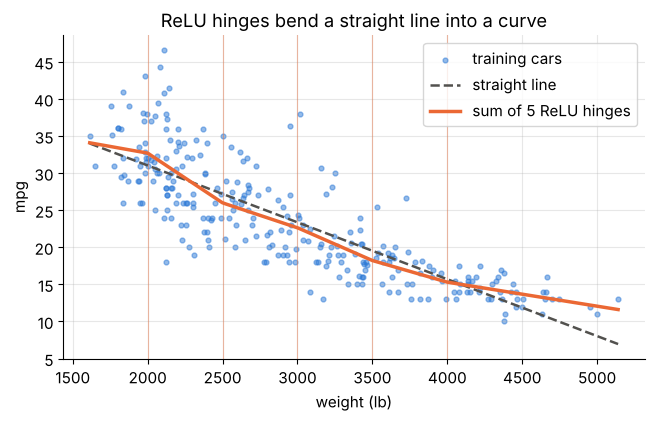

 straight line: training RMSE = 4.388 mpg
 5 ReLU hinges: training RMSE = 4.235 mpg


In [46]:
knots = np.array([2000.0, 2500.0, 3000.0, 3500.0, 4000.0])
w_train = train_df["weight"].to_numpy(float)


def hinge_features(weights: np.ndarray) -> np.ndarray:
    """[1, w, ReLU(w - t_1), ..., ReLU(w - t_K)]: a 1-hidden-layer ReLU net with fixed knots."""
    return np.c_[np.ones_like(weights), weights, np.maximum(0.0, weights[:, None] - knots[None, :])]


coef_hinge, *_ = np.linalg.lstsq(hinge_features(w_train), y_train.astype(float), rcond=None)
coef_line = np.polyfit(w_train, y_train.astype(float), deg=1)
grid = np.linspace(w_train.min(), w_train.max(), 300)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.scatter(w_train, y_train, s=12, alpha=0.5, color=C_TRAIN, label="training cars")
ax.plot(grid, np.polyval(coef_line, grid), color=C_INK, ls="--", lw=1.8, label="straight line")
ax.plot(grid, hinge_features(grid) @ coef_hinge, color=C_VAL, lw=2.5, label="sum of 5 ReLU hinges")
for t in knots:
    ax.axvline(t, color=C_VAL, lw=0.8, alpha=0.4)
ax.set(xlabel="weight (lb)", ylabel="mpg", title="ReLU hinges bend a straight line into a curve")
ax.legend()
plt.show()
for name, pred in [("straight line", np.polyval(coef_line, w_train)),
                   ("5 ReLU hinges", hinge_features(w_train) @ coef_hinge)]:
    print(f"{name:>14}: training RMSE = {rmse(y_train, pred):.3f} mpg")

The hinge model follows the curve (the vertical lines mark its knots) and lowers the training
error using weight alone. With all 9 features and learned knots, an MLP can also capture
**interactions**, for example "extra weight costs fewer MPG in newer cars".

### 8.2 The architecture we will train

Our network has two hidden layers of 64 ReLU units and one output unit **without** an activation:

```
 x (B, 9) ─► Linear(9→64) ─► ReLU ─► Linear(64→64) ─► ReLU ─► Linear(64→1) ─► squeeze(1) ─► ŷ (B,)
            └──── hidden layer 1 ───┘  └──── hidden layer 2 ────┘  └──── output ────┘
```

In matrix form, for a batch $X \in \mathbb{R}^{B \times 9}$ of $B$ cars:

$$
H_1 = \operatorname{ReLU}(X W_1^\top + \mathbf{b}_1) \in \mathbb{R}^{B \times 64}, \qquad
H_2 = \operatorname{ReLU}(H_1 W_2^\top + \mathbf{b}_2) \in \mathbb{R}^{B \times 64}, \qquad
\hat{\mathbf{y}} = H_2 W_3^\top + b_3 \in \mathbb{R}^{B \times 1}.
$$

| layer | weight shape | bias shape | parameters |
|---|---|---|---|
| `fc1` | $W_1$: $64 \times 9$ | $\mathbf{b}_1$: $64$ | $576 + 64 = 640$ |
| `fc2` | $W_2$: $64 \times 64$ | $\mathbf{b}_2$: $64$ | $4096 + 64 = 4160$ |
| `out` | $W_3$: $1 \times 64$ | $b_3$: $1$ | $64 + 1 = 65$ |
| **total** | | | **4865** |

**Why no activation on the output?** The prediction must be able to take *any* real value. A
ReLU at the end would forbid negative outputs (and once we standardize the target in Section 10,
about half of all targets *are* negative), and a sigmoid would squash everything into $(0, 1)$.
For regression the last layer is purely linear, and the hidden layers provide the curvature.

In [47]:
class MLP(nn.Module):
    """Two hidden ReLU layers and a linear output unit: (B, in_features) -> (B,)."""

    def __init__(self, in_features: int = 9, hidden_dims: int = 64):
        super().__init__()
        self.fc1 = nn.Linear(in_features, hidden_dims)
        self.fc2 = nn.Linear(hidden_dims, hidden_dims)
        self.out = nn.Linear(hidden_dims, 1)        # no activation: any real number is allowed

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = F.relu(self.fc1(x))                     # (B, 64)
        h = F.relu(self.fc2(h))                     # (B, 64)
        return self.out(h).squeeze(1)               # (B, 1) -> (B,)


torch.manual_seed(SEED)
model = MLP(N_FEATURES, 64).to(DEVICE)
print(model)
for name, p in model.named_parameters():
    print(f"  {name:11s} {str(tuple(p.shape)):9s} -> {p.numel():5d} parameters")
print("  total:", sum(p.numel() for p in model.parameters()), "parameters")

MLP(
  (fc1): Linear(in_features=9, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=64, bias=True)
  (out): Linear(in_features=64, out_features=1, bias=True)
)
  fc1.weight  (64, 9)   ->   576 parameters
  fc1.bias    (64,)     ->    64 parameters
  fc2.weight  (64, 64)  ->  4096 parameters
  fc2.bias    (64,)     ->    64 parameters
  out.weight  (1, 64)   ->    64 parameters
  out.bias    (1,)      ->     1 parameters
  total: 4865 parameters


### 8.3 One forward pass, checked by hand

Let us push two real training cars through the untrained network twice: once with `model(x)`
and once with explicit matrix products following the formulas above. The two must agree.

In [48]:
x2 = torch.as_tensor(X_train[:2]).to(DEVICE)              # two standardized cars, shape (2, 9)
with torch.no_grad():
    H1 = torch.clamp(x2 @ model.fc1.weight.T + model.fc1.bias, min=0)      # ReLU = clamp at 0
    H2 = torch.clamp(H1 @ model.fc2.weight.T + model.fc2.bias, min=0)
    by_hand = (H2 @ model.out.weight.T + model.out.bias).squeeze(1)
    by_model = model(x2)
print("by hand :", by_hand.cpu().numpy().round(5))
print("model(x):", by_model.cpu().numpy().round(5), "| equal:", torch.allclose(by_hand, by_model, atol=1e-6))
print(f"active hidden units: layer 1 {(H1 > 0).float().mean().item():.0%}, layer 2 {(H2 > 0).float().mean().item():.0%}")
print("true mpg of these cars:", y_train[:2])

by hand : [0.18424 0.34689]
model(x): [0.18424 0.34689] | equal: True
active hidden units: layer 1 52%, layer 2 54%
true mpg of these cars: [29.9 32. ]


The untrained network outputs numbers close to **zero**, while the true values are about 30 mpg. That is expected (random small weights produce small outputs) and it will produce a striking
$R^2$ at the start of training in Section 9. About half of the hidden units are active (positive)
for a given car: each car switches on its own subset of hinges.

### 8.4 A flexible version for experiments

For the experiments in Section 11 we want to vary the number and width of hidden layers.
`nn.Sequential` chains modules in order, so we can build the layer list in a loop. Because it
creates its layers in the same order as `MLP`, the same seed gives **exactly** the same initial
weights, which the cell checks.

In [49]:
class FlexibleMLP(nn.Module):
    """MLP with any list of hidden widths, e.g. hidden=(64, 64) or (256, 256, 256)."""

    def __init__(self, in_features: int = 9, hidden: tuple[int, ...] = (64, 64)):
        super().__init__()
        layers, width = [], in_features
        for h in hidden:
            layers += [nn.Linear(width, h), nn.ReLU()]
            width = h
        layers.append(nn.Linear(width, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x).squeeze(1)


torch.manual_seed(SEED)
flex = FlexibleMLP(N_FEATURES, (64, 64)).to(DEVICE)
print(flex)
same = all(torch.equal(p, q) for p, q in zip(model.parameters(), flex.parameters()))
print("same initial parameters as MLP(9, 64) with the same seed:", same)

FlexibleMLP(
  (net): Sequential(
    (0): Linear(in_features=9, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)
same initial parameters as MLP(9, 64) with the same seed: True


> **Quick check.** A colleague deletes the two `F.relu` calls "to make training faster". What
> can the network still learn, and how would it compare with the baselines of Section 5?

<details>
<summary>Answer</summary>

Without activations the three layers collapse into a single linear map (Section 8.1), so the
network can only represent linear regression on the 9 features, just with 4865 redundant
parameters. At best it matches the closed-form linear baseline (validation $R^2 \approx 0.84$),
and it can never beat the physics-inspired baseline, which needs a curve.
</details>

### ✏️ Exercise 8: counting parameters

Write `count_mlp_params(in_features, hidden)` that returns the number of trainable parameters of
`FlexibleMLP(in_features, hidden)` **using a formula**, without building the model. Each
`nn.Linear(a, b)` holds $a \cdot b$ weights and $b$ biases.

In [50]:
# ✏️ Exercise 8: counting parameters
def count_mlp_params(in_features: int, hidden: tuple[int, ...]) -> int:
    """Number of parameters of FlexibleMLP(in_features, hidden), computed with a formula."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex8():
    assert count_mlp_params(9, (64, 64)) == 4865, f"(9, (64, 64)) should give 4865, got {count_mlp_params(9, (64, 64))}"
    assert count_mlp_params(9, ()) == 10, "no hidden layer = linear regression: 9 weights + 1 bias"
    for d, hid in [(9, (8,)), (9, (256, 256)), (3, (5, 7, 2)), (12, (64, 64, 64))]:
        expected = sum(p.numel() for p in FlexibleMLP(d, hid).parameters())
        got = count_mlp_params(d, hid)
        assert got == expected, f"in_features={d}, hidden={hid}: got {got}, expected {expected}"


run_check("Exercise 8", _test_ex8)

⏳ Exercise 8: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def count_mlp_params(in_features, hidden):
    widths = [in_features, *hidden, 1]                  # 9 -> 64 -> 64 -> 1
    return sum(a * b + b for a, b in zip(widths[:-1], widths[1:]))
```
Consecutive pairs of widths describe the linear layers, and each contributes $a \cdot b$ weights plus
$b$ biases. For $(9, (64, 64))$: $640 + 4160 + 65 = 4865$. Notice how the $64 \times 64$ middle
layer dominates: parameter counts grow with the **square** of the width.
</details>

---
## 9. Training the reference configuration

Our **reference configuration** is deliberately plain: the MLP of Section 8, MSE loss, plain SGD
with learning rate $0.01$, mini-batches of 32 cars, 100 epochs, and the target `mpg` used **as
is** (unscaled). Everything later is compared against it, changing one thing at a time.

### 9.1 Three helpers: train, predict, evaluate

The training function is the five-line step from Section 6.5 inside a loop over the
`DataLoader`. Two optional arguments, `y_mean` and `y_std`, let the network learn a *scaled*
target `(y - y_mean) / y_std`. With the defaults `(0, 1)` nothing changes. We will
need them in Section 10.

In [51]:
def train_one_epoch(model, loader, loss_fn, optimizer, y_mean: float = 0.0, y_std: float = 1.0,
                    device=DEVICE) -> float:
    """One pass over `loader`. Returns the average loss per car (in units of the scaled target)."""
    model.train()                                   # training mode (matters for dropout, batch norm)
    total, count = 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        target = (yb - y_mean) / y_std              # the network learns the scaled target
        optimizer.zero_grad()                       # 1. clear the old gradients
        loss = loss_fn(model(xb), target)           # 2-3. forward pass and mean loss of the batch
        loss.backward()                             # 4. backward pass
        optimizer.step()                            # 5. update the parameters
        total += loss.item() * len(yb)              # batch mean -> batch sum (last batch is smaller)
        count += len(yb)
    return total / count


@torch.no_grad()                                    # nothing inside builds a graph
def predict(model, loader, y_mean: float = 0.0, y_std: float = 1.0, device=DEVICE):
    """Predictions in mpg (scaling undone) and the matching targets, as NumPy arrays."""
    model.eval()                                    # evaluation mode
    preds, targets = [], []
    for xb, yb in loader:
        preds.append(model(xb.to(device)).cpu() * y_std + y_mean)
        targets.append(yb)
    return torch.cat(preds).numpy(), torch.cat(targets).numpy()


def evaluate(model, loader, y_mean: float = 0.0, y_std: float = 1.0) -> dict:
    """MSE (in mpg^2) and R^2 of the model on every car in `loader`."""
    pred, y = predict(model, loader, y_mean, y_std)
    return {"loss": mse(y, pred), "r2": r2_score_np(y, pred)}

Details that matter:

- **`loss.item()`** converts the loss to a plain Python float. Accumulating the *tensor* instead
  (`total += loss`) would keep every batch's computational graph alive: a classic memory leak.
- **Weighting by `len(yb)`.** `nn.MSELoss` averages over the batch. The last batch holds only 22
  cars, so we turn each batch mean back into a sum before averaging over the epoch.
- **`@torch.no_grad()`** used as a decorator switches gradient tracking off for the whole
  function. It is equivalent to wrapping the body in `with torch.no_grad():`.
- **`model.train()` and `model.eval()`** set a flag that some layers read. Our MLP has no such
  layers, so its outputs are identical in both modes. **Dropout** is the most common layer that
  does care: in training mode it zeroes each value with probability $p$ and multiplies the
  survivors by $1/(1-p)$, and in evaluation mode it does nothing.

In [52]:
drop = nn.Dropout(p=0.5)
x_ones = torch.ones(1, 6)
torch.manual_seed(SEED)
drop.train()
print("training mode, call 1:", drop(x_ones).tolist()[0])
print("training mode, call 2:", drop(x_ones).tolist()[0])
drop.eval()
print("evaluation mode      :", drop(x_ones).tolist()[0])

training mode, call 1: [2.0, 2.0, 2.0, 2.0, 0.0, 2.0]
training mode, call 2: [0.0, 0.0, 2.0, 2.0, 2.0, 2.0]
evaluation mode      : [1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


In training mode two calls on the same input differ (random zeros, survivors doubled), and in
evaluation mode the layer is the identity. Forgetting `model.eval()` before measuring a model
with dropout gives noisy, pessimistic scores, and forgetting `model.train()` afterwards silently turns
the regularization off. Switching modes explicitly in `train_one_epoch` and `predict` is a habit
that protects you the day you add such layers.

### 9.2 One function to run a whole experiment

Every experiment in this notebook is described by a small, immutable `Config` record. A
`dataclass` gives us readable defaults, and `replace(cfg, lr=0.1)` creates a copy with one field
changed, which is perfect for one-change-at-a-time experiments.

In [53]:
@dataclass(frozen=True)
class Config:
    """Everything that defines one training run."""
    hidden: tuple = (64, 64)          # hidden-layer widths
    lr: float = 0.01                  # learning rate
    optimizer: str = "sgd"            # "sgd", "momentum", "adam" or "adamw"
    momentum: float = 0.9             # only used by "momentum"
    weight_decay: float = 0.0         # L2 penalty strength (Section 11.5)
    batch_size: int = 32
    epochs: int = 100
    standardize_target: bool = False  # Section 10
    patience: int | None = None       # early stopping (Section 11.4), None means train all epochs
    seed: int = SEED                  # controls the initial weights and the shuffling order


def make_optimizer(cfg: Config, params):
    """Create the optimizer named in the config."""
    if cfg.optimizer == "sgd":
        return torch.optim.SGD(params, lr=cfg.lr, weight_decay=cfg.weight_decay)
    if cfg.optimizer == "momentum":
        return torch.optim.SGD(params, lr=cfg.lr, momentum=cfg.momentum, weight_decay=cfg.weight_decay)
    if cfg.optimizer == "adam":
        return torch.optim.Adam(params, lr=cfg.lr, weight_decay=cfg.weight_decay)
    if cfg.optimizer == "adamw":
        return torch.optim.AdamW(params, lr=cfg.lr, weight_decay=cfg.weight_decay)
    raise ValueError(f"unknown optimizer {cfg.optimizer!r}")


REFERENCE = Config()
print(REFERENCE)

Config(hidden=(64, 64), lr=0.01, optimizer='sgd', momentum=0.9, weight_decay=0.0, batch_size=32, epochs=100, standardize_target=False, patience=None, seed=42)


`run_experiment` builds a fresh model from the seed, trains it, and records the training and
validation metrics **before training (epoch 0)** and after every epoch. It also tracks the epoch
with the lowest validation loss. With `patience` set it stops early and restores that best model
(Section 11.4). Two small points:

- The training metrics in the history are recomputed after each epoch in evaluation mode. The
  column `train_running_loss` is the average loss *during* the epoch, while the weights were
  still changing (the number `train_one_epoch` returns).
- For the per-epoch evaluation, a plain list holding one full batch, `[(X, y)]`, plays the role
  of a loader: `predict` only needs something it can loop over that yields `(x, y)` pairs. The
  batch size does not change predictions, and skipping the `DataLoader` machinery (fetching 358
  rows one by one and stacking them again, every epoch) makes the experiments noticeably faster.

In [54]:
@dataclass
class RunResult:
    model: nn.Module
    history: pd.DataFrame             # one row per epoch (0 = before training)
    best_epoch: int                   # epoch with the lowest validation loss
    y_mean: float                     # target scaling used (0 and 1 if not standardized)
    y_std: float
    seconds: float


def run_experiment(cfg: Config, train_ds=train_ds, val_ds=val_ds, print_every: int = 0,
                   shuffle: bool = True) -> RunResult:
    """Train a fresh FlexibleMLP according to `cfg` and return the model and its history."""
    t0 = time.time()
    torch.manual_seed(cfg.seed)                                  # same seed -> same initial weights
    model = FlexibleMLP(train_ds.X.shape[1], cfg.hidden).to(DEVICE)
    shuffle_gen = torch.Generator().manual_seed(cfg.seed)        # same seed -> same batch order
    train_loader = DataLoader(train_ds, batch_size=cfg.batch_size, shuffle=shuffle, generator=shuffle_gen)
    train_eval_loader = [(train_ds.X, train_ds.y)]               # one full batch (see the note above)
    val_loader_big = [(val_ds.X, val_ds.y)]
    if cfg.standardize_target:                                   # statistics of the TRAINING targets
        y_mean, y_std = float(train_ds.y.mean()), float(train_ds.y.std(correction=0))
    else:
        y_mean, y_std = 0.0, 1.0
    loss_fn, optimizer = nn.MSELoss(), make_optimizer(cfg, model.parameters())

    rows = []
    best_loss, best_epoch, bad_epochs = float("inf"), 0, 0
    best_state = copy.deepcopy(model.state_dict())

    def record(epoch: int, running: float) -> float:
        tr = evaluate(model, train_eval_loader, y_mean, y_std)
        va = evaluate(model, val_loader_big, y_mean, y_std)
        rows.append({"epoch": epoch, "train_running_loss": running, "train_loss": tr["loss"],
                     "train_r2": tr["r2"], "val_loss": va["loss"], "val_r2": va["r2"]})
        return va["loss"]

    record(0, float("nan"))
    for epoch in range(1, cfg.epochs + 1):
        running = train_one_epoch(model, train_loader, loss_fn, optimizer, y_mean, y_std) * y_std ** 2
        val_loss = record(epoch, running)
        if not np.isfinite(val_loss):                            # diverged: stop, nothing to save
            break
        if val_loss < best_loss:
            best_loss, best_epoch, bad_epochs = val_loss, epoch, 0
            if cfg.patience is not None:
                best_state = copy.deepcopy(model.state_dict())  # a snapshot, not a reference!
        else:
            bad_epochs += 1
            if cfg.patience is not None and bad_epochs >= cfg.patience:
                break
        if print_every and epoch % print_every == 0:
            r = rows[-1]
            print(f"epoch {epoch:3d} | train MSE {r['train_loss']:8.3f}  R2 {r['train_r2']:+.4f}"
                  f" | val MSE {r['val_loss']:8.3f}  R2 {r['val_r2']:+.4f}")
    if cfg.patience is not None:
        model.load_state_dict(best_state)                        # roll back to the best epoch
    history = pd.DataFrame(rows).set_index("epoch")
    return RunResult(model, history, best_epoch, y_mean, y_std, time.time() - t0)

### 9.3 Train it

In [55]:
ref = run_experiment(REFERENCE, print_every=10)
print(f"trained {len(ref.history) - 1} epochs in {ref.seconds:.1f} s")
display(ref.history.loc[[0, 1, 2, 3, 5, 10, 20, 50, 100]].round(4))

epoch  10 | train MSE    7.662  R2 +0.8752 | val MSE    5.995  R2 +0.8885

epoch  20 | train MSE    5.642  R2 +0.9081 | val MSE    5.186  R2 +0.9035


epoch  30 | train MSE    5.992  R2 +0.9024 | val MSE    6.970  R2 +0.8704


epoch  40 | train MSE    5.768  R2 +0.9061 | val MSE    5.701  R2 +0.8940


epoch  50 | train MSE    6.324  R2 +0.8970 | val MSE    7.960  R2 +0.8520
epoch  60 | train MSE    6.002  R2 +0.9022 | val MSE    6.747  R2 +0.8745


epoch  70 | train MSE    6.808  R2 +0.8891 | val MSE    9.114  R2 +0.8305
epoch  80 | train MSE    5.590  R2 +0.9090 | val MSE    8.045  R2 +0.8504


epoch  90 | train MSE    4.252  R2 +0.9308 | val MSE    5.872  R2 +0.8908
epoch 100 | train MSE    3.883  R2 +0.9368 | val MSE    5.402  R2 +0.8995
trained 100 epochs in 1.8 s


,train_running_loss,train_loss,train_r2,val_loss,val_r2
epoch,,,,,
0,NaN,611.1057,-8.9525,579.9756,-9.7869
1,459.5494,282.3815,-3.5989,250.6647,-3.6621
2,219.1735,32.3562,0.4730,30.6554,0.4298
3,61.2443,17.2404,0.7192,13.8685,0.7421
5,29.4701,18.8816,0.6925,15.4112,0.7134
10,21.1643,7.6618,0.8752,5.9945,0.8885
20,6.7997,5.6416,0.9081,5.1861,0.9035
50,5.3480,6.3236,0.8970,7.9595,0.8520
100,8.5913,3.8826,0.9368,5.4024,0.8995


### 9.4 Reading the curves

A helper we will reuse: the loss on a log scale (it spans orders of magnitude), and $R^2$ twice,
once over its full range and once zoomed in, with the best baseline from Section 5 as a dashed
line.

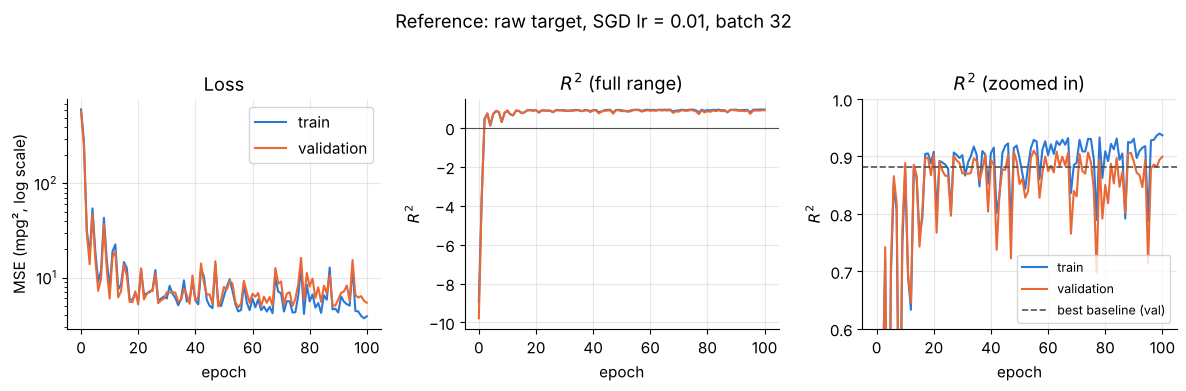

validation R2: before training -9.787 | epoch 1 -3.662 | epoch 2 0.430 | epoch 10 0.889
epochs 20-100: between 0.699 and 0.910 | final 0.8995 | best 0.9101 at epoch 55


In [56]:
BEST_BASELINE_VAL_R2 = scoreboard.loc["linear on gallons/100 mi", "val R2"]


def plot_history(h: pd.DataFrame, title: str, r2_floor: float = 0.6) -> None:
    """Loss (log scale) and R^2 curves, train vs validation."""
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
    axes[0].semilogy(h.index, h["train_loss"], color=C_TRAIN, label="train")
    axes[0].semilogy(h.index, h["val_loss"], color=C_VAL, label="validation")
    axes[0].set(xlabel="epoch", ylabel="MSE (mpg², log scale)", title="Loss")
    for ax, zoom in [(axes[1], False), (axes[2], True)]:
        ax.plot(h.index, h["train_r2"], color=C_TRAIN, label="train")
        ax.plot(h.index, h["val_r2"], color=C_VAL, label="validation")
        if zoom:
            ax.axhline(BEST_BASELINE_VAL_R2, color=C_INK, ls="--", lw=1.2, label="best baseline (val)")
            ax.set_ylim(r2_floor, 1.0)
        else:
            ax.axhline(0.0, color=C_INK, lw=0.8)
        ax.set(xlabel="epoch", ylabel="$R^2$", title="$R^2$ (zoomed in)" if zoom else "$R^2$ (full range)")
    axes[0].legend()
    axes[2].legend(fontsize=9, loc="lower right")
    fig.suptitle(title, y=1.02)
    plt.tight_layout()
    plt.show()


plot_history(ref.history, "Reference: raw target, SGD lr = 0.01, batch 32")
h = ref.history
late = h.loc[20:, "val_r2"]
print(f"validation R2: before training {h['val_r2'].iloc[0]:.3f} | epoch 1 {h['val_r2'].loc[1]:.3f} | "
      f"epoch 2 {h['val_r2'].loc[2]:.3f} | epoch 10 {h['val_r2'].loc[10]:.3f}")
print(f"epochs 20-100: between {late.min():.3f} and {late.max():.3f} | final {h['val_r2'].iloc[-1]:.4f} | "
      f"best {h['val_r2'].max():.4f} at epoch {h['val_r2'].idxmax()}")

What the curves say:

- **A dramatic start.** The loss falls by more than an order of magnitude within three epochs,
  and the validation $R^2$ climbs from about $-9.8$ (far off the zoomed chart) to above 0.7.
- **A noisy middle.** From epoch 20 on, the validation $R^2$ wobbles up and down (range printed
  above) instead of improving steadily, and the training curve wobbles too. The steps are too
  large for the narrow valley the loss lives in. Section 10 explains why and fixes it.
- **The final value depends on luck.** The last epoch happens to be a good one, but the best
  epoch (around epoch 55) is better still. Stopping after epoch 70 would have given a much worse
  model. Section 11.4 turns this observation into **early stopping**.

### 9.5 Why does $R^2$ start near $-10$?

Section 8.3 showed that the untrained network outputs numbers close to 0 for every car. A model
that predicts (almost) the same constant $c$ for every car scores, by Section 5.2,

$$
R^2 \approx -\left(\frac{\bar y - c}{\sigma_y}\right)^2 .
$$

With $\bar y \approx 23$ mpg, $\sigma_y \approx 7.3$ mpg and $c \approx 0.2$, that is about
$-(23/7.3)^2 \approx -10$: the untrained network's guesses sit more than three standard deviations
below the average car. Let us check this with the exact numbers.

In [57]:
torch.manual_seed(SEED)                                     # the same initial weights as `ref`
untrained = FlexibleMLP(N_FEATURES, (64, 64)).to(DEVICE)
val_big = DataLoader(val_ds, batch_size=512)
init_pred, _ = predict(untrained, val_big)
c0 = float(init_pred.mean())
ybar_val, sigma_val = float(y_val.mean()), float(y_val.std())
print(f"untrained predictions on validation: mean {c0:.3f}, std {init_pred.std():.3f} (true mpg: mean {ybar_val:.2f}, std {sigma_val:.2f})")
print(f"formula  -((ybar - c) / sigma)^2 = {-((ybar_val - c0) / sigma_val) ** 2:.3f}")
print(f"actual R2 of the untrained model = {r2_score_np(y_val, init_pred):.3f}")
init_train_pred, _ = predict(untrained, DataLoader(train_ds, batch_size=512))
print(f"training MSE at epoch 0 = {mse(y_train, init_train_pred):.1f}  vs  mean(y^2) = ybar^2 + sigma^2 = "
      f"{float(np.mean(y_train.astype(np.float64) ** 2)):.1f}   (predictions are almost 0)")

untrained predictions on validation: mean 0.195, std 0.068 (true mpg: mean 23.14, std 7.33)
formula  -((ybar - c) / sigma)^2 = -9.794
actual R2 of the untrained model = -9.787
training MSE at epoch 0 = 611.1  vs  mean(y^2) = ybar^2 + sigma^2 = 621.1   (predictions are almost 0)


The formula nails it. A huge negative $R^2$ at the start is **not a bug**: it measures how far
the untrained output (about 0) is from the target mean (about 23.5), in units of the target's
standard deviation. Likewise, the starting training MSE is almost exactly
$\overline{y^2} = \bar y^2 + \sigma_y^2$, the MSE of predicting 0 for everyone.

Why does it recover so quickly? At first almost the whole error is a **shared offset**: every
prediction is about 23 mpg too low. The gradient of the loss with respect to every parameter that
can raise all outputs at once (above all the output bias $b_3$) is large and points the same way
for every car, so the first few updates mostly lift the predictions toward the average. Only
after that does the network start learning *differences* between cars. Section 10 removes the
offset problem before training even starts.

### 9.6 Did the MLP beat the baselines?

In [58]:
ref_val_pred, _ = predict(ref.model, val_big)
mlp_row = pd.DataFrame({"train R2": [ref.history["train_r2"].iloc[-1]],
                        "val R2": [r2_score_np(y_val, ref_val_pred)],
                        "val RMSE": [rmse(y_val, ref_val_pred)], "val MAE": [mae(y_val, ref_val_pred)]},
                       index=["MLP reference (epoch 100)"])
display(pd.concat([scoreboard, mlp_row]).round(4))

,train R2,val R2,val RMSE,val MAE
mean predictor,-0.0000,-0.0049,7.3506,5.9579
linear regression,0.8255,0.8424,2.9113,2.3261
linear on gallons/100 mi,0.8613,0.8819,2.5202,1.8745
MLP reference (epoch 100),0.9368,0.8995,2.3243,1.7570


Yes, but only modestly: the reference MLP beats the physics-inspired linear model on all three
validation metrics, by about 0.02 in $R^2$ and about 0.2 mpg in RMSE. Remember also that a single
noisy training run is weak evidence. The rest of the notebook makes training smoother, then measures the variability
properly with several seeds.

> **Common pitfall.** Reporting the *best* validation epoch (here around 0.91) as "the model's
> score" is optimistic: you chose that epoch *because* it scored well on these very cars.
> Anything chosen using the validation set must be judged on data that played no part in the
> choice: the test set, in Section 12.

### ✏️ Exercise 9: one training epoch with gradient accumulation

Sometimes the batch you want does not fit in memory. **Gradient accumulation** imitates a big
batch with several small ones, using the fact (Section 6.2) that `backward()` *adds* to `.grad`.
Write `train_one_epoch_accum(model, loader, loss_fn, optimizer, accum_steps)`:

- put the model in training mode, and for every batch compute the loss and call `backward()` on
  `loss / accum_steps`.
- call `optimizer.step()` and then `optimizer.zero_grad()` only after every `accum_steps`
  batches (you may assume the number of batches is a multiple of `accum_steps`).
- return the average loss per example over the epoch (of the *unscaled* batch losses), as a float.

With `accum_steps=4` and batches of 8, one epoch must give **exactly** the same parameters as one
epoch with batches of 32 and no accumulation. The checker verifies this.

In [59]:
# ✏️ Exercise 9: one training epoch with gradient accumulation
def train_one_epoch_accum(model, loader, loss_fn, optimizer, accum_steps: int, device=DEVICE) -> float:
    """One epoch in which each optimizer step uses the summed gradients of `accum_steps` batches."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex9():
    g = torch.Generator().manual_seed(3)
    X = torch.randn(64, 5, generator=g)
    y = X @ torch.randn(5, generator=g) + 0.1 * torch.randn(64, generator=g)
    ds = torch.utils.data.TensorDataset(X, y)

    def fresh():
        torch.manual_seed(4)
        return FlexibleMLP(5, (16,)).to(DEVICE)

    big = fresh()                                    # reference: plain epoch with batches of 32
    big_loss = train_one_epoch(big, DataLoader(ds, batch_size=32), nn.MSELoss(),
                               torch.optim.SGD(big.parameters(), lr=0.05))
    small = fresh()
    small.eval()                                     # your function must switch to training mode
    small_loss = train_one_epoch_accum(small, DataLoader(ds, batch_size=8), nn.MSELoss(),
                                       torch.optim.SGD(small.parameters(), lr=0.05), accum_steps=4)
    assert small.training, "put the model in training mode"
    assert isinstance(small_loss, float), f"return a Python float, not {type(small_loss).__name__}"
    for (name, p), q in zip(small.named_parameters(), big.parameters()):
        assert torch.allclose(p, q, atol=1e-6), f"{name} differs from one epoch with batch size 32"
    assert abs(small_loss - big_loss) < 1e-5, f"average loss {small_loss:.6f}, expected {big_loss:.6f}"
    one, plain = fresh(), fresh()
    train_one_epoch_accum(one, DataLoader(ds, batch_size=8), nn.MSELoss(),
                          torch.optim.SGD(one.parameters(), lr=0.05), accum_steps=1)
    train_one_epoch(plain, DataLoader(ds, batch_size=8), nn.MSELoss(), torch.optim.SGD(plain.parameters(), lr=0.05))
    assert all(torch.allclose(p, q, atol=1e-6) for p, q in zip(one.parameters(), plain.parameters())), \
        "accum_steps=1 must be ordinary training"


run_check("Exercise 9", _test_ex9)

⏳ Exercise 9: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def train_one_epoch_accum(model, loader, loss_fn, optimizer, accum_steps, device=DEVICE):
    model.train()
    optimizer.zero_grad()
    total, count = 0.0, 0
    for i, (xb, yb) in enumerate(loader, start=1):
        xb, yb = xb.to(device), yb.to(device)
        loss = loss_fn(model(xb), yb)
        (loss / accum_steps).backward()          # gradients ADD UP in p.grad
        total += loss.item() * len(yb)
        count += len(yb)
        if i % accum_steps == 0:
            optimizer.step()
            optimizer.zero_grad()
    return total / count
```
Each small batch contributes $\frac{1}{4}\nabla(\text{mean loss of 8 cars})$, and four of them
add up to $\nabla(\text{mean loss of 32 cars})$: the same gradient as one big batch, computed
from the same parameters. (With unequal batch sizes, or with batch normalization, the equivalence
is only approximate.)
</details>

### ✏️ Exercise 10: an evaluation function that is safe by construction

Write `evaluate_rmse_mae(model, loader)` returning `{"rmse": ..., "mae": ...}` as Python floats
for all examples in `loader` (predictions and targets on the original scale, with no target scaling
here). It must

- run every forward pass **without gradient tracking** (`torch.no_grad()`),
- use **evaluation mode**, and
- leave the model in **the mode it was in before** the call (training or evaluation).

The checker uses a network with dropout and a "spy" wrapper that records whether autograd was
recording during each forward pass.

In [60]:
# ✏️ Exercise 10: an evaluation function that is safe by construction
def evaluate_rmse_mae(model: nn.Module, loader: DataLoader, device=DEVICE) -> dict:
    """RMSE and MAE over all examples, in no_grad + eval mode, restoring the previous mode."""
    # YOUR CODE HERE
    raise NotImplementedError


class GradSpy(nn.Module):
    """Wraps a model and records, for every forward call, whether autograd was recording."""

    def __init__(self, inner: nn.Module):
        super().__init__()
        self.inner, self.grad_enabled = inner, []

    def forward(self, x):
        self.grad_enabled.append(torch.is_grad_enabled())
        return self.inner(x)


def _test_ex10():
    torch.manual_seed(5)
    net = nn.Sequential(nn.Linear(9, 32), nn.ReLU(), nn.Dropout(p=0.5), nn.Linear(32, 1), nn.Flatten(0))
    spy = GradSpy(net).to(DEVICE)
    spy.train()
    loader = DataLoader(val_ds, batch_size=16)
    out1 = evaluate_rmse_mae(spy, loader)
    out2 = evaluate_rmse_mae(spy, loader)
    assert isinstance(out1, dict) and set(out1) == {"rmse", "mae"}, "return a dict with keys 'rmse' and 'mae'"
    assert all(isinstance(v, float) for v in out1.values()), "return Python floats"
    assert spy.grad_enabled and not any(spy.grad_enabled), "forward passes ran with gradient tracking: use torch.no_grad()"
    assert out1 == out2, "two calls gave different results: is dropout still active? (model.eval())"
    assert spy.training, "the model was in training mode before the call: restore it"
    spy.eval()
    with torch.no_grad():
        pred = spy(val_ds.X.to(DEVICE)).cpu().numpy()
    assert abs(out1["rmse"] - rmse(y_val, pred)) < 1e-4, f"rmse {out1['rmse']:.5f}, expected {rmse(y_val, pred):.5f}"
    assert abs(out1["mae"] - mae(y_val, pred)) < 1e-4, f"mae {out1['mae']:.5f}, expected {mae(y_val, pred):.5f}"
    evaluate_rmse_mae(spy, loader)
    assert not spy.training, "a model that was in evaluation mode must stay in evaluation mode"


run_check("Exercise 10", _test_ex10)

⏳ Exercise 10: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def evaluate_rmse_mae(model, loader, device=DEVICE):
    was_training = model.training                 # remember the current mode
    model.eval()
    preds, targets = [], []
    try:
        with torch.no_grad():
            for xb, yb in loader:
                preds.append(model(xb.to(device)).cpu())
                targets.append(yb)
    finally:
        model.train(was_training)                 # train(False) is the same as eval()
    err = torch.cat(preds).double() - torch.cat(targets).double()
    return {"rmse": float(err.pow(2).mean().sqrt()), "mae": float(err.abs().mean())}
```
`try`/`finally` restores the mode even if something inside raises an error. Restoring the
previous mode matters when evaluation happens *inside* a training loop: the next epoch should
not silently continue with dropout switched off.
</details>

---
## 10. Standardizing the target (and the features)

### 10.1 Standardize the target, too

We standardized the *features* in Section 4. The same trick works for the **target**. Using the
training targets' mean $\mu_y$ and standard deviation $\sigma_y$, the network learns

$$
\tilde y = \frac{y - \mu_y}{\sigma_y}, \qquad\text{and predictions are mapped back with}\qquad
\hat y = \mu_y + \sigma_y\, \hat{\tilde y}.
$$

Why should this help?

1. **No offset to learn.** The untrained network outputs about 0, which is now exactly the mean
   of the scaled target. Training starts at $R^2 \approx 0$ instead of $-10$, and no epochs are
   wasted lifting every prediction by 23 mpg.
2. **Gradients of a sensible size.** The MSE gradient with respect to the output is
   $2(\hat y - y)$, proportional to the size of the errors. In mpg the errors start out around 23
   and the weights receive large, jumpy updates. On the standardized scale errors are of order 1,
   and the same learning rate produces calm, steady steps.
3. **One learning rate fits more problems.** A target measured in grams instead of kilograms
   would otherwise need a learning rate a million times smaller. After standardization the scale
   of the target no longer matters.

`run_experiment` already supports this: `standardize_target=True` computes $\mu_y$ and
$\sigma_y$ **from the training targets only** and passes them to `train_one_epoch` and `predict`.
All metrics are still computed in mpg.

epoch  25 | train MSE   10.007  R2 +0.8370 | val MSE    7.074  R2 +0.8684


epoch  50 | train MSE    7.577  R2 +0.8766 | val MSE    5.946  R2 +0.8894


epoch  75 | train MSE    6.699  R2 +0.8909 | val MSE    5.573  R2 +0.8963


epoch 100 | train MSE    6.221  R2 +0.8987 | val MSE    5.375  R2 +0.9000
target scaling learned from the training set: mu_y = 23.657, sigma_y = 7.836


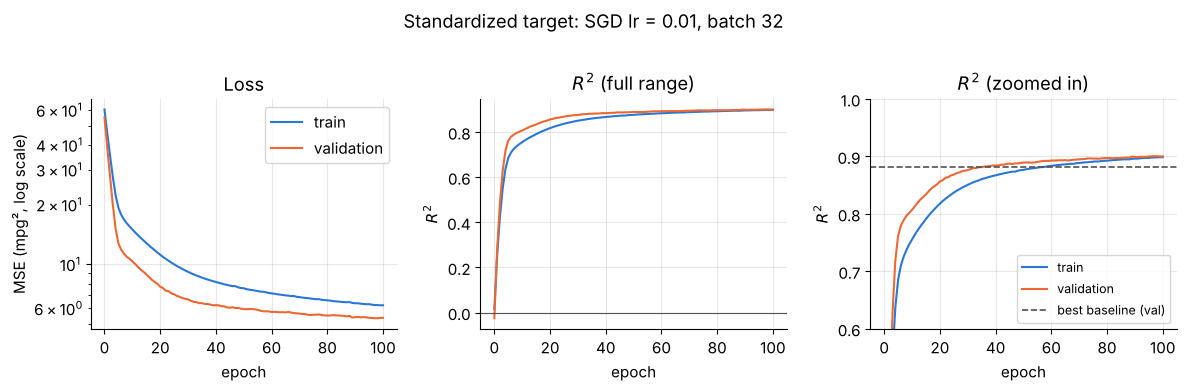

validation R2: before training -0.025 | epoch 10 0.807 | final 0.9000 | best 0.9005 at epoch 98
validation R2 increased in 82 of 100 epochs


In [61]:
std_cfg = replace(REFERENCE, standardize_target=True)
std_run = run_experiment(std_cfg, print_every=25)
print(f"target scaling learned from the training set: mu_y = {std_run.y_mean:.3f}, sigma_y = {std_run.y_std:.3f}")
plot_history(std_run.history, "Standardized target: SGD lr = 0.01, batch 32")
hs = std_run.history
print(f"validation R2: before training {hs['val_r2'].iloc[0]:.3f} | epoch 10 {hs['val_r2'].loc[10]:.3f} | "
      f"final {hs['val_r2'].iloc[-1]:.4f} | best {hs['val_r2'].max():.4f} at epoch {hs['val_r2'].idxmax()}")
print("validation R2 increased in", int((hs["val_r2"].diff().loc[1:] > 0).sum()), "of 100 epochs")

The difference in *behavior* is striking. Training starts at $R^2 \approx 0$, and the curves rise
smoothly: the validation $R^2$ improves in the large majority of epochs instead of jumping around. The
final number happens to be close to the reference run's, so is standardization just cosmetic? A
single run cannot tell. Let us train both configurations with five different seeds (different
initial weights and batch orders) and compare.

In [62]:
def multi_seed(cfg: Config, seeds=range(10)):
    """Train cfg once per seed and return (table of validation R^2 and best epoch, list of runs)."""
    runs = [run_experiment(replace(cfg, seed=s)) for s in seeds]
    table = pd.DataFrame({"val_r2": [evaluate(r.model, val_big, r.y_mean, r.y_std)["r2"] for r in runs],
                          "best_epoch": [r.best_epoch for r in runs]},
                         index=pd.Index(list(seeds), name="seed"))
    return table, runs


raw_seeds, raw_seed_runs = multi_seed(REFERENCE, seeds=range(5))
std_seeds, std_seed_runs = multi_seed(std_cfg, seeds=range(5))
display(pd.DataFrame({"raw target": raw_seeds["val_r2"], "standardized target": std_seeds["val_r2"]}).T.round(4))
for name, d in [("raw target", raw_seeds), ("standardized target", std_seeds)]:
    print(f"{name:>20}: final validation R2 = {d['val_r2'].mean():.4f} ± {d['val_r2'].std():.4f} (mean ± std over 5 seeds)")

seed,0,1,2,3,4
raw target,0.8708,0.8545,0.8952,0.8570,0.8820
standardized target,0.9039,0.8953,0.8983,0.9038,0.8997


          raw target: final validation R2 = 0.8719 ± 0.0171 (mean ± std over 5 seeds)
 standardized target: final validation R2 = 0.9002 ± 0.0037 (mean ± std over 5 seeds)


Now the picture is clear. With the raw target, the final score depends heavily on the seed (the
run simply stops wherever the jumpy trajectory happens to be after epoch 100). With the
standardized target every seed lands in a narrow band, and the average is higher. From now on
**every experiment standardizes the target**.

> **Key idea.** Standardize the inputs *and* the regression target with training-set statistics,
> and undo the target scaling when you report predictions and metrics. It costs two numbers
> ($\mu_y$, $\sigma_y$), which you must store together with the model (Section 13).

> **Quick check.** Does standardizing the target change the $R^2$ of a *given* set of predictions?

<details>
<summary>Answer</summary>

No. $R^2 = 1 - SS_\text{res}/SS_\text{tot}$, and if both $y$ and $\hat y$ are transformed by the
same map $v \mapsto (v - \mu_y)/\sigma_y$, every residual and every deviation from the mean is
divided by $\sigma_y$, so both sums shrink by $\sigma_y^2$ and the ratio stays the same. (The
MSE, in contrast, shrinks by $\sigma_y^2$, and that is why we always convert back to mpg before
reporting it.) Standardization changes how *training* behaves, not how a prediction is scored.
</details>

### 10.2 And if we forget to scale the features?

Section 4.3 predicted trouble from the condition number of raw features. Let us watch it happen:
the same network and the standardized target, but **unscaled** features (imputed and one-hot
encoded, so `weight` is in the thousands), for a range of learning rates.

In [63]:
raw_feat_train = AutoMPGDataset(prep.features(train_df).to_numpy(np.float32), y_train)
raw_feat_val = AutoMPGDataset(prep.features(val_df).to_numpy(np.float32), y_val)

torch.manual_seed(SEED)
with torch.no_grad():
    out0 = FlexibleMLP(N_FEATURES, (64, 64))(raw_feat_train.X)
print(f"untrained outputs on raw features: mean {out0.mean().item():.1f}, std {out0.std().item():.1f} "
      "(on the standardized-target scale, where the targets have mean 0 and std 1!)")

rows = []
with np.errstate(over="ignore", invalid="ignore"):  # diverging runs overflow on purpose here
    for lr in [1e-2, 1e-3, 1e-4, 1e-5, 1e-6]:
        run = run_experiment(replace(std_cfg, lr=lr), train_ds=raw_feat_train, val_ds=raw_feat_val)
        hr = run.history
        diverged = not np.isfinite(hr["val_loss"].iloc[-1])
        rows.append({"learning rate": f"{lr:g}", "epochs completed": len(hr) - 1,
                     "val R2 before training": hr["val_r2"].iloc[0],
                     "val R2 at the end": "diverged (NaN)" if diverged else f"{hr['val_r2'].iloc[-1]:.3f}"})
display(pd.DataFrame(rows).set_index("learning rate"))

untrained outputs on raw features: mean 186.8, std 55.1 (on the standardized-target scale, where the targets have mean 0 and std 1!)


,epochs completed,val R2 before training,val R2 at the end
learning rate,,,
0.01,1,-44100.6632,diverged (NaN)
0.001,1,-44100.6632,diverged (NaN)
0.0001,2,-44100.6632,diverged (NaN)
1e-05,100,-44100.6632,-0.103
1e-06,100,-44100.6632,-0.146


There is **no good learning rate**. With raw features the untrained network already outputs
values in the hundreds, so the starting $R^2$ is about $-44{,}000$. Large learning rates blow up
within one or two epochs (the loss becomes infinite, then NaN). Rates small enough to stay stable
are far too slow for the directions that matter: after 100 epochs the model is still worse than
predicting the mean. This is the condition-number story of Section 4.3 in action: the `weight`
column (thousands) dictates the largest stable step, and the small-scale columns barely move.
Feature scaling is not a cosmetic detail for neural networks. It is what makes training possible.

> **Common pitfall.** A training loss that becomes `nan` almost always means divergence: a
> learning rate that is too high, unscaled inputs or targets, or a bug such as dividing by a
> zero standard deviation. Check the inputs and the scaling first, then lower the learning rate.

---
## 11. Experiments: one change at a time

We now have a solid starting point: standardized features and target, SGD with learning rate
0.01, batches of 32, 100 epochs, two hidden layers of 64 units. Call it the **base
configuration**. Each experiment below changes **one** setting and keeps everything else fixed,
including the seed, so that any difference in the curves is caused by that one change (plus a
little randomness, which Section 11.7 measures). All decisions are made on the **validation**
set, and the test set stays locked.

A small helper runs a dictionary of labeled configurations, plots their training and validation
$R^2$ curves side by side, and returns a summary table.

In [64]:
BASE = std_cfg                       # standardized target, SGD lr 0.01, batch 32, 100 epochs


def sweep(variants: dict, title: str, r2_floor: float = 0.6, colors=None, **run_kwargs):
    """Train each labeled config, plot train/val R^2 curves and return (summary table, runs)."""
    runs, rows = {}, []
    if colors is None:                                          # light -> dark for ordered sweeps
        colors = BLUES[-len(variants):] if len(variants) <= len(BLUES) else [None] * len(variants)
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
    with np.errstate(over="ignore", invalid="ignore"):          # a diverging variant may overflow
        for i, (label, cfg) in enumerate(variants.items()):
            run = runs[label] = run_experiment(cfg, **run_kwargs)
            h = run.history
            color = colors[i]
            axes[0].plot(h.index, h["train_r2"], color=color, label=label)
            axes[1].plot(h.index, h["val_r2"], color=color, label=label)
            rows.append({"variant": label, "final val R2": h["val_r2"].iloc[-1],
                         "best val R2": h["val_r2"].max(), "best epoch": int(h["val_r2"].idxmax()),
                         "final train R2": h["train_r2"].iloc[-1], "epochs run": len(h) - 1})
    for ax, part in zip(axes, ["training", "validation"]):
        ax.set(xlabel="epoch", ylabel="$R^2$", title=f"{part} $R^2$", ylim=(r2_floor, 1.0))
    axes[1].legend(fontsize=9, loc="lower right")
    fig.suptitle(title, y=1.02)
    plt.tight_layout()
    plt.show()
    return pd.DataFrame(rows).set_index("variant").round(4), runs

### 11.1 The learning rate

The learning rate $\eta$ is usually the most important setting. Too small, and training crawls.
Too large, and the updates overshoot. Learning rates are best explored on a **logarithmic**
grid (each value about 3 times the previous one), because what matters is the order of magnitude.

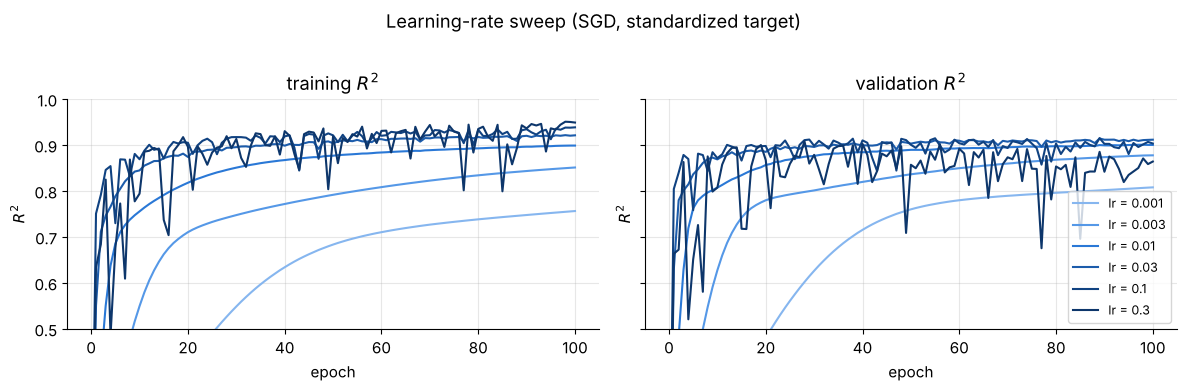

,final val R2,best val R2,best epoch,final train R2,epochs run
variant,,,,,
lr = 0.001,0.8077,0.8077,100,0.7562,100
lr = 0.003,0.8775,0.8775,100,0.8509,100
lr = 0.01,0.9000,0.9005,98,0.8987,100
lr = 0.03,0.9115,0.9141,89,0.9210,100
lr = 0.1,0.9031,0.9149,89,0.9383,100
lr = 0.3,0.8639,0.9084,28,0.9488,100


for comparison, RAW target with lr = 0.03: stopped after 2 epoch(s), final validation loss = nan


In [65]:
lr_table, lr_runs = sweep({f"lr = {lr:g}": replace(BASE, lr=lr) for lr in [0.001, 0.003, 0.01, 0.03, 0.1, 0.3]},
                          "Learning-rate sweep (SGD, standardized target)", r2_floor=0.5)
display(lr_table)
with np.errstate(over="ignore", invalid="ignore"):
    raw_fast = run_experiment(replace(REFERENCE, lr=0.03))   # RAW target with a 3x larger learning rate
print(f"for comparison, RAW target with lr = 0.03: stopped after {len(raw_fast.history) - 1} epoch(s), "
      f"final validation loss = {raw_fast.history['val_loss'].iloc[-1]}")

Reading the sweep:

- **Too small** ($\eta \le 0.003$): the curves are still rising at epoch 100, and training and
  validation $R^2$ are both low. The model is **underfitting** because it has not finished
  learning.
- **The sweet spot** ($\eta$ around 0.03 to 0.1): the highest validation scores.
- **Too large** ($\eta = 0.3$): the training $R^2$ is the highest of all, but the validation curve
  peaks early and then drifts down and jitters. The model fits the training cars ever more
  closely, noise included, and generalizes worse: **overfitting**, helped along by big noisy steps.
- **Standardizing the target bought stability.** With the raw target, $\eta = 0.03$ already
  diverges (the last validation loss printed above is `nan`), while the standardized version is
  stable even at $\eta = 0.3$.

> **Olympiad tip.** When a model trains badly, sweep the learning rate over powers of about 3
> *before* touching anything else. It is the cheapest experiment with the biggest effect, and
> the best value for one architecture or batch size is rarely the best for another.

### 11.2 The batch size (and why we shuffle)

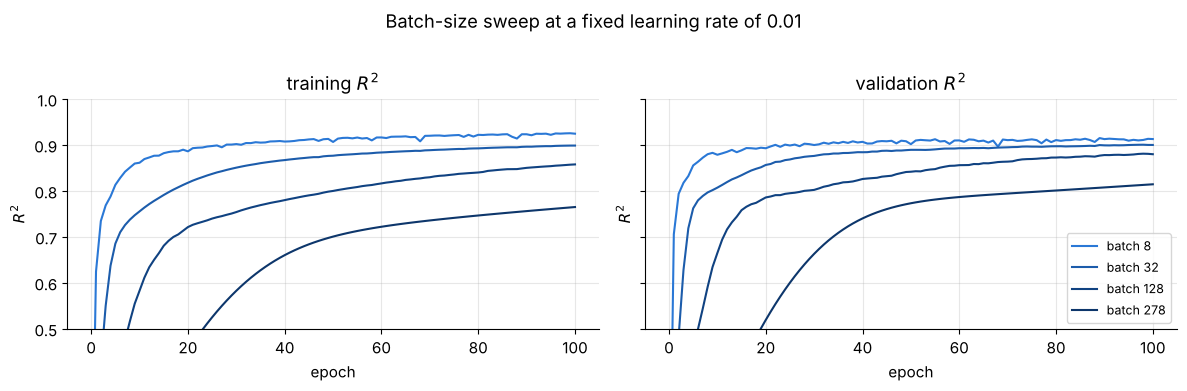

,updates per epoch,final val R2,best val R2,best epoch,final train R2,epochs run
variant,,,,,,
batch 8,35,0.9128,0.9150,89,0.9246,100
batch 32,9,0.9000,0.9005,98,0.8987,100
batch 128,3,0.8799,0.8810,98,0.8577,100
batch 278,1,0.8144,0.8144,100,0.7649,100


In [66]:
bs_table, bs_runs = sweep({f"batch {b}": replace(BASE, batch_size=b) for b in [8, 32, 128, 278]},
                          "Batch-size sweep at a fixed learning rate of 0.01", r2_floor=0.5)
bs_table.insert(0, "updates per epoch", [math.ceil(len(train_ds) / b) for b in [8, 32, 128, 278]])
display(bs_table)

With a fixed learning rate and a fixed number of epochs, **smaller batches win** here, but mostly
for a boring reason: a batch of 8 gives 35 updates per epoch, a full batch of 278 gives just one.
After 100 epochs the full-batch model has taken only 100 small steps and is still underfitting.

For small learning rates, $k$ consecutive SGD steps of size $\eta$ move the parameters about as
far as one step of size $k\eta$ on a $k$ times larger batch. This suggests the **linear scaling
rule**: when you multiply the batch size by $k$, multiply the learning rate by $k$ as well (as
long as it stays below the stability limit). Let us test it.

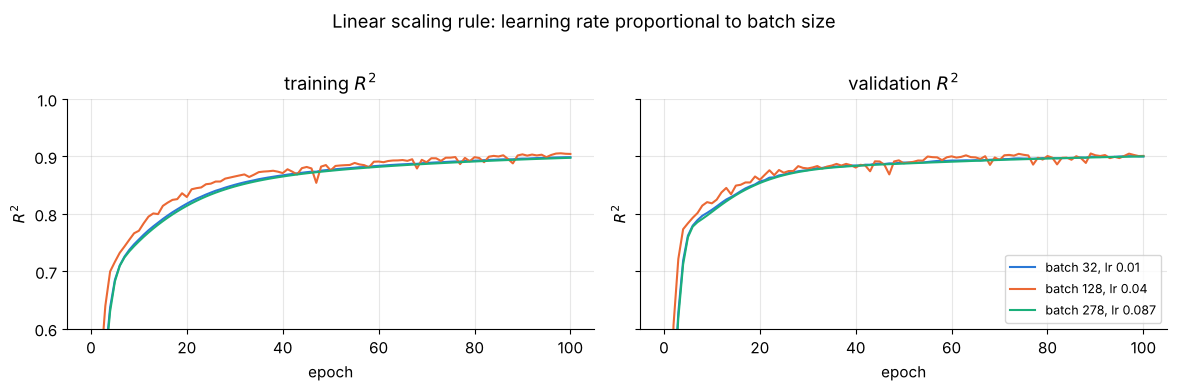

,final val R2,best val R2,best epoch,final train R2,epochs run
variant,,,,,
"batch 32, lr 0.01",0.9000,0.9005,98,0.8987,100
"batch 128, lr 0.04",0.9009,0.9052,89,0.9044,100
"batch 278, lr 0.087",0.9002,0.9002,100,0.8977,100


In [67]:
scaled = {"batch 32, lr 0.01": BASE,
          "batch 128, lr 0.04": replace(BASE, batch_size=128, lr=0.04),
          "batch 278, lr 0.087": replace(BASE, batch_size=278, lr=0.01 * 278 / 32)}
scaled_table, _ = sweep(scaled, "Linear scaling rule: learning rate proportional to batch size",
                        colors=[C_TRAIN, C_VAL, C_TEST])
display(scaled_table)

With the learning rate scaled, all three batch sizes reach practically the same validation
$R^2$, and the larger batches need far fewer (cheaper per car) updates. Batch size and learning
rate are **coupled**: compare batch sizes only after re-tuning the learning rate.

**Why shuffle?** Our CSV file happens to be sorted by model year. Imagine the worst case, a
training set sorted by the *target* itself, read in the same order every epoch: each batch then
contains cars of nearly the same MPG, so consecutive updates pull the network towards "everything
is a gas-guzzler" and then towards "everything is efficient", and the last batches of every
epoch (always the most efficient cars) get the final word.

training set sorted by mpg, shuffle=False: final validation R2 = 0.8861


training set sorted by mpg, shuffle=True : final validation R2 = 0.9000


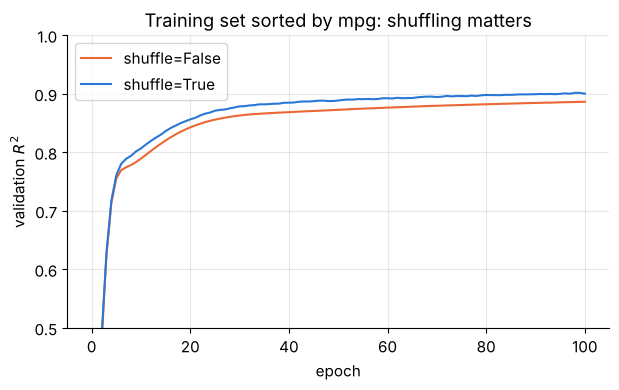

In [68]:
order = np.argsort(y_train, kind="stable")                    # training cars sorted by mpg
sorted_train = AutoMPGDataset(X_train[order], y_train[order])

fig, ax = plt.subplots(figsize=(7, 3.8))
for shuffle, color in [(False, C_VAL), (True, C_TRAIN)]:
    run = run_experiment(BASE, train_ds=sorted_train, shuffle=shuffle)
    ax.plot(run.history.index, run.history["val_r2"], color=color, label=f"shuffle={shuffle}")
    print(f"training set sorted by mpg, shuffle={shuffle!s:5}: final validation R2 = "
          f"{run.history['val_r2'].iloc[-1]:.4f}")
ax.set(xlabel="epoch", ylabel="validation $R^2$", ylim=(0.5, 1.0),
       title="Training set sorted by mpg: shuffling matters")
ax.legend()
plt.show()

Same data, same seed, same everything except the order of the batches: the unshuffled run ends
clearly lower. Shuffling the **training** loader every epoch costs nothing and removes any
dependence on how the file happens to be sorted.

### 11.3 Optimizers: SGD, momentum and Adam

Plain SGD uses only the current mini-batch gradient $\mathbf{g}_t$. Two famous improvements:

**Momentum** keeps a running "velocity". In PyTorch's formulation below, $\beta$ is the `momentum`
argument of `torch.optim.SGD`. Its default is 0 (no momentum at all), so
`torch.optim.SGD(params, lr=...)` is plain SGD, and our `Config` passes $\beta = 0.9$ when
`optimizer="momentum"`:

$$
\mathbf{v}_t = \beta\,\mathbf{v}_{t-1} + \mathbf{g}_t, \qquad
\boldsymbol\theta_t = \boldsymbol\theta_{t-1} - \eta\,\mathbf{v}_t .
$$

If the gradient keeps pointing the same way, $\mathbf{v}_t$ grows towards
$\mathbf{g}/(1-\beta) = 10\,\mathbf{g}$: the ball rolls faster down a long gentle slope. If the
gradient keeps flipping sign (zig-zagging across a narrow valley), successive contributions
cancel. Momentum speeds up the slow directions and damps the oscillating ones.

**Adam** additionally rescales each parameter's step by a running estimate of the size of its
gradients. With $\beta_1 = 0.9$, $\beta_2 = 0.999$, $\epsilon = 10^{-8}$ and all operations taken
element by element:

$$
\mathbf{m}_t = \beta_1\mathbf{m}_{t-1} + (1-\beta_1)\,\mathbf{g}_t, \qquad
\mathbf{s}_t = \beta_2\mathbf{s}_{t-1} + (1-\beta_2)\,\mathbf{g}_t^2,
$$

$$
\hat{\mathbf{m}}_t = \frac{\mathbf{m}_t}{1-\beta_1^t}, \qquad
\hat{\mathbf{s}}_t = \frac{\mathbf{s}_t}{1-\beta_2^t}, \qquad
\boldsymbol\theta_t = \boldsymbol\theta_{t-1} - \eta\,\frac{\hat{\mathbf{m}}_t}{\sqrt{\hat{\mathbf{s}}_t} + \epsilon}.
$$

The divisions by $1-\beta^t$ ("bias correction") undo the fact that $\mathbf{m}$ and $\mathbf{s}$
start at zero. A neat consequence you can check by hand: at the first step
$\hat{\mathbf{m}}_1 = \mathbf{g}_1$ and $\hat{\mathbf{s}}_1 = \mathbf{g}_1^2$, so the update is
$\eta\,\mathbf{g}_1/(|\mathbf{g}_1| + \epsilon) \approx \eta\,\operatorname{sign}(\mathbf{g}_1)$:
**every parameter moves by about $\eta$, whatever the size of its gradient.**

In [69]:
for name, make in [("SGD ", lambda ps: torch.optim.SGD(ps, lr=0.1)), ("Adam", lambda ps: torch.optim.Adam(ps, lr=0.1))]:
    p = nn.Parameter(torch.zeros(3))
    p.grad = torch.tensor([0.001, -5.0, 300.0])            # gradients of wildly different sizes
    make([p]).step()
    print(f"{name} first step with lr = 0.1 moves the parameters to {p.detach().numpy().round(4)}")

SGD  first step with lr = 0.1 moves the parameters to [-1.e-04  5.e-01 -3.e+01]
Adam first step with lr = 0.1 moves the parameters to [-0.1  0.1 -0.1]


SGD's step is proportional to the gradient (from a ten-thousandth to 30 units). Adam moves all
three parameters by 0.1. This per-parameter normalization is why Adam is far less sensitive to
badly scaled problems and why its typical learning rate (about $10^{-3}$) is smaller than SGD's.
Now the experiment on our data:

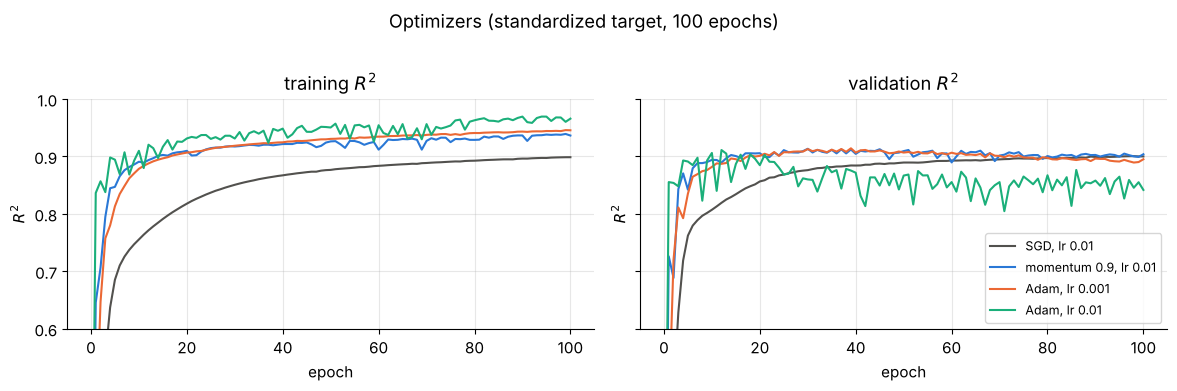

,final val R2,best val R2,best epoch,final train R2,epochs run
variant,,,,,
"SGD, lr 0.01",0.9000,0.9005,98,0.8987,100
"momentum 0.9, lr 0.01",0.9039,0.9133,30,0.9364,100
"Adam, lr 0.001",0.8951,0.9142,39,0.9456,100
"Adam, lr 0.01",0.8417,0.9112,12,0.9658,100


In [70]:
opt_variants = {"SGD, lr 0.01": BASE,
                "momentum 0.9, lr 0.01": replace(BASE, optimizer="momentum"),
                "Adam, lr 0.001": replace(BASE, optimizer="adam", lr=1e-3),
                "Adam, lr 0.01": replace(BASE, optimizer="adam", lr=1e-2)}
opt_table, opt_runs = sweep(opt_variants, "Optimizers (standardized target, 100 epochs)",
                            colors=[C_INK, C_TRAIN, C_VAL, C_TEST])
display(opt_table)

Momentum and Adam reach their best validation $R^2$ within roughly 10 to 40 epochs, while plain
SGD is still improving at epoch 100, and their peaks are slightly higher. But look at what
happens **after** the peak: the training $R^2$ keeps climbing towards 0.97 while the validation
$R^2$ falls. The faster optimizers do not just learn faster. They also start **overfitting**
sooner, fitting quirks of the 278 training cars that do not carry over to new cars. Two classic
remedies follow: stop at the right moment (Section 11.4) or penalize large weights (Section 11.5).

### 11.4 Early stopping with a best-model checkpoint

**Early stopping** watches the validation loss after every epoch:

1. if it is the best so far, remember the epoch and save a **copy** of the model's `state_dict`.
2. if it has not improved for `patience` consecutive epochs, stop training.
3. at the end, load the saved best weights back into the model.

The patience allows for noise: one bad epoch should not end training. `run_experiment` implements
exactly this when `cfg.patience` is set. The word **copy** matters, because `state_dict()` returns
*references* to the live parameter tensors:

In [71]:
torch.manual_seed(SEED)
demo_net = FlexibleMLP(N_FEATURES, (8,))
by_reference = demo_net.state_dict()                      # dict of references to the live tensors
by_copy = copy.deepcopy(demo_net.state_dict())            # an independent snapshot
with torch.no_grad():
    demo_net.net[0].bias += 1.0                           # training changes parameters IN PLACE
print("the 'reference' snapshot changed along with the model:", torch.equal(by_reference["net.0.bias"], demo_net.net[0].bias))
print("the deep-copied snapshot kept the old values:         ", not torch.equal(by_copy["net.0.bias"], demo_net.net[0].bias))

the 'reference' snapshot changed along with the model: True
the deep-copied snapshot kept the old values:          True


Without `copy.deepcopy`, your "best checkpoint" would silently follow the model to its final,
overfitted state. Now let us train Adam with a generous budget of 500 epochs and patience 20.

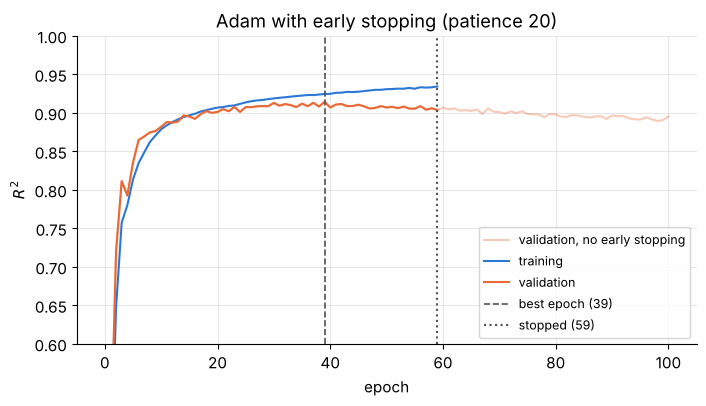

best epoch 39, stopped after epoch 59 (of at most 500); restored model: validation R2 = 0.9142, last epoch's validation R2 = 0.9034


In [72]:
ES_CFG = replace(BASE, optimizer="adam", lr=1e-3, epochs=500, patience=20)
es_run = run_experiment(ES_CFG)
he = es_run.history
restored = evaluate(es_run.model, val_big, es_run.y_mean, es_run.y_std)
no_es = opt_runs["Adam, lr 0.001"].history                 # the same run without early stopping

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(no_es.index, no_es["val_r2"], color=C_VAL, alpha=0.35, lw=1.5, label="validation, no early stopping")
ax.plot(he.index, he["train_r2"], color=C_TRAIN, label="training")
ax.plot(he.index, he["val_r2"], color=C_VAL, label="validation")
ax.axvline(es_run.best_epoch, color=C_INK, ls="--", lw=1.2, label=f"best epoch ({es_run.best_epoch})")
ax.axvline(he.index[-1], color=C_INK, ls=":", lw=1.5, label=f"stopped ({he.index[-1]})")
ax.set(xlabel="epoch", ylabel="$R^2$", ylim=(0.6, 1.0), title="Adam with early stopping (patience 20)")
ax.legend(fontsize=9, loc="lower right")
plt.show()
print(f"best epoch {es_run.best_epoch}, stopped after epoch {he.index[-1]} (of at most {ES_CFG.epochs}), and the "
      f"restored model: validation R2 = {restored['r2']:.4f}, last epoch's validation R2 = {he['val_r2'].iloc[-1]:.4f}")

Training stopped 20 epochs after the best epoch instead of running 500 epochs, and the returned
model is the checkpoint from the best epoch, not the slightly overfitted last one. The faint curve
shows where validation $R^2$ was heading without early stopping.

> **Common pitfall.** Early stopping *uses* the validation set to choose the number of epochs, so
> the restored model's validation score is optimistically biased (a small effect with one
> choice, a larger one with many). This is one more reason to keep a separate test set.

### ✏️ Exercise 11: an early-stopping helper

Write a class `EarlyStopper(patience, min_delta=0.0)` with a method `step(val_loss, model)`
that is called once per epoch and returns `True` when training should stop. It must keep:

- `best_loss` and `best_epoch` (epochs are counted from 1 by the number of `step` calls).
- `best_state`: an independent **copy** of `model.state_dict()` taken at the best epoch.

An epoch counts as an improvement only if `val_loss < best_loss - min_delta`. Training should
stop once there have been `patience` consecutive epochs without improvement.

In [73]:
# ✏️ Exercise 11: an early-stopping helper
class EarlyStopper:
    """Remember the best model seen so far and say when to stop."""

    def __init__(self, patience: int, min_delta: float = 0.0):
        # YOUR CODE HERE
        raise NotImplementedError

    def step(self, val_loss: float, model: nn.Module) -> bool:
        """Record one epoch and return True if training should stop now."""
        # YOUR CODE HERE
        raise NotImplementedError


def _test_ex11():
    net = nn.Linear(2, 1)
    stopper = EarlyStopper(patience=3)
    decisions = [stopper.step(v, net) for v in [5.0, 4.0, 4.5, 3.9, 3.95, 3.92, 3.91]]
    assert decisions == [False] * 6 + [True], f"stop decisions {decisions}: expected to stop at the 7th epoch"
    assert stopper.best_epoch == 4 and stopper.best_loss == 3.9, \
        f"best epoch/loss should be 4 / 3.9, got {stopper.best_epoch} / {stopper.best_loss}"
    s2 = EarlyStopper(patience=2, min_delta=0.05)
    decisions = [s2.step(v, net) for v in [5.0, 4.0, 3.98, 3.97]]
    assert decisions == [False, False, False, True], f"with min_delta=0.05, 3.98 and 3.97 are not improvements: {decisions}"
    assert s2.best_epoch == 2, f"best epoch should be 2, got {s2.best_epoch}"
    s3 = EarlyStopper(patience=5)
    s3.step(1.0, net)
    weight_at_best = net.weight.detach().clone()
    with torch.no_grad():
        net.weight += 10.0                                 # training continues and changes the weights
    s3.step(2.0, net)                                      # worse: the checkpoint must not change
    assert torch.equal(s3.best_state["weight"], weight_at_best), "best_state must be a COPY taken at the best epoch"
    s3.step(0.5, net)                                      # better: the checkpoint must be updated
    assert torch.equal(s3.best_state["weight"], net.weight.detach()), "update best_state when the loss improves"


run_check("Exercise 11", _test_ex11)

⏳ Exercise 11: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
class EarlyStopper:
    def __init__(self, patience, min_delta=0.0):
        self.patience, self.min_delta = patience, min_delta
        self.best_loss, self.best_epoch, self.best_state = float("inf"), 0, None
        self.epoch, self.bad_epochs = 0, 0

    def step(self, val_loss, model):
        self.epoch += 1
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss, self.best_epoch, self.bad_epochs = val_loss, self.epoch, 0
            self.best_state = copy.deepcopy(model.state_dict())
        else:
            self.bad_epochs += 1
        return self.bad_epochs >= self.patience
```
In a training loop you would write `if stopper.step(val_loss, model): break` after each epoch and
`model.load_state_dict(stopper.best_state)` after the loop.
</details>

### 11.5 Weight decay (L2 regularization)

Another way to fight overfitting is to discourage large weights. Add a penalty to the loss:

$$
\mathcal{L}_\lambda(\boldsymbol\theta) = \mathcal{L}(\boldsymbol\theta) + \frac{\lambda}{2}\lVert\boldsymbol\theta\rVert^2
\quad\Longrightarrow\quad
\nabla\mathcal{L}_\lambda = \nabla\mathcal{L} + \lambda\boldsymbol\theta .
$$

An SGD step then reads
$\boldsymbol\theta \leftarrow \boldsymbol\theta - \eta(\nabla\mathcal{L} + \lambda\boldsymbol\theta)
= (1 - \eta\lambda)\,\boldsymbol\theta - \eta\nabla\mathcal{L}$: before each ordinary step, every
weight is multiplied by a factor slightly below 1. It **decays** towards zero unless the data keeps
pushing it away. This is the neural-network cousin of ridge regression (Exercise 5). Smaller
weights mean a smoother function that is less able to memorize individual cars.

In PyTorch, `weight_decay=λ` adds $\lambda\boldsymbol\theta$ to the gradient. With Adam that sum
is then divided by $\sqrt{\hat{\mathbf{s}}_t}$, so parameters with large gradients are decayed
*less*. **AdamW** fixes this by applying the decay $\boldsymbol\theta \leftarrow
\boldsymbol\theta - \eta\lambda\boldsymbol\theta$ separately from the Adam step ("decoupled weight
decay"). Below we use Adam's built-in version and train for 300 epochs **without** early stopping,
so that we can watch overfitting develop.

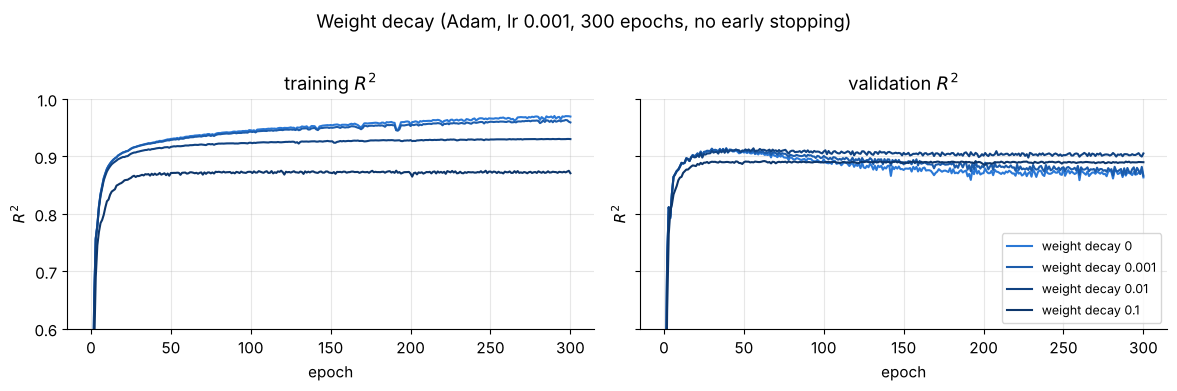

,final val R2,best val R2,best epoch,final train R2,epochs run,parameter norm
variant,,,,,,
weight decay 0,0.8635,0.9142,39,0.9695,300,10.3993
weight decay 0.001,0.8665,0.9141,39,0.9593,300,6.3983
weight decay 0.01,0.9052,0.9141,56,0.9302,300,2.8610
weight decay 0.1,0.8900,0.8919,63,0.8708,300,1.9093


In [74]:
wd_variants = {f"weight decay {wd:g}": replace(BASE, optimizer="adam", lr=1e-3, epochs=300, weight_decay=wd)
               for wd in [0.0, 1e-3, 1e-2, 1e-1]}
wd_table, wd_runs = sweep(wd_variants, "Weight decay (Adam, lr 0.001, 300 epochs, no early stopping)")
wd_table["parameter norm"] = [float(torch.cat([p.detach().ravel() for p in run.model.parameters()]).norm())
                              for run in wd_runs.values()]
display(wd_table)

- **No decay** ($\lambda = 0$): the model overfits steadily. After 300 epochs the training $R^2$
  is near 0.97 and the validation $R^2$ has slid well below its peak.
- **A moderate decay** ($\lambda = 10^{-2}$): the peak is about as high, and the validation curve
  *stays* near it, ending far above the undecayed model. The weights are visibly smaller (see
  the parameter norm).
- **Too much decay** ($\lambda = 10^{-1}$): the weights are held so small that the model cannot
  even fit the training data well (lower training $R^2$). That is **underfitting**.

Weight decay and early stopping are two dials for the same trade-off: a model flexible enough to
capture the curve but not so flexible that it memorizes noise. In practice they are often combined.

### 11.6 Width and depth

How big should the network be? Comparing sizes with a fixed number of epochs is unfair: a
bigger network may simply learn faster *and* overfit sooner. Early stopping removes that problem,
since every model is trained until its own validation loss stops improving. So we compare
architectures with Adam and early stopping (the configuration of Section 11.4), changing only
`hidden`.

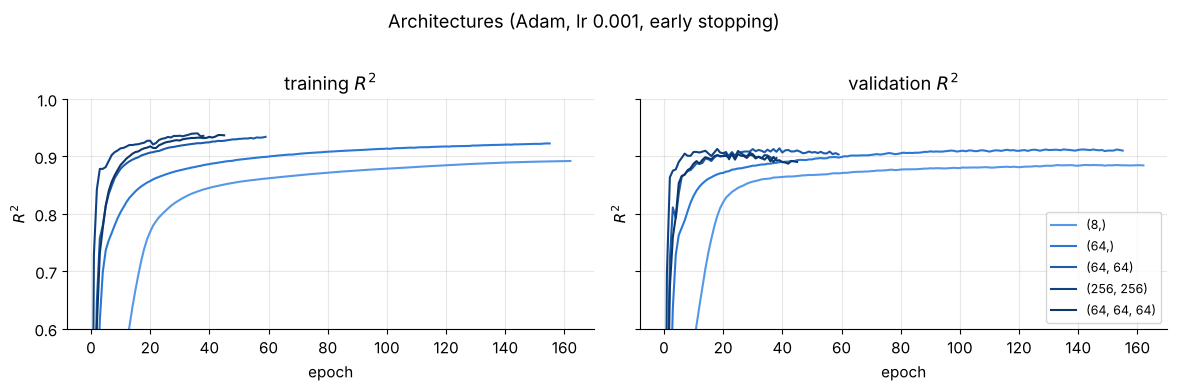

,parameters,parameters per training car,best val R2,best epoch,final train R2,epochs run
variant,,,,,,
"(8,)",89,0.3,0.8851,142,0.8921,162
"(64,)",705,2.5,0.9123,135,0.9226,155
"(64, 64)",4865,17.5,0.9142,39,0.9341,59
"(256, 256)",68609,246.8,0.9131,18,0.9359,38
"(64, 64, 64)",9025,32.5,0.9040,25,0.9368,45


In [75]:
arch_variants = {str(hid): replace(ES_CFG, hidden=hid) for hid in [(8,), (64,), (64, 64), (256, 256), (64, 64, 64)]}
arch_table, arch_runs = sweep(arch_variants, "Architectures (Adam, lr 0.001, early stopping)", r2_floor=0.6)
arch_table.insert(0, "parameters", [sum(p.numel() for p in run.model.parameters()) for run in arch_runs.values()])
arch_table.insert(1, "parameters per training car", (arch_table["parameters"] / len(train_ds)).round(1))
display(arch_table.drop(columns=["final val R2"]))

(With early stopping, "best val R2" is the score of the restored model.) What we learn:

- **Too small underfits.** Eight hidden units cannot represent the curve well and need many
  epochs to get there.
- **Beyond a modest size, capacity barely matters here.** One hidden layer of 64 units is almost
  as good as two, and the $256 \times 256$ network, with about 247 parameters *per training car*,
  is about as good as well. It simply reaches its best epoch much sooner, then early stopping
  halts it before it can memorize the data.
- **More depth did not help.** With 278 cars and a smooth target, a third hidden layer brings
  no benefit. Deep networks shine on images, audio and text, where the structure is hierarchical.
- Differences of a few thousandths are within the run-to-run noise we measure next, so do not
  over-interpret the ranking at the top.

> **Going deeper.** That a network with 68,609 parameters fit to 278 cars does not overfit
> catastrophically surprises people trained on classical statistics. Early stopping, small
> initial weights and the implicit preferences of gradient descent all keep the effective
> complexity far below the raw parameter count. Search for "double descent" and "implicit
> regularization" to explore this active research area.

### 11.7 How much is luck? Several seeds

Every run so far used one seed. A different seed changes the initial weights and the batch order,
and therefore the result. Before choosing a final configuration, we train each serious candidate
with **10 seeds** (using `multi_seed` from Section 10) and look at the mean and the spread of
its validation $R^2$.

In [76]:
CANDIDATES = {
    "momentum + early stopping": replace(BASE, optimizer="momentum", epochs=500, patience=20),
    "Adam + early stopping": ES_CFG,
    "Adam + weight decay 0.01 + early stopping": replace(ES_CFG, weight_decay=1e-2),
}
t0 = time.time()
seed_tables, seed_runs = {}, {}
for name, cfg in CANDIDATES.items():
    seed_tables[name], seed_runs[name] = multi_seed(cfg)
print(f"trained {10 * len(CANDIDATES)} models in {time.time() - t0:.0f} s")

summary = pd.DataFrame({name: {"mean val R2": t["val_r2"].mean(), "std": t["val_r2"].std(),
                               "min": t["val_r2"].min(), "max": t["val_r2"].max(),
                               "mean best epoch": t["best_epoch"].mean()}
                        for name, t in seed_tables.items()}).T
summary.loc["SGD, 100 epochs (Section 10, 5 seeds)"] = [std_seeds["val_r2"].mean(), std_seeds["val_r2"].std(),
                                                       std_seeds["val_r2"].min(), std_seeds["val_r2"].max(),
                                                       std_seeds["best_epoch"].mean()]
display(summary.round(4))

trained 30 models in 49 s


,mean val R2,std,min,max,mean best epoch
momentum + early stopping,0.9116,0.0045,0.9043,0.9193,37.7
Adam + early stopping,0.9138,0.0038,0.9076,0.9206,44.0
Adam + weight decay 0.01 + early stopping,0.9132,0.0031,0.9088,0.9172,58.9
"SGD, 100 epochs (Section 10, 5 seeds)",0.9002,0.0037,0.8953,0.9039,97.2


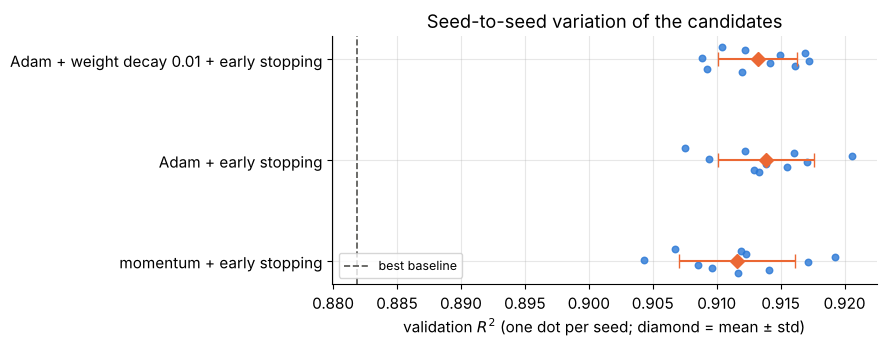

chosen configuration: Adam + early stopping
Config(hidden=(64, 64), lr=0.001, optimizer='adam', momentum=0.9, weight_decay=0.0, batch_size=32, epochs=500, standardize_target=True, patience=20, seed=42)


In [77]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, (name, t) in enumerate(seed_tables.items()):
    jitter = np.linspace(-0.12, 0.12, len(t))
    ax.scatter(t["val_r2"], i + jitter, color=C_TRAIN, s=22, alpha=0.8, zorder=3)
    ax.errorbar(t["val_r2"].mean(), i, xerr=t["val_r2"].std(), fmt="D", color=C_VAL, ms=7, capsize=5, zorder=4)
ax.set_yticks(range(len(seed_tables)), list(seed_tables))
ax.axvline(BEST_BASELINE_VAL_R2, color=C_INK, ls="--", lw=1.2, label="best baseline")
ax.set(xlabel="validation $R^2$ (one dot per seed, diamond = mean ± std)", title="Seed-to-seed variation of the candidates")
ax.legend(fontsize=9, loc="lower left")
plt.tight_layout()
plt.show()

FINAL_NAME = summary.drop(index="SGD, 100 epochs (Section 10, 5 seeds)")["mean val R2"].idxmax()
FINAL_CFG = CANDIDATES[FINAL_NAME]
print("chosen configuration:", FINAL_NAME)
print(FINAL_CFG)

Three lessons:

1. **Seed noise is real but small here.** A standard deviation of a few thousandths means that a
   single-run difference of, say, 0.003 between two settings proves nothing.
2. **With 10 seeds, the three candidates are statistically indistinguishable.** To compare two
   *means*, the right yardstick is the uncertainty of the means, not the spread $s$ of single runs
   (the `std` column). Averaging 10 runs divides the noise by $\sqrt{10}$, so the difference of two
   10-seed means has a **standard error** of $\sqrt{s_1^2/10 + s_2^2/10}$, about 0.002 here. The
   largest gap between the candidates (0.0022) is only about one standard error (Welch's $t$-test
   gives $t \approx 1.2$ and $p \approx 0.25$: even if two configurations were equally good, a gap
   at least this large in either direction would appear about one time in four). Beware the
   shortcut "the means differ by less than one $s$, so they tie": with 10 seeds each, a gap of one
   $s$ is already more than 2 standard errors, which would be a real difference. By the same
   yardstick, all three clearly beat 100 epochs of plain SGD (gaps of more than 5 standard errors)
   and the best linear baseline.
3. We choose the candidate with the highest mean validation $R^2$ (printed above), knowing that
   any of the three would be a reasonable choice. When candidates tie, prefer the simplest and
   cheapest one.

Note what this spread does **not** measure: the uncertainty that comes from having only 80
validation cars. Another set of 80 cars would give different numbers for *all* models. The next
section quantifies that with the bootstrap.

> **Olympiad tip.** When you report "method A beats method B", give the mean and standard
> deviation over several seeds and say how many seeds you used. A single lucky run is the most
> common way to fool yourself in machine learning.

---
## 12. Final evaluation on the test set

Every decision has been made: preprocessing, architecture, optimizer, learning rate, stopping
rule. Now, and only now, we unlock the test set. The rule is simple: whatever the test score
turns out to be, we **report it and do not go back** to tune anything, because a test set that
influences decisions turns into a second validation set and stops being an honest judge.

### 12.1 The scores

The deployed model is the chosen configuration trained with our main seed (42). For context we
also report the baselines (fitted on the training set back in Section 5), the spread over the
10 seeds of Section 11.7 and the average prediction of those 10 models (an **ensemble**).

In [78]:
final_run = run_experiment(FINAL_CFG)                         # seed 42: the model we deploy
final_model, Y_MEAN, Y_STD = final_run.model, final_run.y_mean, final_run.y_std
test_big = DataLoader(test_ds, batch_size=512)
final_val_pred, _ = predict(final_model, val_big, Y_MEAN, Y_STD)
final_test_pred, _ = predict(final_model, test_big, Y_MEAN, Y_STD)

A_test = np.c_[np.ones(len(X_test)), X_test].astype(np.float64)
ref_test_pred, _ = predict(ref.model, test_big, ref.y_mean, ref.y_std)     # reference run of Section 9
models_val = {"mean predictor": np.full(len(y_val), train_mean), "linear regression": pred_lin_val,
              "linear on gallons/100 mi": pred_gal_val, "MLP reference (Section 9)": ref_val_pred,
              "MLP (final model)": final_val_pred}
models_test = {"mean predictor": np.full(len(y_test), train_mean), "linear regression": A_test @ theta,
               "linear on gallons/100 mi": 100.0 / (A_test @ theta_g), "MLP reference (Section 9)": ref_test_pred,
               "MLP (final model)": final_test_pred}
final_table = pd.DataFrame({name: {"val R2": r2_score_np(y_val, models_val[name]),
                                   "test R2": r2_score_np(y_test, p), "test RMSE": rmse(y_test, p),
                                   "test MAE": mae(y_test, p)} for name, p in models_test.items()}).T
display(final_table.round(4))

seed_test_preds = [predict(r.model, test_big, r.y_mean, r.y_std)[0] for r in seed_runs[FINAL_NAME]]
seed_test_r2 = np.array([r2_score_np(y_test, p) for p in seed_test_preds])
ensemble_pred = np.mean(seed_test_preds, axis=0)
ref_seed_test_r2 = np.array([r2_score_np(y_test, predict(r.model, test_big, r.y_mean, r.y_std)[0])
                             for r in raw_seed_runs])                      # the 5 raw-target runs of Section 10
print(f"final configuration over 10 seeds:    test R2 = {seed_test_r2.mean():.4f} ± {seed_test_r2.std(ddof=1):.4f} "
      f"(min {seed_test_r2.min():.4f}, max {seed_test_r2.max():.4f})")
print(f"reference configuration over 5 seeds: test R2 = {ref_seed_test_r2.mean():.4f} ± {ref_seed_test_r2.std(ddof=1):.4f} "
      f"(min {ref_seed_test_r2.min():.4f}, max {ref_seed_test_r2.max():.4f})")
print(f"ensemble (average of the 10 models): test R2 = {r2_score_np(y_test, ensemble_pred):.4f}, "
      f"RMSE = {rmse(y_test, ensemble_pred):.3f} mpg")
print(f"test-set mpg: std {y_test.std():.2f} (validation {y_val.std():.2f}, training {y_train.std():.2f})")

,val R2,test R2,test RMSE,test MAE
mean predictor,-0.0049,-0.0021,8.4682,6.8839
linear regression,0.8424,0.7723,4.0369,3.0862
linear on gallons/100 mi,0.8819,0.8098,3.6888,2.6262
MLP reference (Section 9),0.8995,0.8297,3.4906,2.1856
MLP (final model),0.9142,0.8271,3.5179,2.3796


final configuration over 10 seeds:    test R2 = 0.8293 ± 0.0058 (min 0.8187, max 0.8372)
reference configuration over 5 seeds: test R2 = 0.8129 ± 0.0195 (min 0.7782, max 0.8246)
ensemble (average of the 10 models): test R2 = 0.8311, RMSE = 3.477 mpg
test-set mpg: std 8.46 (validation 7.33, training 7.84)


The ranking from the validation set holds: the final MLP beats the physics-inspired linear
model, which beats plain linear regression, which beats the mean. Averaging the 10 seeds gives a
small extra gain, a cheap trick worth remembering.

Now look at the **reference** MLP of Section 9. On the test set it scores about the same as the
final model, although it was clearly worse on validation. Was all the tuning useless? The seed
statistics answer that. The reference *configuration* is unreliable: over 5 seeds its test $R^2$
spreads about three times as widely as the final configuration's, and its mean is lower. Seed 42
scored higher on these 40 cars than any of those five runs: a lucky draw. Tuning bought a better
average and, above all, far more reliable training, exactly as the validation experiments
predicted. Judging two
configurations by one run each would have told us nothing.

But **every** model has clearly larger errors on the test set than on the validation set (test
RMSEs more than 1 mpg higher), and every model except the trivial mean predictor, whose $R^2$ is
about 0 on any set, scores a clearly lower $R^2$. Did we overfit the validation set?

### 12.2 How precise is a score measured on 40 cars?

The baselines answer most of the question: they were never tuned on the validation set, yet their
errors grow almost as much as the tuned MLP's. These 40 test cars are simply **harder** than the
80 validation cars. (Their
larger spread, printed above, would on its own push $R^2$ *up*, because $R^2 = 1 - \text{MSE}/\sigma_y^2$.
The drop comes from larger errors, which Section 12.3 traces to a handful of cars.) To see
how much a score computed on so few cars can move, use the **bootstrap**: draw 40 cars *with
replacement* from the test set, recompute $R^2$, repeat 2000 times, and look at the spread. To
compare two models fairly, resample the **same** cars for both (a *paired* bootstrap) and look at
the difference of their scores.

,MLP R2: 2.5%,MLP R2: 97.5%,MLP minus best baseline: 2.5%,MLP minus best baseline: 97.5%,share of resamples where the MLP wins
validation,0.862,0.947,0.003,0.070,0.988
test,0.698,0.916,-0.067,0.113,0.638


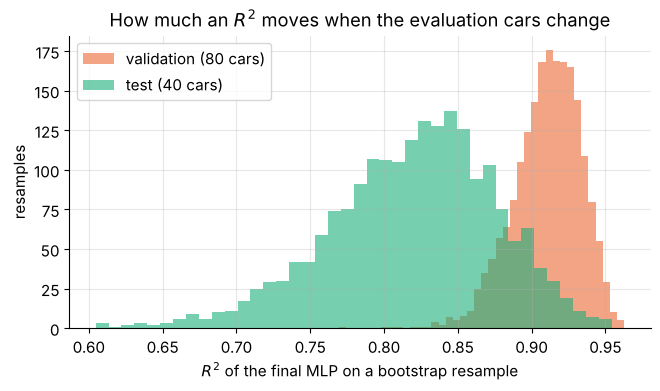

In [79]:
def bootstrap_r2(y_true: np.ndarray, preds: dict, n_boot: int = 2000, seed: int = SEED) -> pd.DataFrame:
    """R^2 of every model on n_boot bootstrap resamples (the same resampled rows for all models)."""
    g = np.random.default_rng(seed)
    y_true = np.asarray(y_true, dtype=np.float64)
    rows = []
    for _ in range(n_boot):
        idx = g.integers(0, len(y_true), len(y_true))       # sample rows with replacement
        rows.append({name: r2_score_np(y_true[idx], np.asarray(p)[idx]) for name, p in preds.items()})
    return pd.DataFrame(rows)


boot = {"validation": bootstrap_r2(y_val, {k: models_val[k] for k in ["linear on gallons/100 mi", "MLP (final model)"]}),
        "test": bootstrap_r2(y_test, {k: models_test[k] for k in ["linear on gallons/100 mi", "MLP (final model)"]})}
ci_rows = {}
for split, b in boot.items():
    diff = b["MLP (final model)"] - b["linear on gallons/100 mi"]
    ci_rows[split] = {"MLP R2: 2.5%": b["MLP (final model)"].quantile(0.025),
                      "MLP R2: 97.5%": b["MLP (final model)"].quantile(0.975),
                      "MLP minus best baseline: 2.5%": diff.quantile(0.025),
                      "MLP minus best baseline: 97.5%": diff.quantile(0.975),
                      "share of resamples where the MLP wins": (diff > 0).mean()}
display(pd.DataFrame(ci_rows).T.round(3))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
for split, color in [("validation", C_VAL), ("test", C_TEST)]:
    ax.hist(boot[split]["MLP (final model)"], bins=40, alpha=0.6, color=color, label=f"{split} ({len(y_val) if split == 'validation' else len(y_test)} cars)")
ax.set(xlabel="$R^2$ of the final MLP on a bootstrap resample", ylabel="resamples",
       title="How much an $R^2$ moves when the evaluation cars change")
ax.legend()
plt.show()

Two sobering facts:

- The 95% bootstrap interval for the test $R^2$ is **wide**: with 40 cars, a few unusual ones
  swing the score by around a tenth (the interval is more than 0.2 wide). The validation interval
  (80 cars) is narrower but not narrow. Our validation score sits right at the top edge of the test
  interval, so the validation–test gap is about as large as sampling noise alone can explain. It may
  be bad luck in the test draw, but a small optimistic bias from making every choice on the
  validation set is also plausible: from validation to test, the tuned MLP lost 0.087 of $R^2$,
  while the two linear baselines and the untuned reference MLP each lost about 0.07.
- The *paired* comparison is more informative than two separate intervals, because both models
  face the same hard cars. On the validation set the MLP beats the physics-inspired baseline in
  almost every resample. On the 40 test cars it wins in only about two thirds of them, and the
  interval for the difference includes zero. An honest summary: "the MLP is somewhat better than
  a well-designed linear model on this dataset, and the test set alone is too small to prove it."

> **Key idea.** Every score is an estimate with an error bar. With small evaluation sets, the
> uncertainty from *which cars you happened to test on* is usually much larger than the
> seed-to-seed noise of training.

### 12.3 Residual analysis

A **residual** is $y - \hat y$: positive when the model *under*-predicts. Plotting residuals reveals
patterns that one summary number hides.

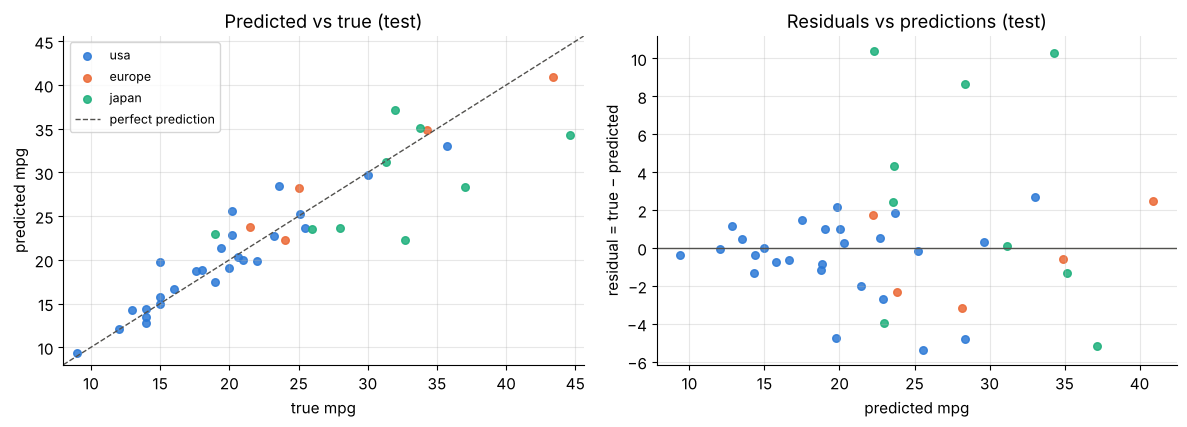

,name,mpg,predicted,residual,weight,horsepower,model_year,origin
333,datsun 280-zx,32.7,22.31,10.39,2910,132.0,80,japan
329,honda civic 1500 gl,44.6,34.30,10.30,1850,67.0,80,japan
320,datsun 510 hatchback,37.0,28.34,8.66,2434,92.0,80,japan
365,ford granada gl,20.2,25.57,-5.37,3060,88.0,81,usa
384,honda civic (auto),32.0,37.17,-5.17,1965,67.0,82,japan
336,ford mustang cobra,23.6,28.40,-4.80,2905,NaN,80,usa


In [80]:
test_res = y_test.astype(np.float64) - final_test_pred
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for origin, color in ORIGIN_COLORS.items():
    m = (test_df["origin"] == origin).to_numpy()
    axes[0].scatter(y_test[m], final_test_pred[m], s=30, color=color, alpha=0.85, label=origin)
    axes[1].scatter(final_test_pred[m], test_res[m], s=30, color=color, alpha=0.85, label=origin)
lims = [min(y_test.min(), final_test_pred.min()) - 1, max(y_test.max(), final_test_pred.max()) + 1]
axes[0].plot(lims, lims, color=C_INK, lw=1, ls="--", label="perfect prediction")
axes[0].set(xlim=lims, ylim=lims, xlabel="true mpg", ylabel="predicted mpg", title="Predicted vs true (test)")
axes[1].axhline(0, color=C_INK, lw=1)
axes[1].set(xlabel="predicted mpg", ylabel="residual = true − predicted", title="Residuals vs predictions (test)")
axes[0].legend(fontsize=9)
plt.tight_layout()
plt.show()

worst = test_df.assign(predicted=final_test_pred, residual=test_res).reindex(
    test_df.index[np.argsort(-np.abs(test_res))])
display(worst[["name", "mpg", "predicted", "residual", "weight", "horsepower", "model_year", "origin"]].head(6).round(2))

Most test cars sit close to the diagonal, but three **very efficient Japanese cars from 1980** (the
top rows of the table) lie far *below* it in the left panel, and far above zero in the right panel:
the model under-predicts them by about 9 to 10 mpg. Each of them gets far more miles per gallon
than training cars of similar weight, horsepower and model year, so nothing in the training data
tells the model to expect such efficiency at those specifications, and these three residuals
dominate the squared error of the whole test set. Notice also that the residuals fan out
for larger predictions: efficient cars are harder to predict in absolute terms. (Predicting
gallons per 100 miles, as in Section 5.5, is one way to tame that.)

### 12.4 Errors by origin and by cylinder count

In [81]:
by_group = test_df.assign(abs_err=np.abs(test_res), residual=test_res)
for col in ["origin", "cylinders"]:
    table = by_group.groupby(col).agg(cars=("residual", "size"), MAE=("abs_err", "mean"),
                                      mean_residual=("residual", "mean"))
    display(table.round(3))

,cars,MAE,mean_residual
origin,,,
europe,5,2.057,-0.370
japan,9,5.193,2.864
usa,26,1.468,-0.473


,cars,MAE,mean_residual
cylinders,,,
3,1,3.971,-3.971
4,18,2.942,0.997
6,12,2.713,0.004
8,9,0.633,-0.264


The errors are far from uniform. American cars are predicted best, and the Japanese cars have
the largest MAE with a clearly **positive mean residual** (the model systematically
under-predicts them, driven by the cars above). By cylinder count, the 8-cylinder cars (big,
heavy, very similar to each other) are easy. But look at the `cars` column: some groups contain
only a handful of cars, and one contains a single car. Group-level errors on a 40-car test set
are *hints* to investigate, not conclusions.

> **Going deeper.** Checking errors per subgroup is the beginning of **fairness** and
> **robustness** analysis. Here the groups are car origins, but the same habit applies to
> people: a model with a good average error can still serve some groups much worse than others.

### 12.5 Which features does the model rely on? Permutation importance

**Idea:** if the model relies on a feature, scrambling that feature should hurt. Take the test
matrix, randomly **permute one column** (shuffle its values across cars, which keeps its
distribution but breaks its link with the target and with the other features), and measure how
much $R^2$ drops. Repeat with several random permutations and average.

The three one-hot `origin` columns are permuted **together**, as one group: shuffling
`origin_usa` alone would create impossible cars that belong to two regions or to none.

,mean drop in R2,std
weight,0.3456,0.0958
model_year,0.2228,0.0767
horsepower,0.1378,0.0460
displacement,0.0549,0.0258
origin,0.0507,0.0351
acceleration,0.0322,0.0166
cylinders,0.0137,0.0080


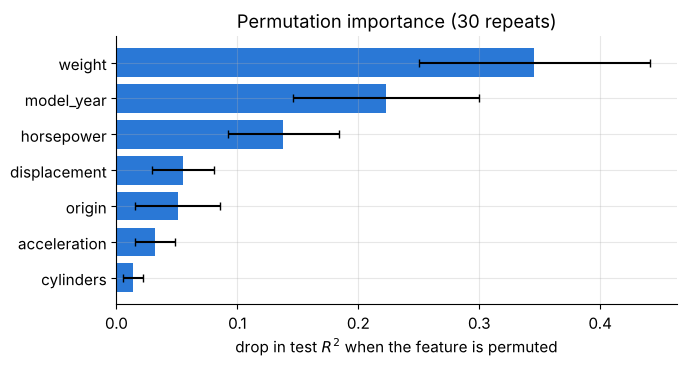

In [82]:
def predict_matrix(model: nn.Module, X: np.ndarray, y_mean: float, y_std: float) -> np.ndarray:
    """Predictions in mpg (float64) for a standardized feature matrix X of shape (n, 9)."""
    model.eval()
    with torch.no_grad():
        out = model(torch.as_tensor(X, dtype=torch.float32, device=DEVICE)).cpu().numpy()
    return out.astype(np.float64) * y_std + y_mean


FEATURE_GROUPS = {name: [prep.feature_names_.index(name)] for name in NUMERIC}
FEATURE_GROUPS["origin"] = [i for i, n in enumerate(prep.feature_names_) if n.startswith("origin_")]


def permutation_importance_groups(predict_fn, X: np.ndarray, y: np.ndarray, groups: dict,
                                  n_repeats: int = 30, seed: int = SEED) -> pd.DataFrame:
    """Mean and std of the drop in R^2 when the columns of each group are permuted together."""
    g = np.random.default_rng(seed)
    base = r2_score_np(y, predict_fn(X))
    result = {}
    for name, cols in groups.items():
        drops = []
        for _ in range(n_repeats):
            X_perm = X.copy()
            X_perm[:, cols] = X[g.permutation(len(X))][:, cols]    # same row shuffle for the whole group
            drops.append(base - r2_score_np(y, predict_fn(X_perm)))
        result[name] = {"mean drop in R2": np.mean(drops), "std": np.std(drops)}
    return pd.DataFrame(result).T.sort_values("mean drop in R2", ascending=False)


importance = permutation_importance_groups(lambda X: predict_matrix(final_model, X, Y_MEAN, Y_STD),
                                           X_test, y_test, FEATURE_GROUPS)
display(importance.round(4))

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(importance.index[::-1], importance["mean drop in R2"][::-1], xerr=importance["std"][::-1],
        color=C_TRAIN, capsize=3)
ax.set(xlabel="drop in test $R^2$ when the feature is permuted", title="Permutation importance (30 repeats)")
plt.tight_layout()
plt.show()

**Weight** matters most, followed by **model year** and **horsepower**.
Acceleration and cylinders matter least. This agrees with the physics (heavier cars need more energy per mile)
and the history (efficiency improved quickly after the oil crises). Compare it with the fragile
linear coefficients of Section 5.4, where displacement even had the "wrong" sign.

Read permutation importance with three caveats:

1. **It describes the model, not the world.** A large importance means "this model uses the
   feature", not "this feature causes MPG".
2. **Correlated features share and blur credit.** Weight, displacement, horsepower and cylinders
   carry overlapping information. Permuting one of them also produces unrealistic combinations
   (a heavy car with a tiny engine), so the measured drop mixes "lost information" with "the model
   extrapolating".
3. **Small data, big error bars.** On 40 test cars the standard deviations are substantial, and the
   exact order of the middle features is not reliable.

### 12.6 How does the prediction change with one feature? Partial dependence

Permutation importance says *how much* a feature matters, not *how*. A **partial dependence**
(PD) curve answers the second question: set the feature to a value $v$ for **every** car in a
reference set (we use the training cars), predict, and average:

$$
\text{PD}(v) = \frac{1}{n}\sum_{i=1}^n f\big(\mathbf{x}_i \text{ with feature } j \text{ set to } v\big).
$$

The individual curves inside the average (one per car) are called **ICE** curves (individual
conditional expectation). We work with raw values (pounds, years) and let the fitted
preprocessor do the scaling, exactly as at prediction time.

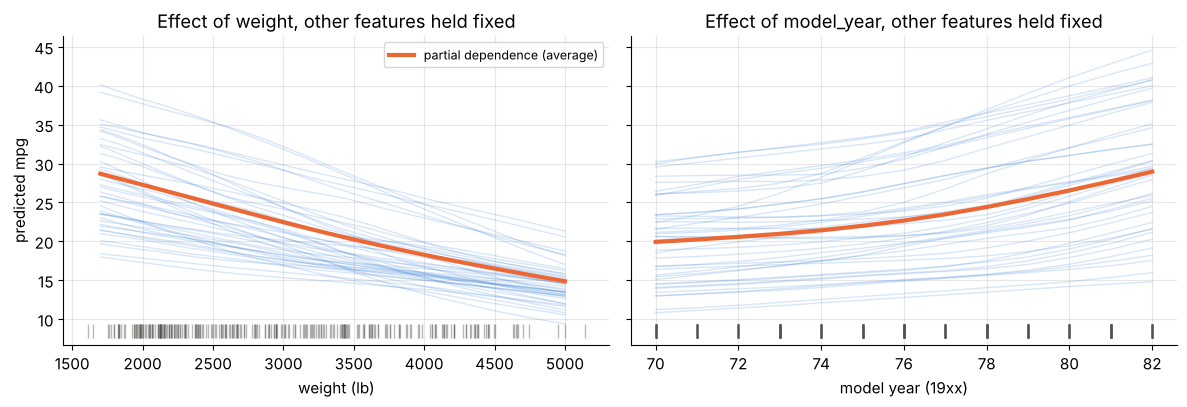

PD for weight:   {1700: 28.7, 2700: 23.9, 3700: 19.4, 4700: 15.8} ... 5000: 14.9
PD for model year: {70: 19.9, 73: 20.9, 76: 22.7, 79: 25.4, 82: 28.9}


In [83]:
def ice_curves(feature: str, grid: np.ndarray, df: pd.DataFrame = train_df) -> np.ndarray:
    """Predictions (cars x grid points) when `feature` is set to each grid value for every car."""
    curves = []
    for value in grid:
        modified = df.copy()
        modified[feature] = value
        curves.append(predict_matrix(final_model, prep.transform(modified), Y_MEAN, Y_STD))
    return np.array(curves).T


pd_specs = [("weight", np.linspace(1700, 5000, 34), "weight (lb)"),
            ("model_year", np.arange(70, 83), "model year (19xx)")]
ice_rows = rng.choice(len(train_df), size=40, replace=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
pd_results = {}
for ax, (feature, grid, label) in zip(axes, pd_specs):
    ice = ice_curves(feature, grid)
    pd_results[feature] = pd.Series(ice.mean(axis=0), index=grid)
    for row in ice_rows:
        ax.plot(grid, ice[row], color=C_TRAIN, alpha=0.18, lw=1)
    ax.plot(grid, ice.mean(axis=0), color=C_VAL, lw=3, label="partial dependence (average)")
    ax.plot(train_df[feature], np.full(len(train_df), 8.5), "|", color=C_INK, alpha=0.4, ms=10)
    ax.set(xlabel=label, title=f"Effect of {feature}, other features held fixed")
axes[0].set_ylabel("predicted mpg")
axes[0].legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

w_pd = pd_results["weight"]
print("PD for weight:  ", {int(k): round(v, 1) for k, v in w_pd.iloc[[0, 10, 20, 30]].items()}, "...",
      f"{int(w_pd.index[-1])}: {w_pd.iloc[-1]:.1f}")
print("PD for model year:", {int(k): round(v, 1) for k, v in pd_results["model_year"].iloc[::3].items()})

(The tick marks near the bottom show where the training cars actually are.)

- **Weight:** the average prediction falls from about 29 mpg at 1,700 lb to about 15 mpg at
  5,000 lb, and the curve **flattens**: the first extra 1,000 lb cost noticeably more MPG than
  the last 1,000 lb. The network discovered the $1/\text{weight}$ shape of Section 3.6 by itself.
- **Model year:** a gain of about 9 mpg over the period, and the curve **steepens** towards 1980,
  when fuel-economy rules and post-oil-crisis designs arrived.
- The ICE curves are **not** parallel. For weight they converge towards the right: an extra
  1,000 lb costs an otherwise efficient car more MPG than an already thirsty one. For model year
  they fan out: the newest designs gained the most where efficiency was already high. These are
  **interactions**, which a plain linear model cannot represent. Much of the pattern is what the
  reciprocal relationship of Section 3.6 predicts: if gallons per 100 miles $g$ were exactly
  additive in weight and year, a small change $\Delta g$ would change $\text{mpg} = 100/g$ by
  about $-100\,\Delta g/g^2$, which is largest for cars with a small $g$, the efficient ones.

> **Common pitfall.** Partial dependence holds the *other* features fixed. For correlated
> features this creates cars that do not exist (a 5,000-lb car with a small four-cylinder
> engine), where the model is extrapolating. Trust the curve where the data is dense (the tick
> marks), and be skeptical elsewhere. Accumulated local effects (ALE) plots are a refinement
> designed for correlated features.

---
## 13. Saving, loading and predicting for a new car

### 13.1 What has to be saved?

A trained network alone is useless: it expects 9 **standardized** numbers in a fixed order and
returns a **standardized** prediction. To predict for a new car you need every number that was
learned from the training set:

| piece | learned in | needed for |
|---|---|---|
| network weights (`state_dict`) and architecture (`hidden`) | Sections 8–11 | the forward pass |
| horsepower medians per cylinder count (+ global median) | Section 4.1 | filling a missing horsepower |
| the frozen origin categories, in order | Section 4.2 | building the one-hot columns |
| feature means $\mu_j$ and standard deviations $\sigma_j$ | Section 4.3 | scaling the inputs |
| target mean $\mu_y$ and standard deviation $\sigma_y$ | Section 10 | converting outputs back to mpg |
| training ranges of the numeric features | (new) | warning about extrapolation |

We store all of it in **one checkpoint dictionary** saved with `torch.save`. Everything in it is
a tensor or a plain Python number, string, list or dict. That matters, because PyTorch can then
load it with `weights_only=True`, which refuses to run arbitrary code. Loading an untrusted
*pickle* file (the format `torch.save` uses under the hood) can execute any code it contains,
so never load checkpoints from untrusted sources without that flag.

In [84]:
CHECKPOINT_PATH = DATA_DIR / "auto_mpg_mlp_checkpoint.pt"

checkpoint = {
    "model_state": final_model.state_dict(),
    "in_features": N_FEATURES,
    "hidden": list(FINAL_CFG.hidden),
    "numeric_columns": list(NUMERIC),
    "origins": list(prep.origins_),
    "feature_names": list(prep.feature_names_),
    "hp_median_by_cyl": {int(k): float(v) for k, v in prep.hp_median_by_cyl_.items()},
    "hp_median": float(prep.hp_median_),
    "feature_mean": prep.scaler_.mean_.tolist(),
    "feature_std": prep.scaler_.scale_.tolist(),
    "y_mean": float(Y_MEAN),
    "y_std": float(Y_STD),
    "train_ranges": {c: [float(train_df[c].min()), float(train_df[c].max())] for c in NUMERIC},
    "config": repr(FINAL_CFG),
    "torch_version": str(torch.__version__),       # TorchVersion -> plain str (weights_only-safe)
}
torch.save(checkpoint, CHECKPOINT_PATH)
print(f"saved {CHECKPOINT_PATH} ({CHECKPOINT_PATH.stat().st_size / 1024:.1f} KB) with keys:")
print(list(checkpoint))

saved data/auto_mpg_mlp_checkpoint.pt (23.4 KB) with keys:
['model_state', 'in_features', 'hidden', 'numeric_columns', 'origins', 'feature_names', 'hp_median_by_cyl', 'hp_median', 'feature_mean', 'feature_std', 'y_mean', 'y_std', 'train_ranges', 'config', 'torch_version']


### 13.2 Loading into a fresh model

Loading is the mirror image: build a new, *untrained* model with the same architecture, then copy
the saved tensors into it with `load_state_dict`. By default `load_state_dict` is **strict**: if
a name or shape does not match, it raises an error instead of silently skipping parameters. The
loaded model must reproduce the original predictions exactly.

In [85]:
loaded = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=True)
fresh_model = FlexibleMLP(loaded["in_features"], tuple(loaded["hidden"])).to(DEVICE)
before, _ = predict(fresh_model, test_big, loaded["y_mean"], loaded["y_std"])
print("untrained fresh model, test R2:", round(r2_score_np(y_test, before), 4))
result = fresh_model.load_state_dict(loaded["model_state"])
print("load_state_dict:", result)
after, _ = predict(fresh_model, test_big, loaded["y_mean"], loaded["y_std"])
print("after loading, identical to the final model's test predictions:", np.array_equal(after, final_test_pred))

wrong = FlexibleMLP(N_FEATURES, (32, 32))
try:
    wrong.load_state_dict(loaded["model_state"])
except RuntimeError as err:
    print("loading into a (32, 32) network fails loudly:", str(err).splitlines()[1].strip()[:90], "...")

untrained fresh model, test R2: -0.1886
load_state_dict: <All keys matched successfully>
after loading, identical to the final model's test predictions: True
loading into a (32, 32) network fails loudly: size mismatch for net.0.weight: copying a param with shape torch.Size([64, 9]) from checkp ...


> **Going deeper.** To *resume training* later (rather than just predict), also save the
> optimizer's `state_dict()` (Adam's running averages $\mathbf{m}$ and $\mathbf{s}$, momentum
> buffers) and the epoch number. Otherwise the restarted optimizer begins from scratch.

### 13.3 An inference helper for raw car descriptions

Finally, wrap everything into a small class that accepts cars described the way a person would
describe them (raw units, text origin, possibly missing horsepower) and returns MPG. It rebuilds
the preprocessing from the stored numbers, so it does not need the training data at all.

In [86]:
class MPGPredictor:
    """Predict mpg for raw car descriptions, using only the numbers stored in a checkpoint."""

    def __init__(self, ckpt: dict, device=DEVICE):
        self.model = FlexibleMLP(ckpt["in_features"], tuple(ckpt["hidden"])).to(device)
        self.model.load_state_dict(ckpt["model_state"])
        self.model.eval()
        self.device = device
        self.numeric, self.origins = list(ckpt["numeric_columns"]), list(ckpt["origins"])
        self.hp_by_cyl, self.hp_median = dict(ckpt["hp_median_by_cyl"]), float(ckpt["hp_median"])
        self.mu, self.sigma = np.asarray(ckpt["feature_mean"]), np.asarray(ckpt["feature_std"])
        self.y_mean, self.y_std = float(ckpt["y_mean"]), float(ckpt["y_std"])
        self.ranges = dict(ckpt["train_ranges"])

    def features(self, cars: pd.DataFrame) -> np.ndarray:
        """Raw rows -> standardized float32 matrix, exactly like AutoMPGPreprocessor.transform."""
        missing_cols = [c for c in self.numeric + ["origin"] if c not in cars.columns]
        if missing_cols:
            raise ValueError(f"missing columns: {missing_cols}")
        unknown = set(cars["origin"]) - set(self.origins)
        if unknown:
            raise ValueError(f"unknown origin(s) {sorted(unknown)}: expected one of {self.origins}")
        X = cars[self.numeric].astype(float)
        X["horsepower"] = X["horsepower"].fillna(cars["cylinders"].map(self.hp_by_cyl).fillna(self.hp_median))
        for c in self.origins:
            X[f"origin_{c}"] = (cars["origin"] == c).astype(float)
        return ((X.to_numpy() - self.mu) / self.sigma).astype(np.float32)

    def out_of_range(self, cars: pd.DataFrame) -> list[str]:
        """Human-readable warnings for values outside the training range (extrapolation)."""
        notes = []
        for col, (lo, hi) in self.ranges.items():
            for i, v in cars[col].items():
                if pd.notna(v) and not lo <= v <= hi:
                    notes.append(f"row {i}: {col} = {v} is outside the training range [{lo:g}, {hi:g}]")
        return notes

    @torch.no_grad()
    def predict(self, cars) -> np.ndarray:
        """mpg predictions for a DataFrame or a list of dicts."""
        cars = cars if isinstance(cars, pd.DataFrame) else pd.DataFrame(cars)
        for note in self.out_of_range(cars):
            print("⚠️ extrapolation:", note)
        X = torch.as_tensor(self.features(cars), device=self.device)
        return self.model(X).cpu().numpy().astype(np.float64) * self.y_std + self.y_mean


predictor = MPGPredictor(loaded)
print("same features as the training-time preprocessor:", np.allclose(predictor.features(val_df), X_val, atol=1e-6))
print("same predictions as the final model on the test set:",
      np.allclose(predictor.predict(test_df), final_test_pred, atol=1e-4))

same features as the training-time preprocessor: True
same predictions as the final model on the test set: True


Now some new cars. The first two are typical of their era, the third has an unknown horsepower
(it will be filled with the stored 6-cylinder median), and the fourth is a modern-looking
lightweight car that lies outside the data the model has seen.

In [87]:
new_cars = pd.DataFrame([
    {"cylinders": 4, "displacement": 98, "horsepower": 70, "weight": 2100, "acceleration": 16.5, "model_year": 82, "origin": "japan"},
    {"cylinders": 8, "displacement": 350, "horsepower": 160, "weight": 4100, "acceleration": 13.5, "model_year": 75, "origin": "usa"},
    {"cylinders": 6, "displacement": 225, "horsepower": None, "weight": 3300, "acceleration": 16.0, "model_year": 78, "origin": "usa"},
    {"cylinders": 4, "displacement": 90, "horsepower": 75, "weight": 1500, "acceleration": 15.0, "model_year": 82, "origin": "europe"},
])
mpg_pred = predictor.predict(new_cars)
display(new_cars.assign(predicted_mpg=mpg_pred.round(1), liters_per_100km=(235.215 / mpg_pred).round(1)))

try:
    predictor.predict([{"cylinders": 4, "displacement": 120, "horsepower": 90, "weight": 2500,
                        "acceleration": 15.0, "model_year": 80, "origin": "korea"}])
except ValueError as err:
    print("ValueError:", err)

⚠️ extrapolation: row 3: weight = 1500 is outside the training range [1613, 5140]


,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,predicted_mpg,liters_per_100km
0,4,98,70.0,2100,16.5,82,japan,36.4,6.5
1,8,350,160.0,4100,13.5,75,usa,15.2,15.4
2,6,225,NaN,3300,16.0,78,usa,20.8,11.3
3,4,90,75.0,1500,15.0,82,europe,40.7,5.8


ValueError: unknown origin(s) ['korea']; expected one of ['europe', 'japan', 'usa']


The predictions are plausible (an efficient early-1980s Japanese compact, a thirsty mid-1970s V8)
and the helper flags the car that lies outside the training range instead of silently trusting
its prediction. An origin the model has never seen is rejected with a clear message rather than
encoded as some arbitrary vector.

> **Common pitfall.** Re-fitting the scaler (or `pd.get_dummies`) on the new cars at prediction
> time. With a single car, "standardizing" would turn every feature into 0 (or NaN), and
> `get_dummies` would produce one column instead of three. Always *reuse* the training-time
> numbers, as `MPGPredictor` does.

---
## 14. Reproducibility and leakage checklist

### 14.1 Reproducibility

A result you cannot reproduce is a result you cannot debug, compare or trust. Here is what this
notebook does, and why:

| practice | where | why |
|---|---|---|
| seed Python, NumPy and PyTorch (`set_seed`) | Setup | the same random numbers on every run |
| seed the model's initialization per run (`torch.manual_seed(cfg.seed)`) | `run_experiment` | experiments differ *only* in what you changed |
| a separate, seeded `torch.Generator` for shuffling | `run_experiment` | the batch order does not depend on what ran before |
| `random_state` in every split | Section 2 | the same cars in each split |
| one CPU thread (`torch.set_num_threads(1)`) | Setup | avoids tiny run-to-run differences from parallel summation order (and is fastest for a tiny model) |
| store the config, versions and preprocessing numbers with the weights | Section 13 | the checkpoint fully describes the model |
| report several seeds, not one | Section 11.7 | separates real effects from luck |

On a GPU, some operations are non-deterministic by default, and `torch.use_deterministic_algorithms(True)`
forces deterministic versions (sometimes slower) or raises an error where none exists. A quick
test that seeding works: run the same short experiment twice.

In [88]:
first = run_experiment(replace(BASE, epochs=5))
second = run_experiment(replace(BASE, epochs=5))
print("two runs with the same config give identical histories:", first.history.equals(second.history))
third = run_experiment(replace(BASE, epochs=5, seed=SEED + 1))
print("a different seed gives a different history:            ", not first.history.equals(third.history))

two runs with the same config give identical histories:

 True


a different seed gives a different history:             True


### 14.2 Leakage

**Data leakage** means that information which would not be available at prediction time, usually
information about the evaluation cars, influences the model. It makes scores look better than
the model really is. A checklist for this notebook's pipeline:

1. **Split first**, before any statistic is computed (Section 2).
2. **Explore the training set only** (Section 3).
3. **Fit every preprocessing step on the training set only**: horsepower medians, the origin
   categories, the feature scaler (Section 4) and the target scaler (Section 10). Then *apply*
   those numbers unchanged to validation, test and new cars.
4. **Make every choice on the validation set**: learning rate, architecture, optimizer, weight
   decay, early-stopping epoch, final configuration (Sections 9–11).
5. **Touch the test set once**, at the very end, and report what it says (Section 12).
6. **Watch for near-duplicates across splits.** The same car model can appear in several model
   years. If one copy is in training and another in the test set, the test becomes easier than
   the real task. Splitting by car *name* (a **group split**) is the stricter alternative.
7. **Ask what "new data" means.** If the goal were to predict *future* cars, a random split
   would be too optimistic: training on 1982 cars to predict 1979 cars is not possible in real
   life. A **time-based split** (train on early years, test on later years) would be the honest
   choice.

The cell below measures point 6 for our split.

In [89]:
shared_val = val_df["name"].isin(train_df["name"]).sum()
shared_test = test_df["name"].isin(train_df["name"]).sum()
print(f"validation cars whose exact name also appears in training: {shared_val} of {len(val_df)}")
print(f"test cars whose exact name also appears in training:       {shared_test} of {len(test_df)}")

validation cars whose exact name also appears in training: 17 of 80
test cars whose exact name also appears in training:       13 of 40


About a fifth of the validation cars and a third of the test cars share their exact name with a
training car (the same model, typically from another model year or with another engine). The
network never sees names, but it does see similar rows, so our evaluation is somewhat easier
than predicting a model that was never built before. Whether that counts as leakage depends on
the question: for "a car like the ones we know" it is fine, and for "a brand-new model" a group
split by name is the honest choice (idea 3 in Section 16.2). In other domains the same issue can
be severe: with several medical scans per patient, one patient in both training and test can
inflate scores dramatically.

### ✏️ Exercise 12: an automatic leakage detector

A preprocessing **pipeline** is a function `pipeline(train_df, other_df) -> (X_train, X_other)`
that returns feature matrices for training rows and for some other rows (validation, test or new
cars). It is **leak-free** if

- (a) `X_train` does not depend on `other_df` at all, and
- (b) the features of one row of `other_df` do not depend on the *other* rows of `other_df`
  (a new car's features cannot depend on which other cars happen to arrive with it).

Write `is_leaky(pipeline, train_df, other_df)` that returns `True` if either property is
violated. Strategy: run the pipeline once on the original data, then again after drastically
changing every numeric column (`NUMERIC`) of all rows of `other_df` **except the first**, and
compare. The checker tries one honest pipeline and three classic leaks.

In [90]:
# ✏️ Exercise 12: an automatic leakage detector
def is_leaky(pipeline, train_df: pd.DataFrame, other_df: pd.DataFrame) -> bool:
    """True if pipeline's training features depend on other_df, or if the features of other_df's
    first row depend on the remaining rows of other_df."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex12():
    def honest(tr, other):
        p = AutoMPGPreprocessor().fit(tr)
        return p.transform(tr), p.transform(other)

    def scaler_fit_on_everything(tr, other):
        p = AutoMPGPreprocessor().fit(tr)
        f_tr, f_other = p.features(tr).to_numpy(), p.features(other).to_numpy()
        sc = StandardScaler().fit(np.vstack([f_tr, f_other]))            # statistics include other rows
        return sc.transform(f_tr), sc.transform(f_other)

    def scaler_fit_per_split(tr, other):
        p = AutoMPGPreprocessor().fit(tr)
        return p.transform(tr), StandardScaler().fit_transform(p.features(other).to_numpy())

    def median_from_everything(tr, other):
        med = pd.concat([tr, other])["horsepower"].median()               # imputation uses other rows
        fill = lambda d: d.assign(horsepower=d["horsepower"].fillna(med))
        p = AutoMPGPreprocessor().fit(fill(tr))
        return p.transform(fill(tr)), p.transform(fill(other))

    cases = {"honest": (honest, False), "scaler fit on train + other": (scaler_fit_on_everything, True),
             "scaler fit separately on each split": (scaler_fit_per_split, True),
             "imputation median from train + other": (median_from_everything, True)}
    train_before, val_before = train_df.copy(), val_df.copy()
    for name, (pipe, expected) in cases.items():
        got = is_leaky(pipe, train_df, val_df)
        assert got is not None and bool(got) == expected, \
            f"pipeline '{name}': is_leaky returned {got}, expected {expected}"
    assert train_df.equals(train_before) and val_df.equals(val_before), "do not modify the input DataFrames"


run_check("Exercise 12", _test_ex12)

⏳ Exercise 12: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def is_leaky(pipeline, train_df, other_df):
    X_tr_1, X_other_1 = pipeline(train_df, other_df)
    changed = other_df.copy()
    changed[NUMERIC] = changed[NUMERIC].astype(float)
    rest = changed.index[1:]                                   # every row except the first
    changed.loc[rest, NUMERIC] = changed.loc[rest, NUMERIC] * 3.0 + 100.0
    X_tr_2, X_other_2 = pipeline(train_df, changed)
    train_changed = not np.allclose(X_tr_1, X_tr_2)            # violates (a)
    first_row_changed = not np.allclose(X_other_1[0], X_other_2[0])   # violates (b)
    return train_changed or first_row_changed
```
The honest pipeline passes both tests. Fitting the scaler on everything changes `X_train`,
fitting it per split changes the first validation row through the validation mean and standard
deviation, and the median computed from all rows changes the filled horsepower of the 4
training cars with missing values. Converting to float first avoids pandas' warning about
writing floats into integer columns. (A detector like this can prove that a leak exists, but not
that none exists: a leak that our particular change does not trigger would go unnoticed.)
</details>

---
## 15. Quiz

Twelve exam-style questions. Decide on your answer *before* opening the explanation. Each
explanation says why the right option is right and why each of the others is wrong.

**Q1.** You train the reference MLP on the *raw* mpg target. Before the first update, the
validation $R^2$ is about $-9.8$. What is the best explanation?

- A) The $R^2$ implementation has a bug: $R^2$ cannot be below $-1$.
- B) The untrained network predicts values near 0, about three standard deviations below the mean mpg.
- C) Half of the ReLU units are inactive at initialization.
- D) The validation set contains outliers.

<details>
<summary>Answer</summary>

**B.** A model that predicts (almost) a constant $c$ scores $R^2 \approx -((\bar y - c)/\sigma_y)^2$,
and $(23.1 - 0.2)/7.3 \approx 3.1$, so $R^2 \approx -9.8$. A is wrong: $R^2$ has no lower bound.
C is true but irrelevant: inactive units do not explain an offset of 23 mpg. D is wrong: outliers
would affect a trained model's errors, but the starting score is dominated by the offset.
</details>

**Q2.** A student removes `optimizer.zero_grad()` from the training loop. What happens?

- A) Nothing: `backward()` overwrites the gradients anyway.
- B) Each step uses the sum of all gradients computed so far in training, so the updates grow and training becomes erratic.
- C) PyTorch raises an error at the second `backward()` call.
- D) The model trains normally but more slowly.

<details>
<summary>Answer</summary>

**B.** `backward()` *adds* into `.grad`, so without clearing, step $t$ uses
$\mathbf{g}_1 + \dots + \mathbf{g}_t$, an ever-growing and stale direction. A is the
misconception this question targets. C is wrong: accumulating is legal (it is how gradient
accumulation works). D is wrong: the steps get *larger*, not smaller, and usually diverge or
oscillate.
</details>

**Q3.** Which preprocessing procedure is free of leakage?

- A) Fit `StandardScaler` on all 398 cars, then split.
- B) Split, then fit one scaler on the training set and another on the validation set.
- C) Split, then fit the scaler on the training set and use it to transform training, validation and test.
- D) Split, then fit the scaler on training + validation, since the test set is still untouched.

<details>
<summary>Answer</summary>

**C.** Statistics come from training data only and are applied unchanged everywhere. A leaks
validation and test statistics into training. B makes each validation car's features depend on
the other validation cars, which is impossible for a single new car. D leaks the validation set
into the features, so validation scores no longer measure generalization (it can be fine as a
deliberate *final refit* after model selection, but not during selection).
</details>

**Q4.** Which `DataLoader`s should use `shuffle=True`?

- A) All three.
- B) Only the training loader.
- C) Only the validation and test loaders, so the metrics are not biased by file order.
- D) None: shuffling makes results irreproducible.

<details>
<summary>Answer</summary>

**B.** Shuffling the training data gives fresh, uncorrelated mini-batches every epoch. For
evaluation the order does not change MSE or $R^2$ at all (so C's reason is false), and a fixed
order keeps predictions aligned with the rows of the DataFrame. D is wrong: a seeded generator
makes shuffling perfectly reproducible.
</details>

**Q5.** Why does the output layer of our regression MLP have **no** activation function?

- A) Activations are only allowed in hidden layers.
- B) A ReLU at the output would forbid negative predictions, yet standardized targets are negative for about half of the cars.
- C) It makes training faster but slightly less accurate.
- D) `nn.MSELoss` applies a sigmoid internally.

<details>
<summary>Answer</summary>

**B.** The output must be able to take any real value. A is false: classification heads often
use a sigmoid or softmax (sometimes folded into the loss). C is false: removing the output
activation is about *what values are reachable*, not speed. D is false: `nn.MSELoss` just
averages squared differences (`nn.BCEWithLogitsLoss` is the loss that applies a sigmoid).
</details>

**Q6.** The model returns shape `(32, 1)` (no `squeeze`), the targets have shape `(32,)`, and
the loss is `nn.MSELoss()(pred, target)`. What does the loss compute?

- A) The correct MSE, because PyTorch matches the shapes automatically.
- B) An error is raised immediately.
- C) The mean over a $32 \times 32$ matrix of every prediction minus every target (a warning is printed, but training runs).
- D) The MSE of only the first car.

<details>
<summary>Answer</summary>

**C.** Broadcasting turns `(32, 1) - (32,)` into `(32, 32)`. The result is finite, so training
"works" while pulling every prediction toward the batch's average target. A and B are what
people wrongly expect. PyTorch only warns. D has no basis.
</details>

**Q7.** Which statement about `model.eval()` and `torch.no_grad()` is correct?

- A) They do the same thing, so use either one.
- B) `model.eval()` switches layers such as dropout to inference behavior, and `torch.no_grad()` stops autograd from building a graph. Evaluation code should use both.
- C) `torch.no_grad()` also switches dropout off.
- D) `model.eval()` freezes the parameters so that `optimizer.step()` cannot change them.

<details>
<summary>Answer</summary>

**B.** They are independent switches. A and C confuse them: inside `no_grad` a model in training
mode still applies dropout. D is wrong: `eval()` only sets the `training` flag, and the optimizer can
still update parameters (freezing is done with `requires_grad_(False)`).
</details>

**Q8.** With SGD, batch size 32 and learning rate 0.01 work well. You switch to batch size
128 and want a similar training trajectory per epoch. Following the linear scaling rule, which
learning rate should you try first?

- A) 0.0025
- B) 0.01
- C) 0.02
- D) 0.04

<details>
<summary>Answer</summary>

**D.** Four times larger batches give four times fewer updates per epoch, so each update should
be about four times larger: $4 \times 0.01 = 0.04$ (Section 11.2 confirms it works here). A goes
the wrong way. B keeps the rate and underfits within the same number of epochs. C is a
square-root scaling, sometimes used with Adam, but not the linear rule.
</details>

**Q9.** An early-stopping implementation stores `best = model.state_dict()` (no copy) whenever
the validation loss improves, and calls `model.load_state_dict(best)` at the end. What is
restored?

- A) The weights from the best epoch, as intended.
- B) The weights from the last epoch, because `best` refers to the live parameter tensors.
- C) The initial weights.
- D) Nothing: `load_state_dict` raises an error.

<details>
<summary>Answer</summary>

**B.** `state_dict()` returns references, and training updates the tensors in place, so `best`
silently follows the model. Use `copy.deepcopy(model.state_dict())`. A is the intended but
broken behavior. C would need a copy made before training. D is wrong because the shapes
match perfectly.
</details>

**Q10.** Adam (learning rate $\eta$) takes its very first step. Parameter $u$ has gradient
$0.002$ and parameter $v$ has gradient $-40$. Approximately how far does each move?

- A) $u$ by $0.002\eta$ and $v$ by $40\eta$.
- B) Both by about $\eta$: $u$ decreases and $v$ increases.
- C) Both by about $\eta$: both decrease.
- D) Neither moves at the first step because the moment estimates start at zero.

<details>
<summary>Answer</summary>

**B.** After bias correction the first update is $\eta\,g/(|g| + \epsilon) \approx
\eta\,\operatorname{sign}(g)$, and the parameter moves *against* the gradient: $u$ (positive
gradient) goes down, $v$ (negative gradient) goes up. A describes SGD. C ignores the sign. D is
exactly what bias correction prevents.
</details>

**Q11.** For plain SGD with learning rate $\eta$ and `weight_decay` $\lambda$, which update does
PyTorch perform (with $\mathbf{g}$ the gradient of the data loss)?

- A) $\boldsymbol\theta \leftarrow \boldsymbol\theta - \eta\mathbf{g} - \lambda$
- B) $\boldsymbol\theta \leftarrow (1 - \eta\lambda)\,\boldsymbol\theta - \eta\mathbf{g}$
- C) $\boldsymbol\theta \leftarrow (1 - \lambda)\,\boldsymbol\theta - \eta\mathbf{g}$
- D) $\boldsymbol\theta \leftarrow \boldsymbol\theta - \eta\,\mathbf{g}/(1 + \lambda)$

<details>
<summary>Answer</summary>

**B.** PyTorch adds $\lambda\boldsymbol\theta$ to the gradient, so the step is
$\boldsymbol\theta - \eta(\mathbf{g} + \lambda\boldsymbol\theta)$, which rearranges to B. A
subtracts a constant instead of shrinking proportionally. C forgets that the decay is also
scaled by the learning rate. D rescales the gradient, which is not a penalty on the weights at all.
</details>

**Q12.** After model selection, every model (the mean predictor, both linear baselines and the
MLP) has a clearly larger RMSE on the 40-car test set than on the validation set, and the ranking
of the models is unchanged. What is the most reasonable conclusion?

- A) The MLP overfitted the validation set, so retune it on the test set.
- B) The test cars are harder and the test set is small, so the scores carry wide error bars. Report the test result as it is.
- C) The scaler leaked, so refit it on the test set.
- D) Use the validation scores in the report instead, since they are more favorable.

<details>
<summary>Answer</summary>

**B.** The baselines were never tuned on validation data, yet their errors grow too, which points to
harder test cars, and the bootstrap shows how much a 40-car score can move. A would turn the test
set into a second validation set and destroy the last honest estimate. C would *create* leakage.
D is cherry-picking: you choose with validation and report with test.
</details>

---
## 16. Summary and going further

### 16.1 Key formulas and takeaways

| topic | the essentials |
|---|---|
| regression metrics | $\text{MSE}=\frac1n\sum(y_i-\hat y_i)^2$, RMSE $=\sqrt{\text{MSE}}$, MAE $=\frac1n\sum\lvert y_i-\hat y_i\rvert$, $R^2 = 1-SS_\text{res}/SS_\text{tot} = 1-\text{MSE}/\sigma_y^2$ |
| constant predictions | predicting $c$ everywhere gives $R^2 = -((\bar y - c)/\sigma_y)^2$: exactly 0 for the mean, unbounded below otherwise |
| splitting | split **first** (here 7 : 2 : 1 via 0.2, then 0.125 of the rest), then explore and fit only on training data |
| preprocessing | impute (median by cylinders), one-hot with a **frozen** category list, standardize $z=(x-\mu)/\sigma$, and every learned number comes from training data |
| why scale | the loss bowl's condition number fell from about $7.6 \times 10^9$ to about 115, and unscaled features made every learning rate fail |
| MLP | $\operatorname{ReLU}(XW_1^\top+\mathbf b_1) \to \operatorname{ReLU}(\cdot\,W_2^\top+\mathbf b_2) \to \cdot\,W_3^\top + b_3$, no output activation, `squeeze(1)`, and 4865 parameters for $9 \to 64 \to 64 \to 1$ |
| training step | `zero_grad()` → forward → loss → `backward()` → `step()`. Gradients **accumulate** unless cleared |
| data pipeline | `Dataset` (`__len__`, `__getitem__`) + `DataLoader` (batching, collation, shuffle **training only**, seeded generator) |
| evaluation | `model.eval()` + `torch.no_grad()`, and switch back with `model.train()` |
| target scaling | train on $(y-\mu_y)/\sigma_y$, report in mpg: start at $R^2 \approx 0$ instead of $-10$, stable steps, far less seed dependence |
| learning rate | sweep on a log grid. Too small underfits, too large oscillates or diverges |
| batch size | coupled with the learning rate (linear scaling rule $\eta \propto B$) |
| optimizers | momentum and Adam converge faster (Adam's first step $\approx \eta\,\operatorname{sign}(g)$) and overfit sooner |
| regularization | early stopping with a **deep-copied** best `state_dict`, and weight decay $\boldsymbol\theta \leftarrow (1-\eta\lambda)\boldsymbol\theta - \eta\mathbf g$ (AdamW decouples it) |
| honest evaluation | several seeds (mean ± std), test set used once, bootstrap error bars, paired comparisons with baselines |
| interpretation | residual plots, errors by group, grouped permutation importance, partial dependence and ICE curves |
| deployment | save weights **and** all preprocessing numbers, load with `weights_only=True`, and reuse, never refit, at prediction time |

**The results in one sentence:** a small MLP with standardized inputs and target, Adam and
early stopping explained about 91% of the variance of validation MPG and about 83% on the harder
40-car test set, beating a physics-inspired linear model on both, though on the test set alone
the margin is within the bootstrap error bars.

### 16.2 Ideas to explore on your own

1. **Physics meets deep learning.** Train the MLP to predict gallons per 100 miles instead of
   mpg (Section 5.5). Does the advantage of the linear baseline disappear?
2. **Brand as a feature.** Extract the first word of `name` ("ford", "toyota", ...), group rare
   brands into "other", one-hot encode with a frozen list, and measure the effect on validation.
3. **A group split.** Split so that all model years of the same car name land in the same set.
   How much do the scores change?
4. **A time-based split.** Train on 1970–1979, validate on 1980, test on 1981–1982. This answers
   the question "how well can we predict *next year's* cars?". Expect lower scores.
5. **Robust losses.** Replace `nn.MSELoss` with `nn.HuberLoss` and compare the errors on the
   efficient Japanese cars of Section 12.3.
6. **K-fold cross-validation.** With 398 cars, a single validation set is noisy. Rotate the
   validation role over 5 folds (keeping a final test set aside) and compare configurations by
   their average.
7. **Ensembles.** Section 12.1 averaged 10 seeds. How does the gain depend on the number of
   models? Does averaging different architectures help more than averaging seeds?

### 16.3 Going further

- PyTorch tutorials, [Learn the Basics](https://pytorch.org/tutorials/beginner/basics/intro.html):
  tensors, datasets, models, autograd, optimization and saving, step by step.
- PyTorch documentation: [`torch.utils.data`](https://pytorch.org/docs/stable/data.html),
  [Saving and loading models](https://pytorch.org/tutorials/beginner/saving_loading_models.html) and
  [Reproducibility](https://pytorch.org/docs/stable/notes/randomness.html).
- scikit-learn user guide: [Common pitfalls and recommended practices](https://scikit-learn.org/stable/common_pitfalls.html)
  (leakage) and [Permutation feature importance](https://scikit-learn.org/stable/modules/permutation_importance.html).
- I. Goodfellow, Y. Bengio, A. Courville, [*Deep Learning*](https://www.deeplearningbook.org/),
  chapters 6 (feedforward networks), 7 (regularization) and 8 (optimization).
- A. Zhang, Z. Lipton, M. Li, A. Smola, [*Dive into Deep Learning*](https://d2l.ai/): runnable
  chapters on MLPs, weight decay and optimizers.
- D. Kingma, J. Ba, [Adam: A Method for Stochastic Optimization](https://arxiv.org/abs/1412.6980) (2014).
- I. Loshchilov, F. Hutter, [Decoupled Weight Decay Regularization](https://arxiv.org/abs/1711.05101) (2017), the AdamW paper.
- P. Goyal et al., [Accurate, Large Minibatch SGD: Training ImageNet in 1 Hour](https://arxiv.org/abs/1706.02677)
  (2017), the linear scaling rule at scale.
- M. Belkin et al., [Reconciling modern machine learning practice and the bias-variance trade-off](https://arxiv.org/abs/1812.11118)
  (2018), on double descent.
- C. Molnar, [*Interpretable Machine Learning*](https://christophm.github.io/interpretable-ml-book/):
  permutation importance, partial dependence, ICE and ALE plots explained in depth.
- The original dataset: [Auto MPG at the UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/9/auto+mpg).